In [ ]:
import pandas as pd

df = pd.read_csv('datasets/coffee_reviews_complete.csv')
df.head()


Function to find keywords in text descriptions

In [22]:
import nltk
from nltk.stem.snowball import SnowballStemmer

nltk.download('punkt')
nltk.download('punkt_tab')

def stem_phrase(phrase, stemmer):
    words = nltk.word_tokenize(phrase.lower())
    return [stemmer.stem(word) for word in words]

def find_phrases_in_text(target_list, text, language="english"):
    stemmer = SnowballStemmer(language)

    text_words = nltk.word_tokenize(text.lower())
    text_stems = [stemmer.stem(w) for w in text_words]

    found_results = []

    for target in target_list:
        target_stems = stem_phrase(target, stemmer)
        target_len = len(target_stems)

        if target_len == 0:
            continue

        found = False
        for i in range(len(text_stems) - target_len + 1):
            window = text_stems[i : i + target_len]
            if window == target_stems:
                found = True
                break

        if found:
            found_results.append(target)

    return found_results

[nltk_data] Downloading package punkt to /Users/karina/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/karina/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/karina/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


Process coffee origin

In [23]:
df.loc[df['Coffee Origin:'].isna(), 'Coffee Origin:'] = 'Other'

countries_list = {
    'Ethiopia', 'Guatemala', 'Brazil', 'Peru', 'Hawaii', 'Hawai',
    'Indonesia', 'China', 'Costa Rica', 'Mexico', 'Uganda',
    'Honduras', 'Taiwan', 'Nicaragua', 'Tanzania',
    'Kenya', 'Thailand', 'Colombia', 'Panama', 'Papua New Guinea', 'El Salvador', 'Japan',
    'Ecuador', 'Puerto Rico','Haiti', 'Burundi', 'Vietnam', 'Philippines', 'Rwanda', 'Malawi',
    'Laos', 'Zambia', 'Myanmar', 'Mauritius', 'Malaysia', 'India', 'Bolivia','Jamaica', 'Congo', 'Yemen',
    'Zambia', 'Nepal', 'Zimbabwe', 'America'
}

countries = []
for origin, desc_1, desc_2 in zip(df['Coffee Origin:'], df['notes'], df['bottom_line']):
  result = find_phrases_in_text(countries_list, origin)
  if len(result) == 0 and not pd.isna(desc_1):
    result = find_phrases_in_text(countries_list, desc_1)
  if len(result) == 0:
    result = find_phrases_in_text(countries_list, desc_2)
  if len(result) == 0:
    result = ['Other']
  countries.append(result[0])

df['country_of_origin'] = countries
df.loc[df['country_of_origin'] == 'Hawai', 'country_of_origin'] = 'Hawaii'
df.loc[df['country_of_origin'] == 'America', 'country_of_origin'] = 'South and Central America'

Process coffee processing method

In [24]:
processing_method = ['washed', 'natural', 'honey', 'semi-washed', 'anaerobic', 'double-anaerobic',
                     'carbonic', 'co-fermented', 'natural-processed', 'wet-process', 'washed-process',
                     'wet-hulled']

methods = []
for desc_1, desc_2 in zip(df['notes'], df['bottom_line']):
  result = ''
  if  not pd.isna(desc_1):
    result = find_phrases_in_text(processing_method, desc_1)
  if len(result) == 0:
    result = find_phrases_in_text(processing_method, desc_2)
  if len(result) == 0:
    result = ['other']
  methods.append(result[0])

df['processing_method'] = methods
df.loc[df['processing_method'] == 'washed-process', 'processing_method'] = 'washed'
df.loc[df['processing_method'] == 'semi-washed', 'processing_method'] = 'washed'
df.loc[df['processing_method'] == 'wet-process', 'processing_method'] = 'washed'
df.loc[df['processing_method'] == 'natural-processed', 'processing_method'] = 'natural'
df.loc[df['processing_method'] == 'co-fermented', 'processing_method'] = 'anaerobic'
df.loc[df['processing_method'] == 'double-anaerobic', 'processing_method'] = 'anaerobic'

Processing coffee variety

In [25]:
variety_list = [
    'Bourbon', 'Catimor', 'Ethiopian Yirgacheffe', 'Caturra',
    'SL14', 'Sumatra', 'SL34', 'Hawaiian Kona', 'Yellow Bourbon',
    'SL28', 'Geisha', 'Catuai', 'Catucai', 'Pacamara', 'Typica', 'Sumatra Lintong',
    'Mundo Novo', 'Java', 'Peaberry', 'Pacas', 'Mandheling',
    'Ruiru 11', 'Arusha', 'Ethiopian Heirlooms', 'Moka' , 'Peaberry',
    'Sulawesi', 'Blue Mountain', 'Marigojipe', 'Pache Comun', 'Gesha', 'Guji', 'SL-09'
    'SL09', 'Yirgacheffe', 'Sidamo', 'Sidra', 'Huila', 'Castillo', 'Anacafe'
]

varieties = []
for desc_1, desc_2 in zip(df['notes'], df['bottom_line']):
  result = []
  if  not pd.isna(desc_1):
    result = find_phrases_in_text(variety_list, desc_1)
  if len(result) == 0:
    result = find_phrases_in_text(variety_list, desc_2)
  if len(result) == 0:
    result = 'Arabica'
  else:
    for i in range(len(result)):
      if result[i] == 'Gesha':
          result[i] = 'Geisha'
      elif result[i] == 'Ethiopian Yirgacheffe':
          result[i] = 'Yirgacheffe'
      elif result[i] == 'SL-09':
          result[i] = 'SL09'
      elif result[i] == 'Anacafe':
          result[i] = 'Anacafe 14'
    result = list(set(result))
    result = ",".join(result)
  varieties.append(result)

df['variety'] = varieties

Process coffee taste

In [26]:
import json

with open('datasets/coffee_wheel.json', 'r', encoding='utf-8') as file:
    data = json.load(file)

In [27]:
#for each coffee category 1, category 2, category 3
def process_categories(data, parent_category, categories, category_level):
  for category in data:
    name = category["name"]
    if category_level not in categories:
      categories[category_level] = {}
    categories[category_level][name] = parent_category
    if "children" in category:
      process_categories(category["children"], name, categories, category_level + 1)

categories = {}
category_level = 0
process_categories(data, "root", categories, category_level)

In [28]:
notes = []
unique_notes_by_level = []

for desc, desc_2 in zip(df['blind_assessment'], df['bottom_line']):
  current_notes = []
  for level, category in categories.items():
    founded_categories = []
    if  not pd.isna(desc):
      desc = desc.replace("-", " ")
      founded_categories = find_phrases_in_text(category.keys(), desc)
    if (len(founded_categories) == 0):
      desc_2 = desc_2.replace("-", " ")
      founded_categories = find_phrases_in_text(category.keys(), desc_2)
    current_notes.append(founded_categories)
  unique_categories = set()
  unique_categories_by_level = [set() for _ in range(3)]
  for i in reversed(range(len(current_notes))):
    if i == 0 and len(unique_categories) != 0:
      break;

    for category in current_notes[i]:
      if (category == 'cocoa' or category == 'chocolate') and len(unique_categories) != 0:
        continue

      current_level = i
      unique_categories_by_level[current_level].add(category)
      current_category = category
      unique_categories.add(category)
      while current_level > 0:
        parent_category = categories[current_level].get(current_category)
        unique_categories.add(parent_category)
        current_category = parent_category
        current_level -= 1
        unique_categories_by_level[current_level].add(current_category)

  unique_notes_by_level.append(unique_categories_by_level)
  notes.append(unique_categories)

df['note_keywords'] = notes

In [29]:
df['first_note_category'] = [item[0] for item in unique_notes_by_level]

In [30]:
notes_counter = {}
for level, category in categories.items():
  for key in category.keys():
    notes_counter[key] = 0

binary_notes = []
notes_df = df['note_keywords']
for note_df in notes_df:
  current_notes = dict(notes_counter)
  for note in note_df:
    current_notes[note] += 1
  binary_notes.append(current_notes)

df['binary_notes'] = binary_notes

In [31]:
notes_counter = {}
for category in categories[0].keys():
    notes_counter[category] = 0

first_binary_notes = []
first_notes_df = df['first_note_category']
for note_df in first_notes_df:
  current_notes = dict(notes_counter)
  for note in note_df:
    current_notes[note] += 1
  first_binary_notes.append(current_notes)

df['first_binary_notes'] = first_binary_notes

In [32]:
binary_notes = df['binary_notes']
all_keys = set(key for notes in binary_notes for key in notes.keys())

keys_to_remove = set()
for key in all_keys:
    if sum(notes.get(key,0) == 1 for notes in binary_notes) < 5:
        keys_to_remove.add(key)
print(keys_to_remove)

notes_upd = binary_notes.copy()
for d in notes_upd:
    for key in keys_to_remove:
        d.pop(key, None)

target = []
for item in notes_upd:
  target.append(list(item.values()))

df.loc[:, 'binary_notes'] = notes_upd

{'damp', 'acetic acid', 'peapod', 'skunky', 'sour aromatics', 'moldy', 'isovaleric acid', 'overall sweet', 'hay', 'under ripe', 'acrid', 'petroleum', 'dusty', 'papery', 'phenolic', 'butyric acid', 'dark green', 'ashy', 'beany', 'olive oil', 'brothy', 'cardboard', 'vanillin', 'animalic', 'brown, roast', 'meaty brothy'}


In [33]:
df.loc[df['Roast Level:'].isna(), 'Roast Level:'] = 'Other'
df['Roast Level:'].unique()
df.rename(columns={'Roast Level:': 'roast'}, inplace=True)

In [34]:
binary_notes = df['binary_notes']
target = []
for item in binary_notes:
  target.append(list(item.values()))
len(target)
df['target'] = target

In [35]:
binary_notes = df['first_binary_notes']
target = []
for item in binary_notes:
  target.append(list(item.values()))
df['first_target'] = target

In [36]:
filtered_df = df[['country_of_origin', 'processing_method', 'variety', 'roast', 'note_keywords', 'binary_notes', 'target', 'first_binary_notes', 'first_target']]
filtered_df.to_csv('datasets/coffee_dataset_for_learning.csv')

EDA

In [37]:
from collections import Counter
country_totals = {}

for country, group in filtered_df.groupby('country_of_origin'):
    total_counter = Counter()
    for d in group['binary_notes']:
        total_counter.update(d)
    country_totals[country] = total_counter

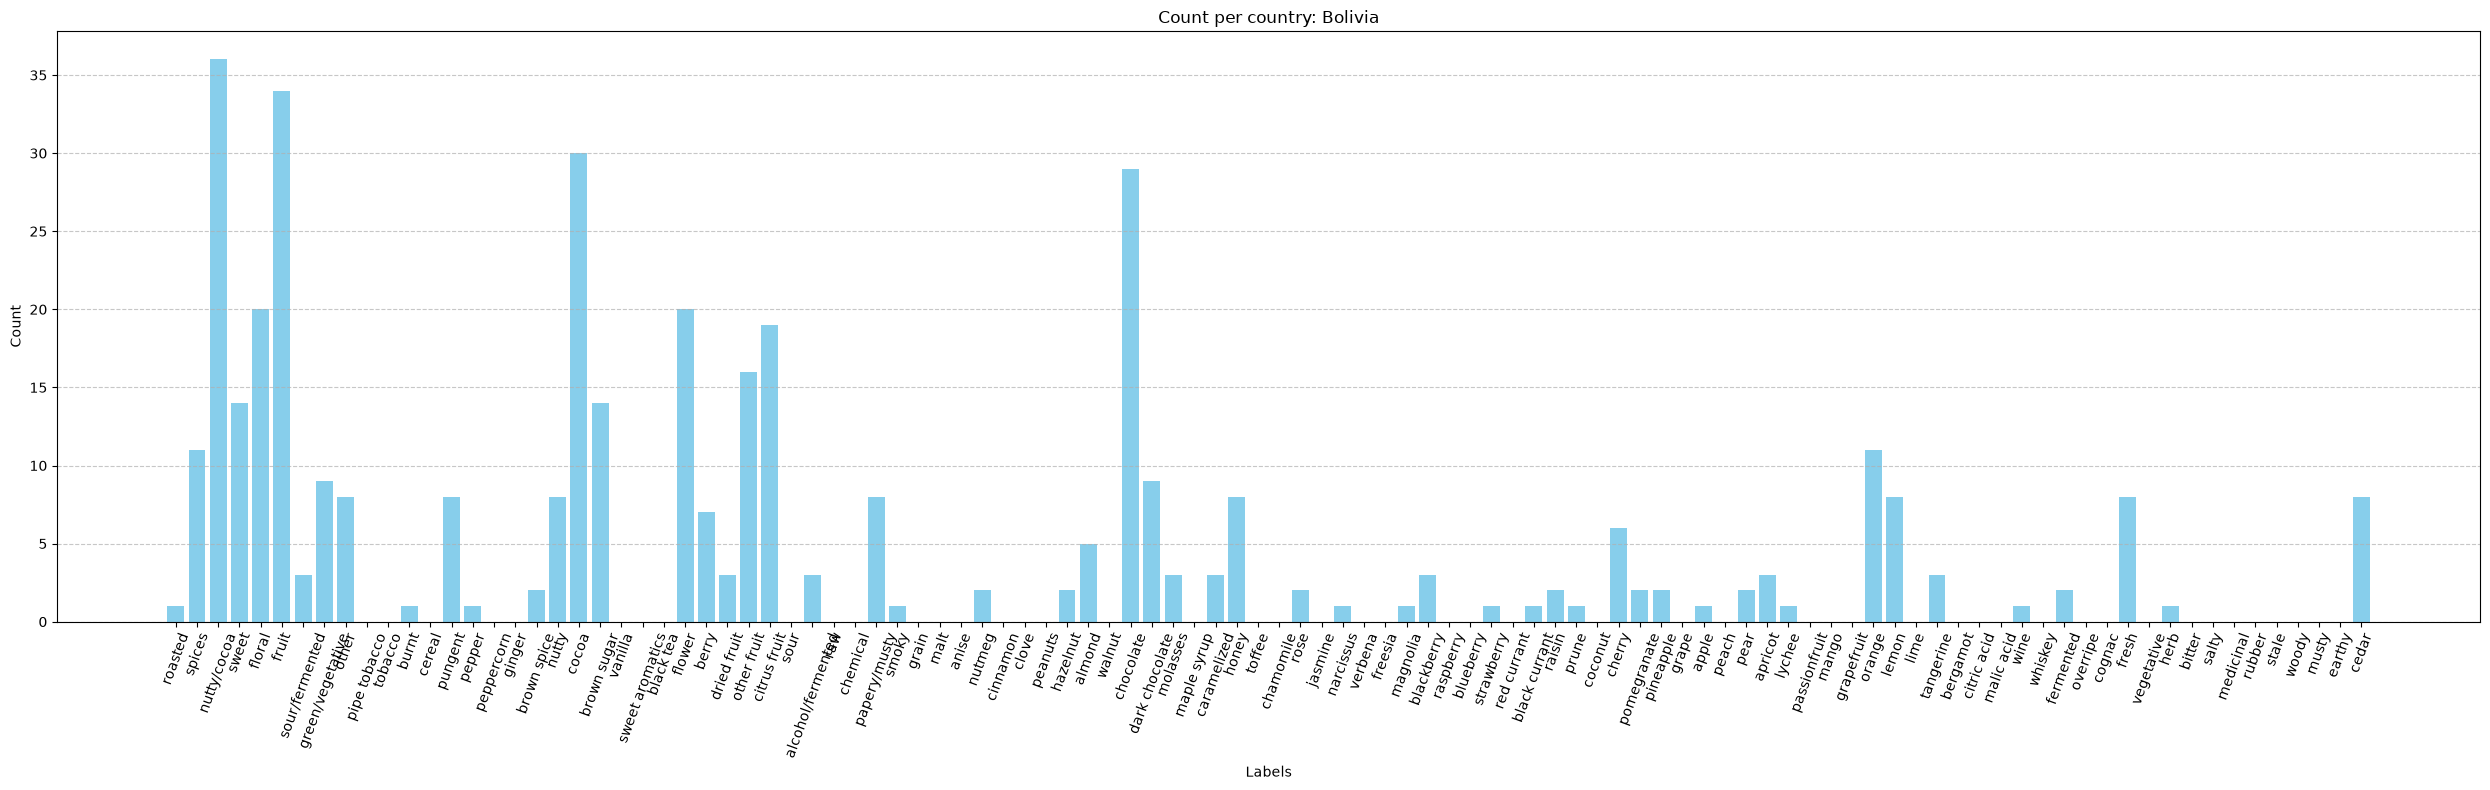

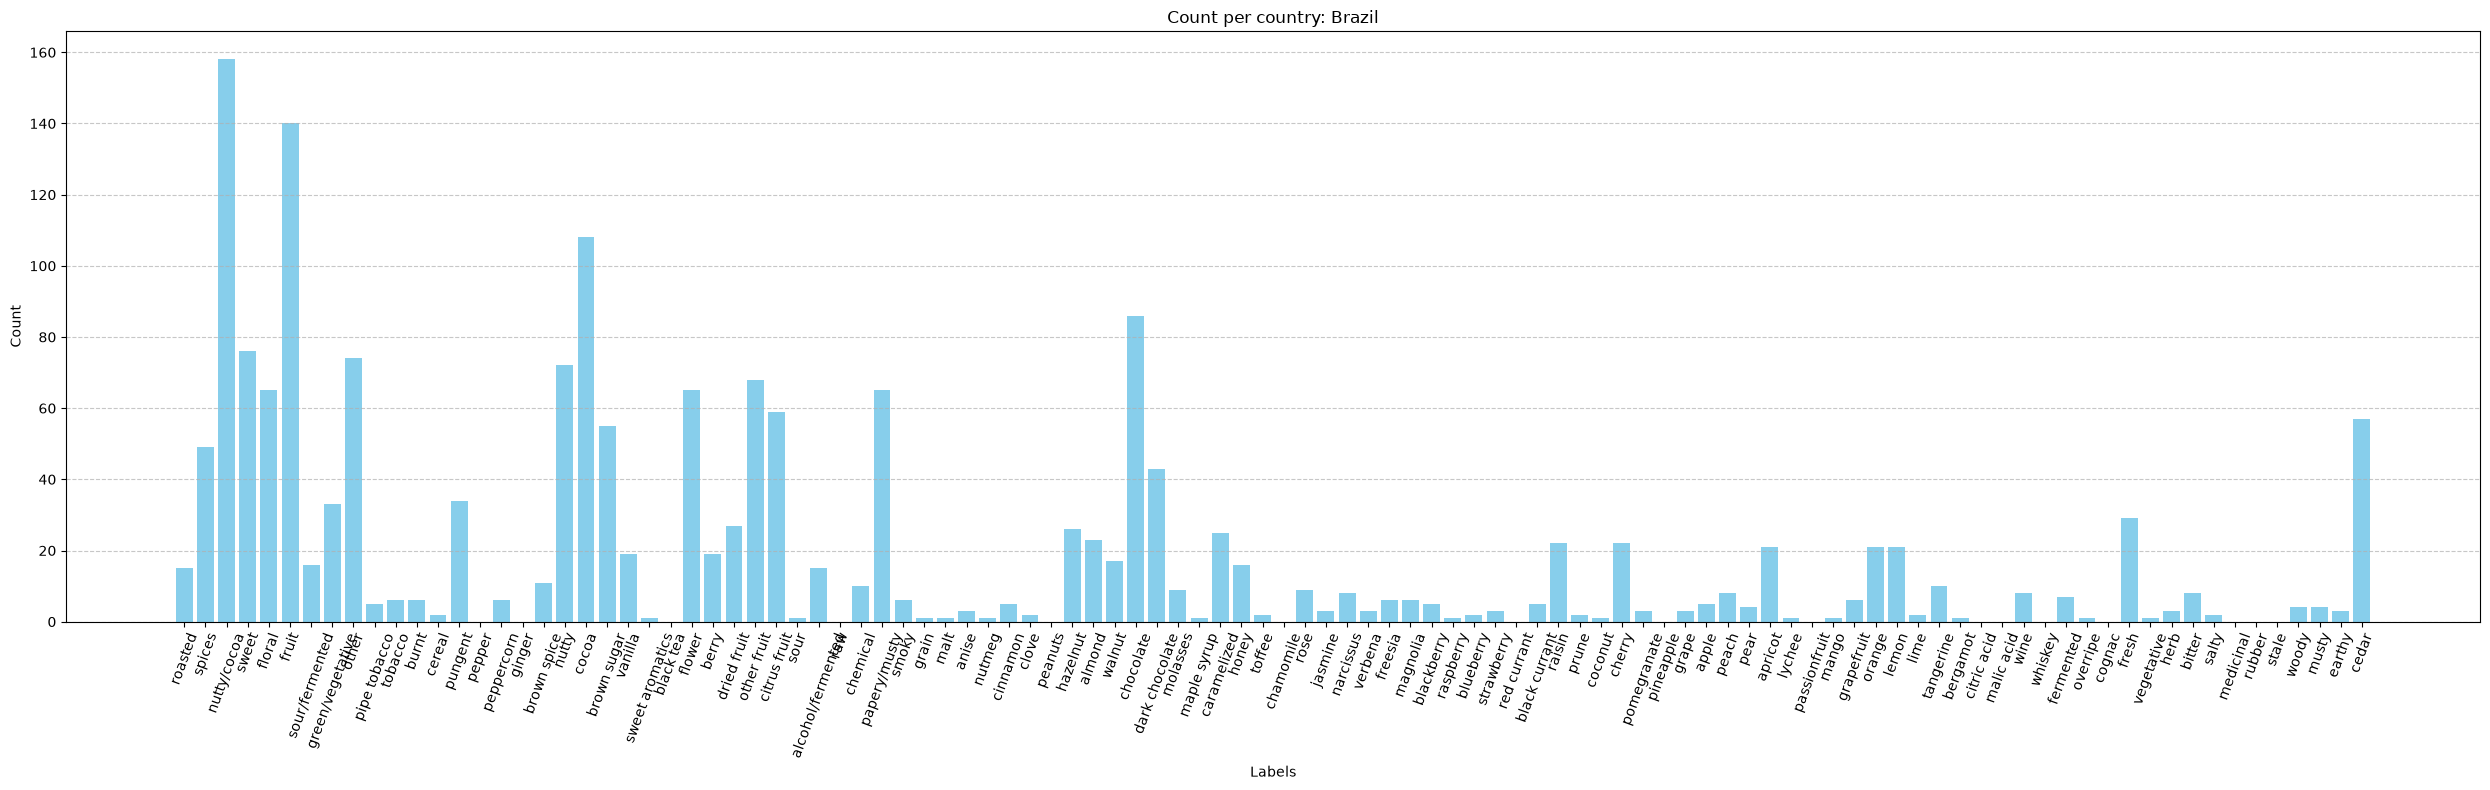

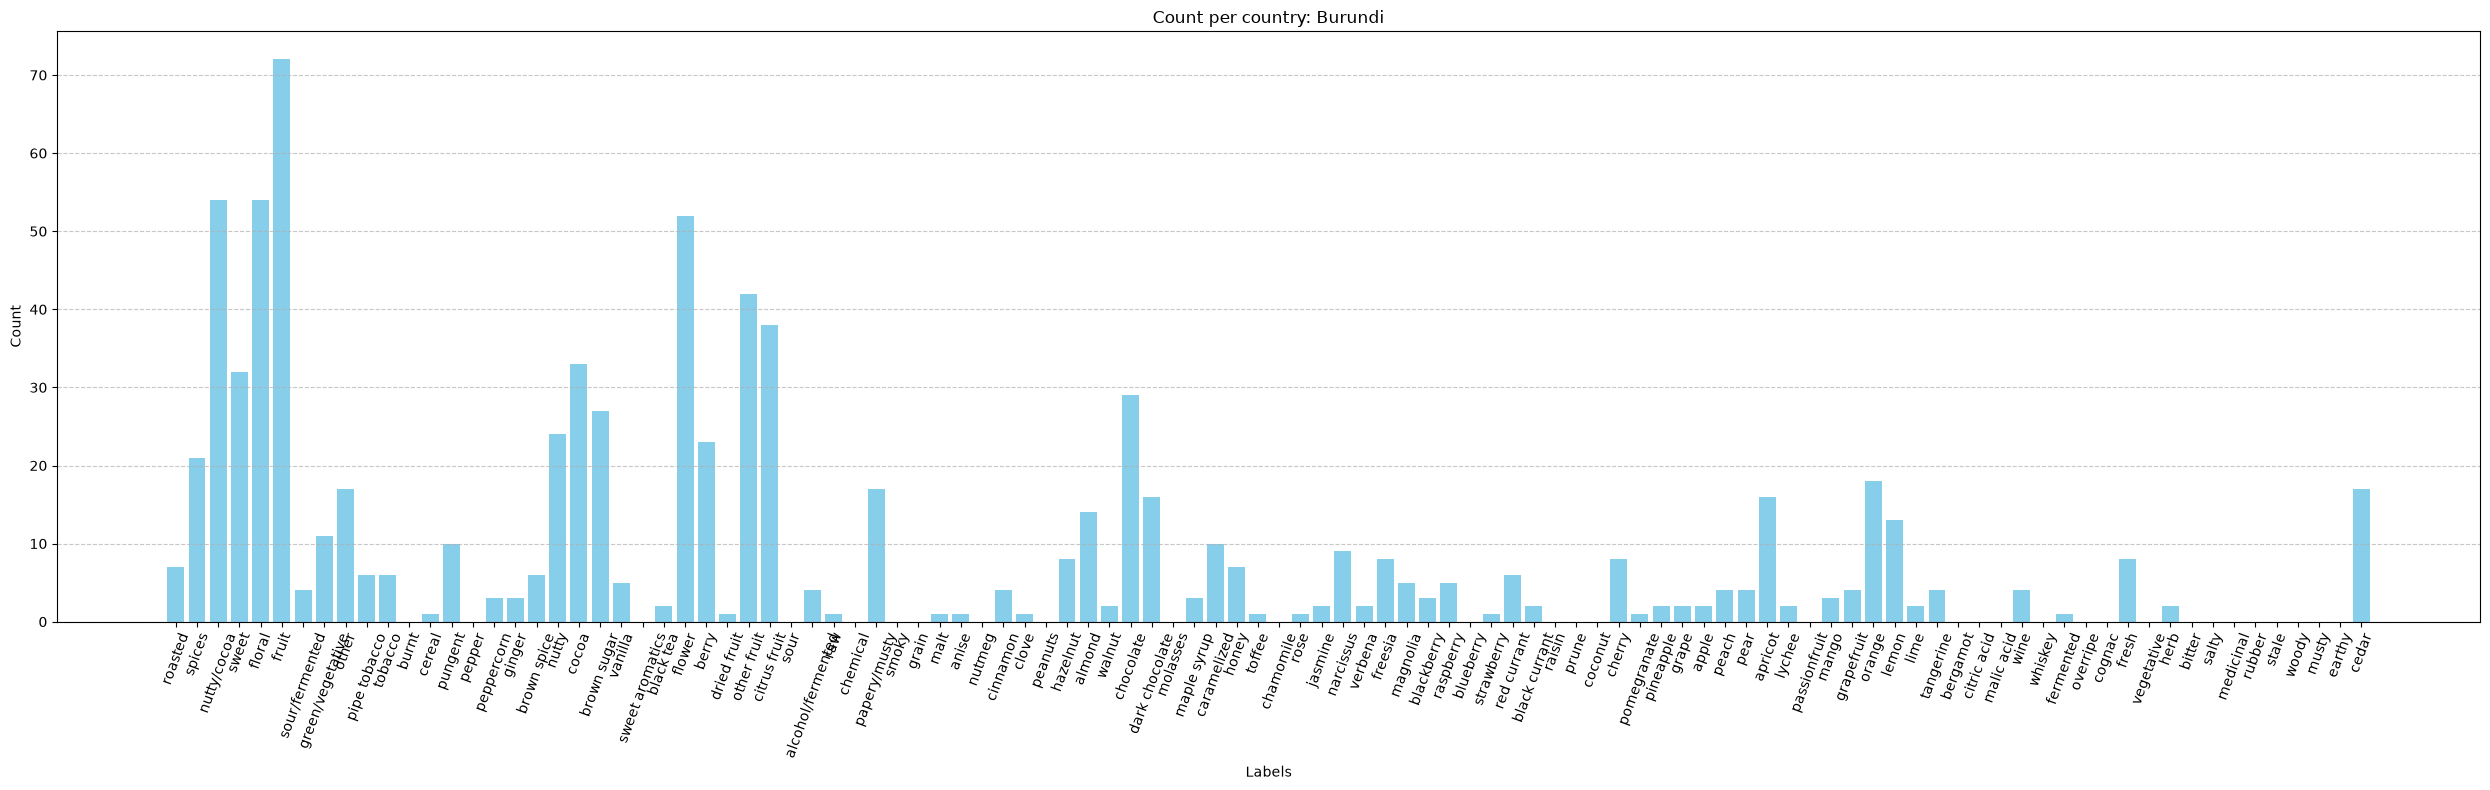

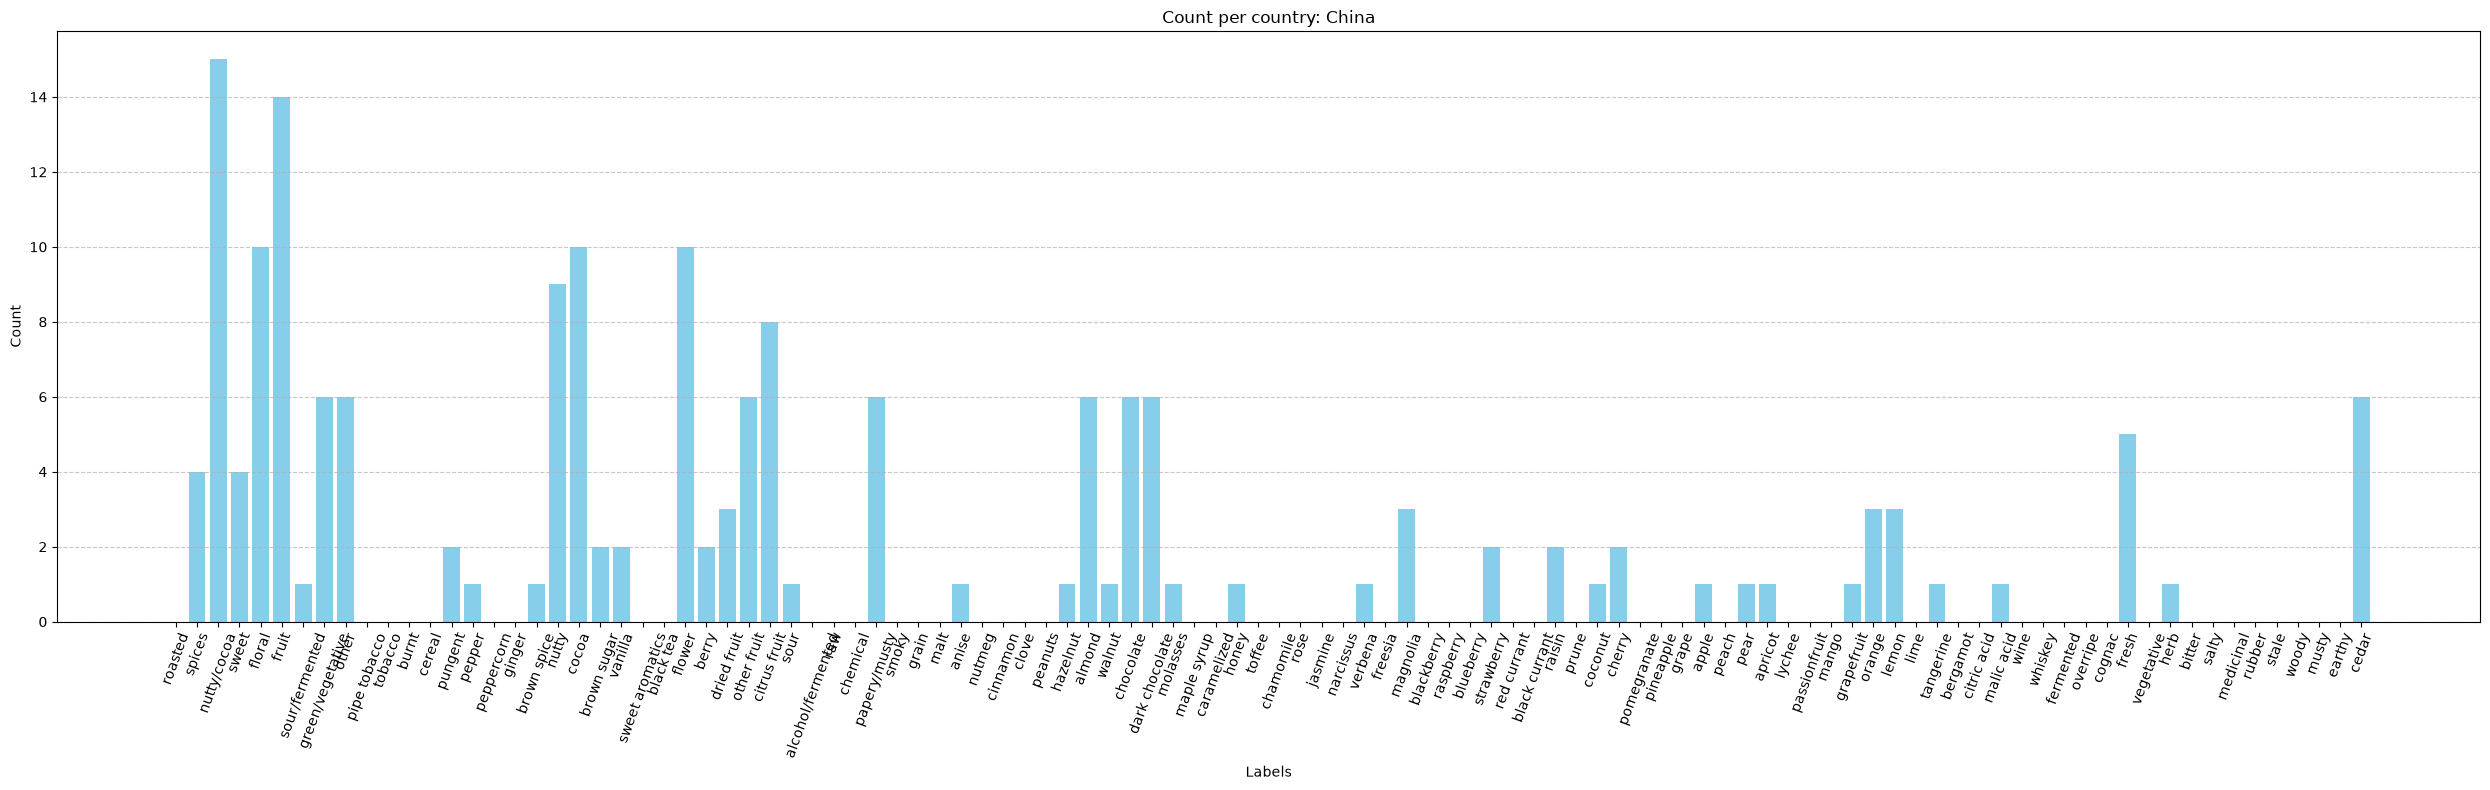

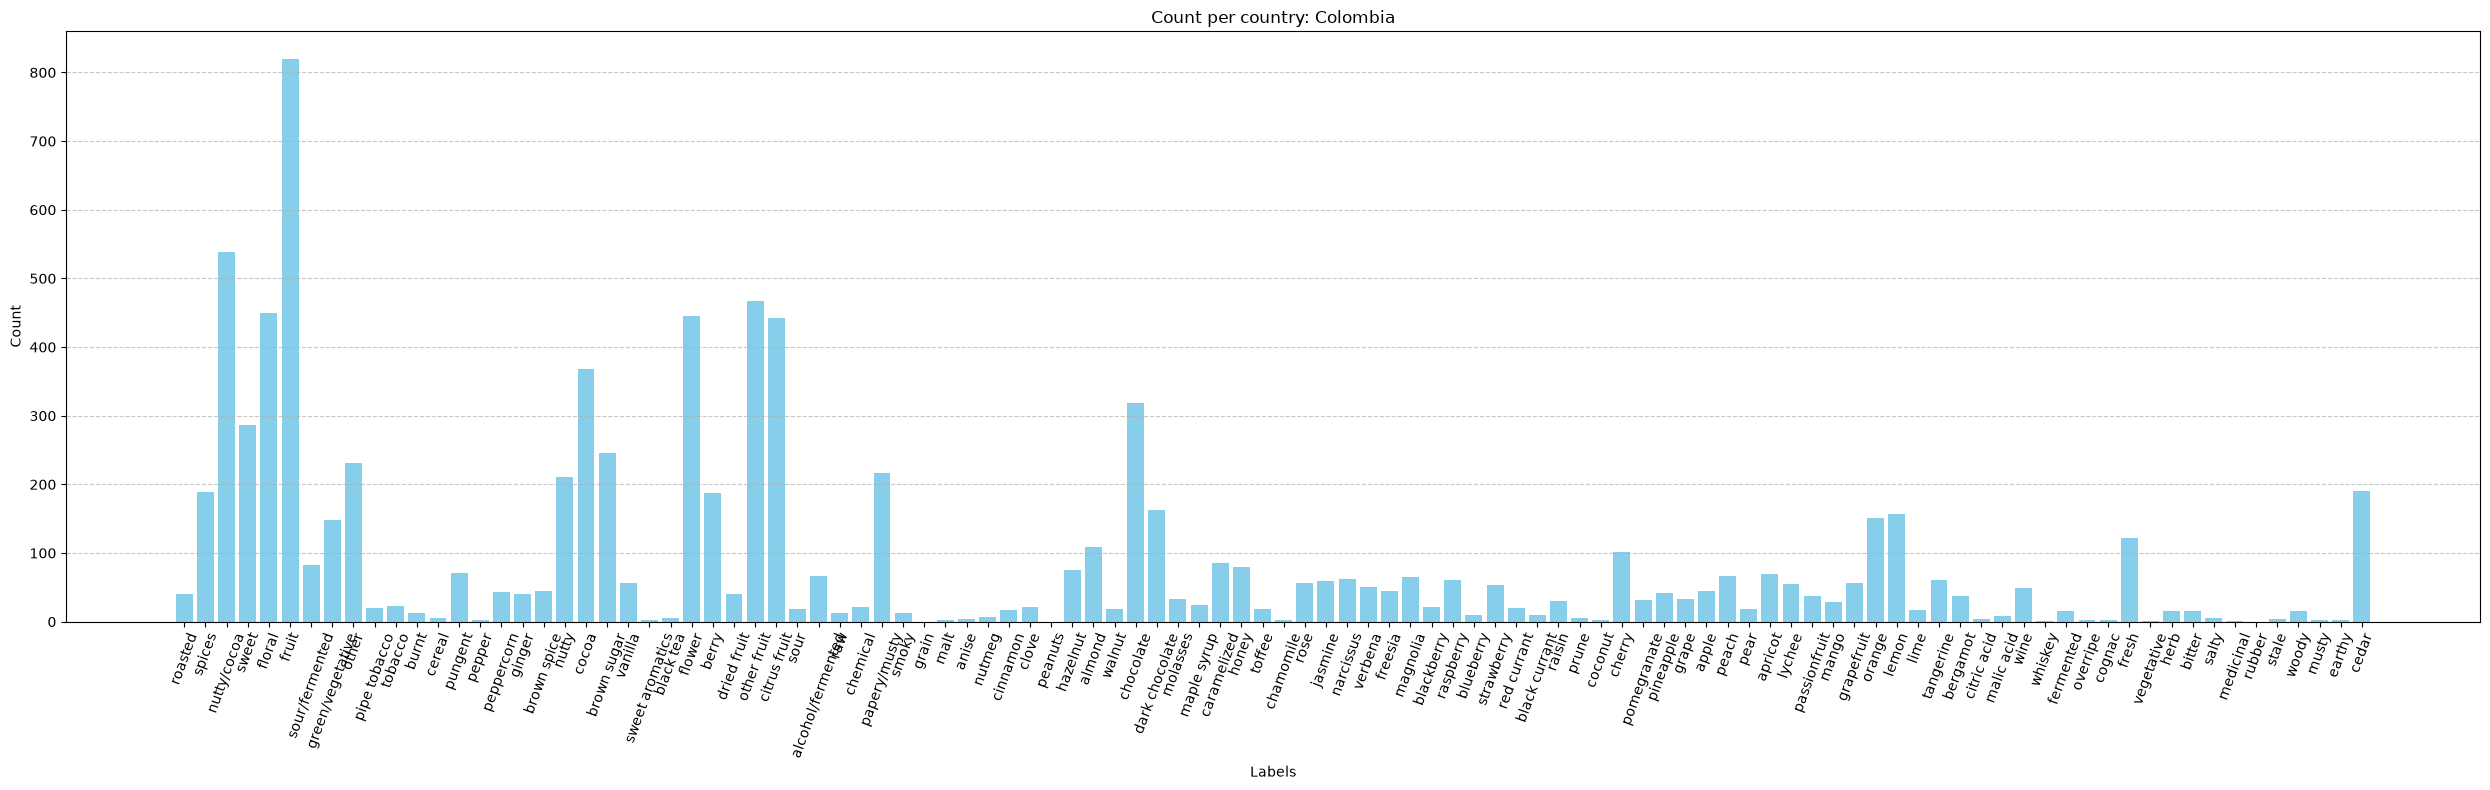

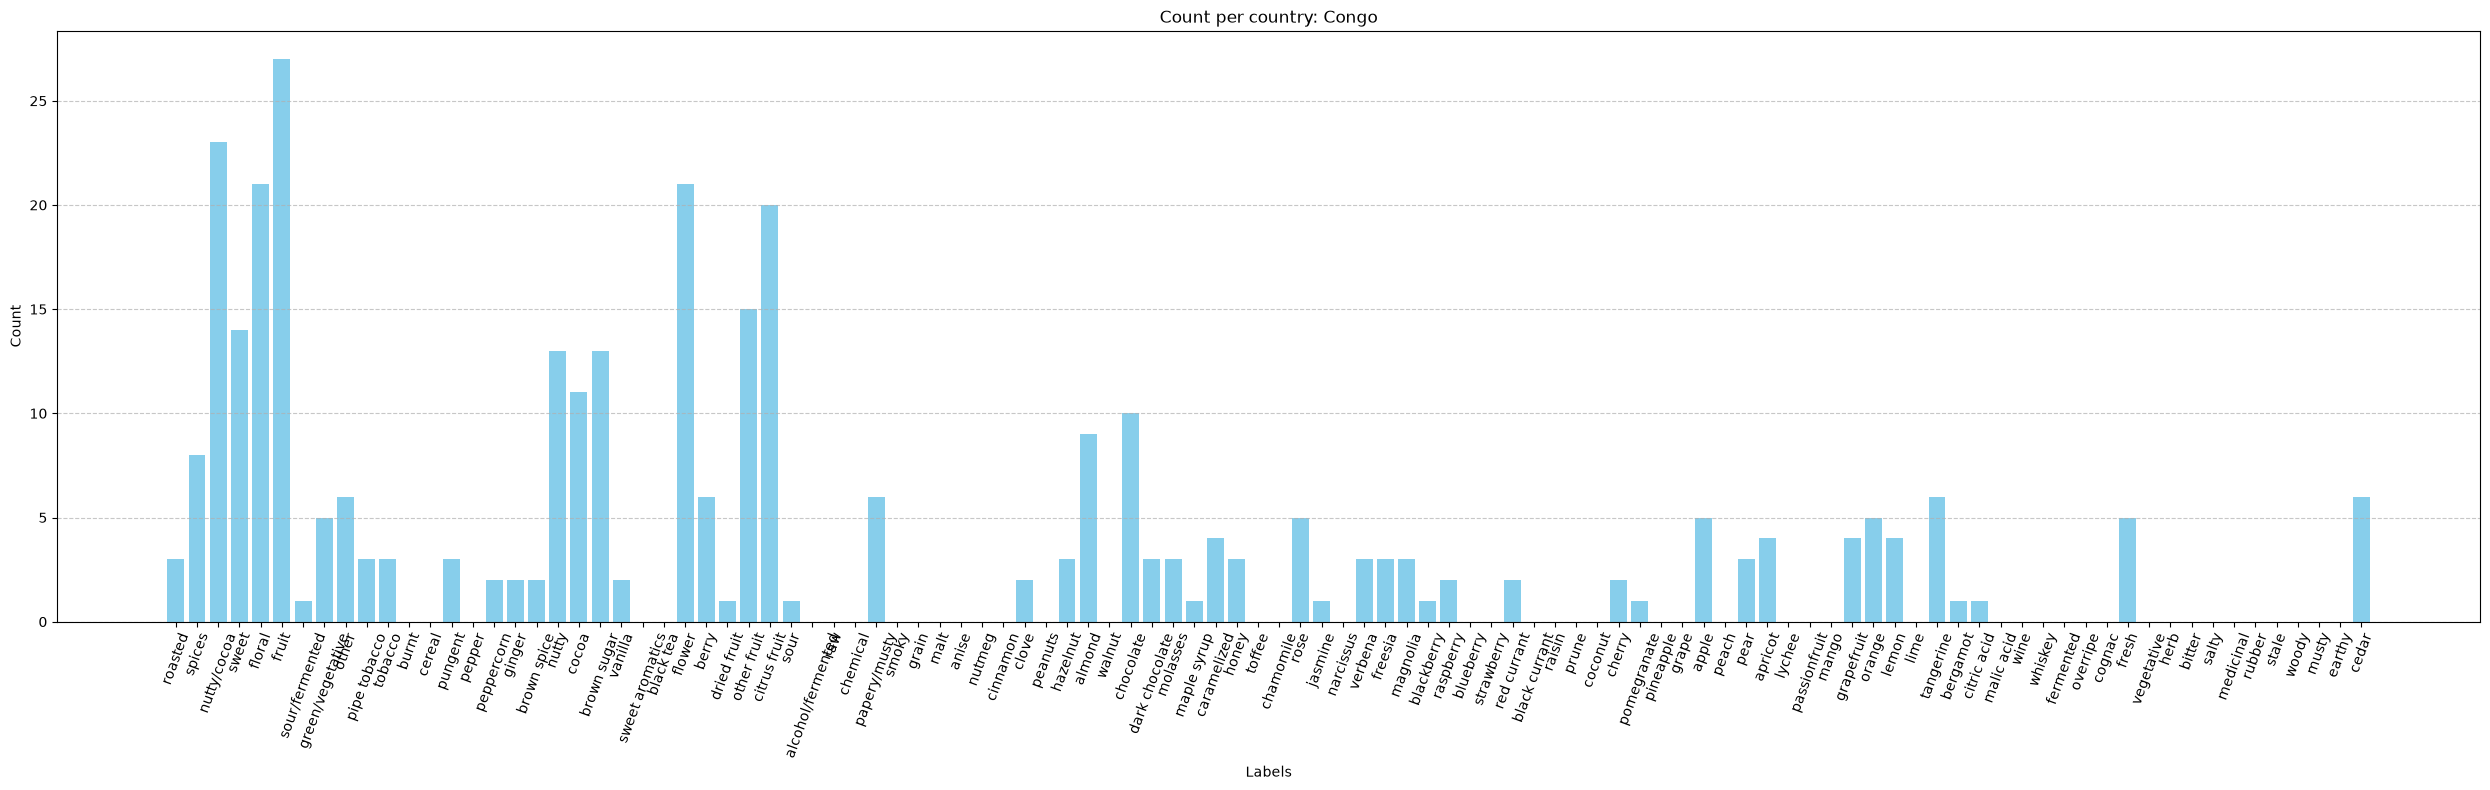

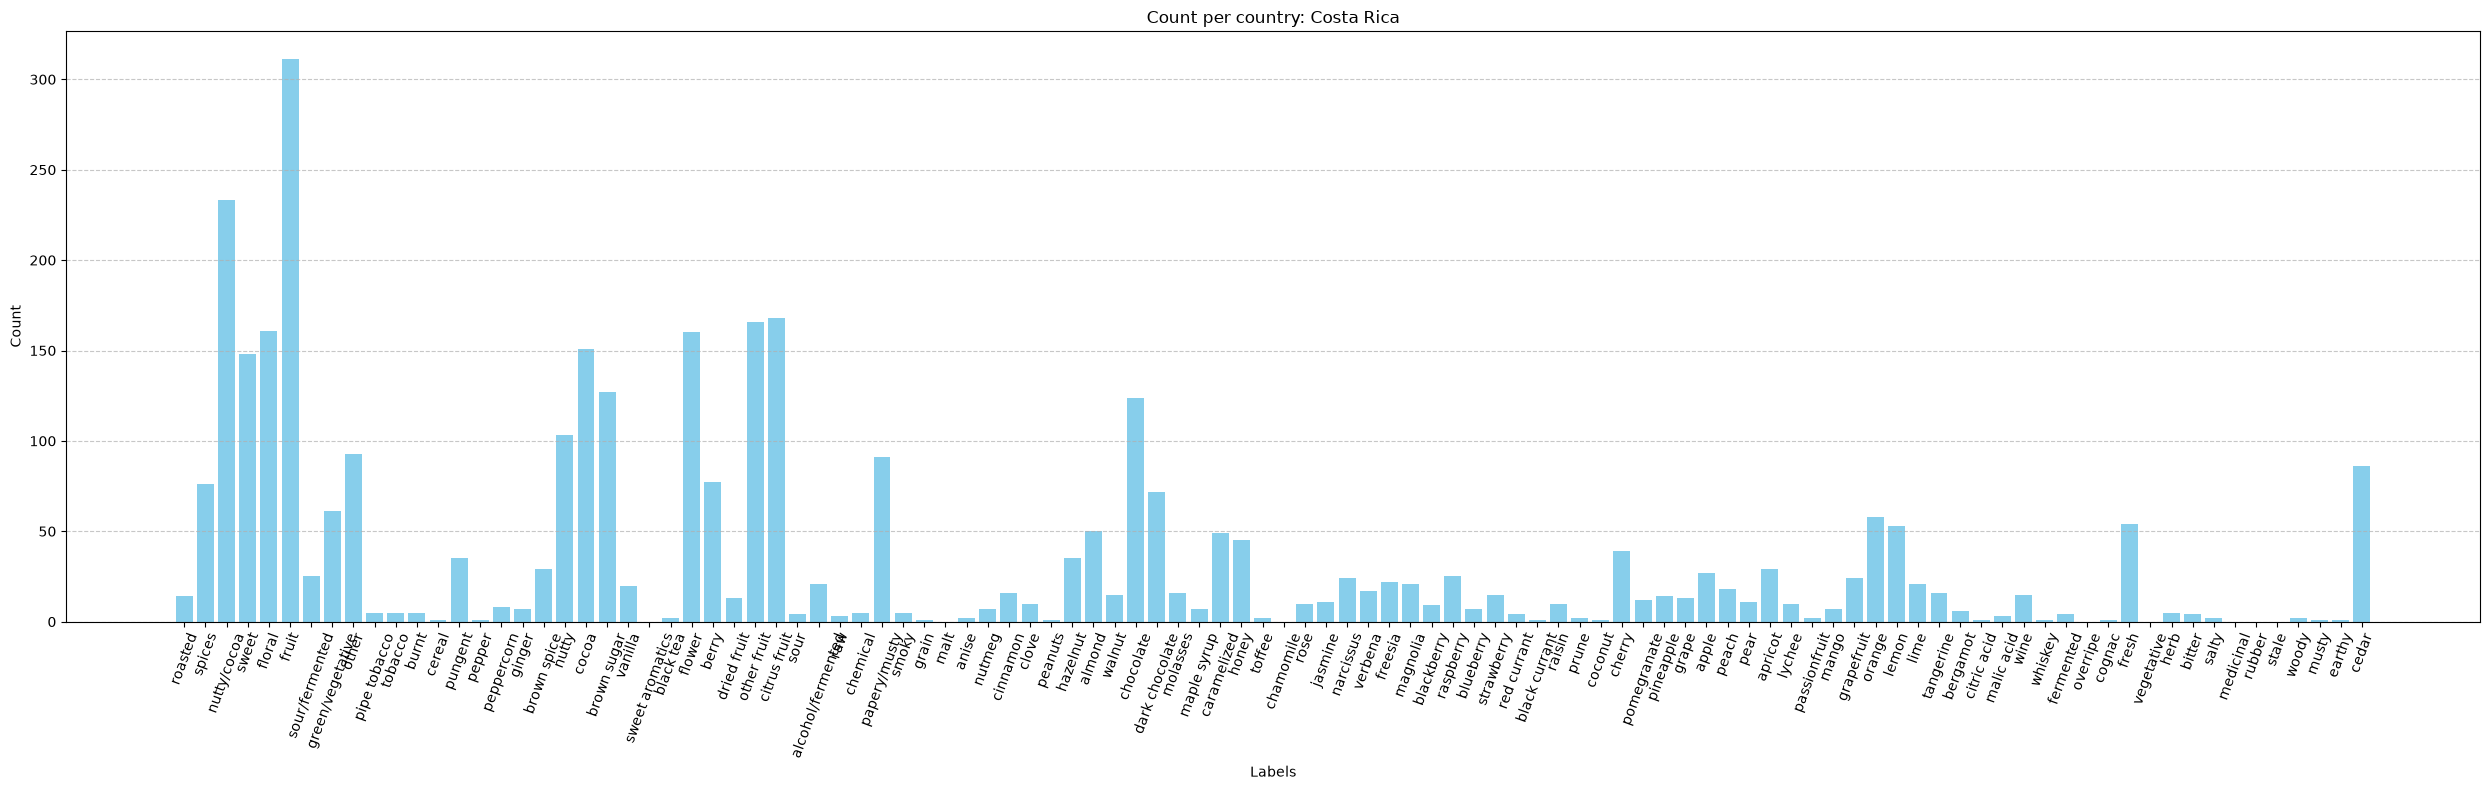

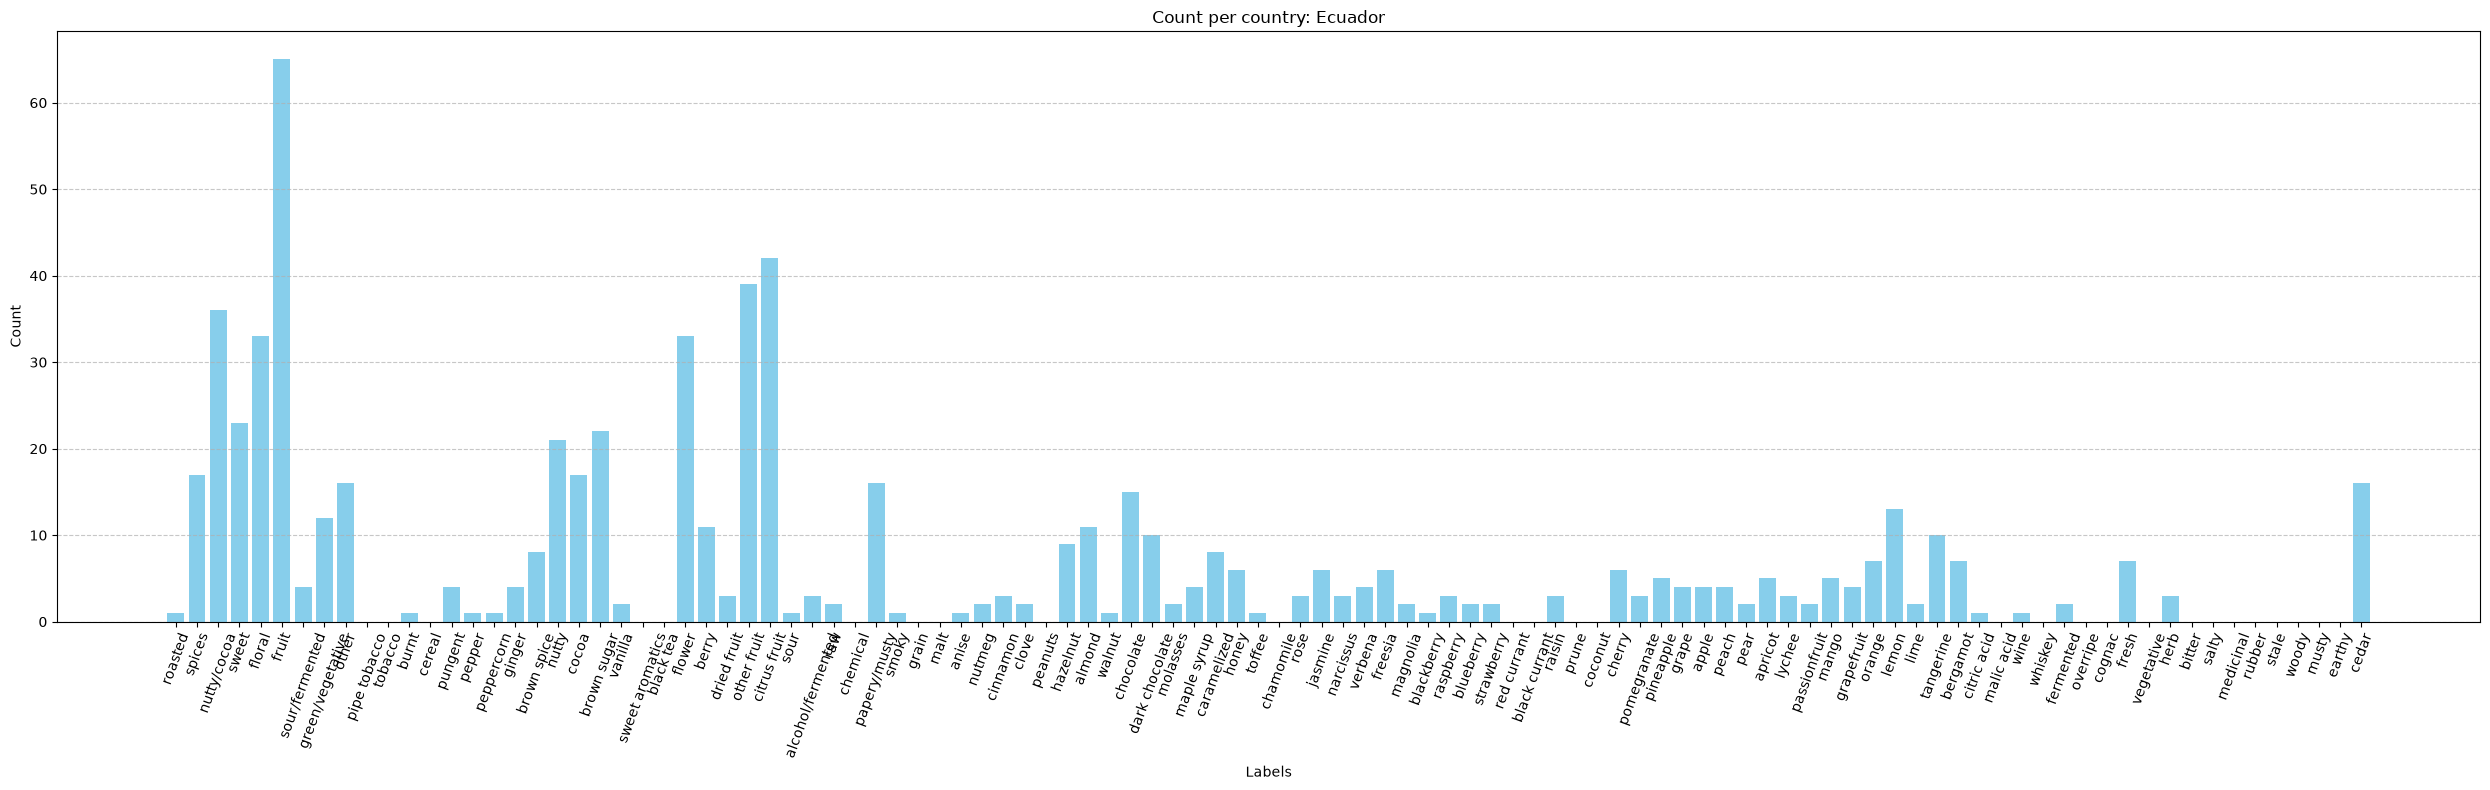

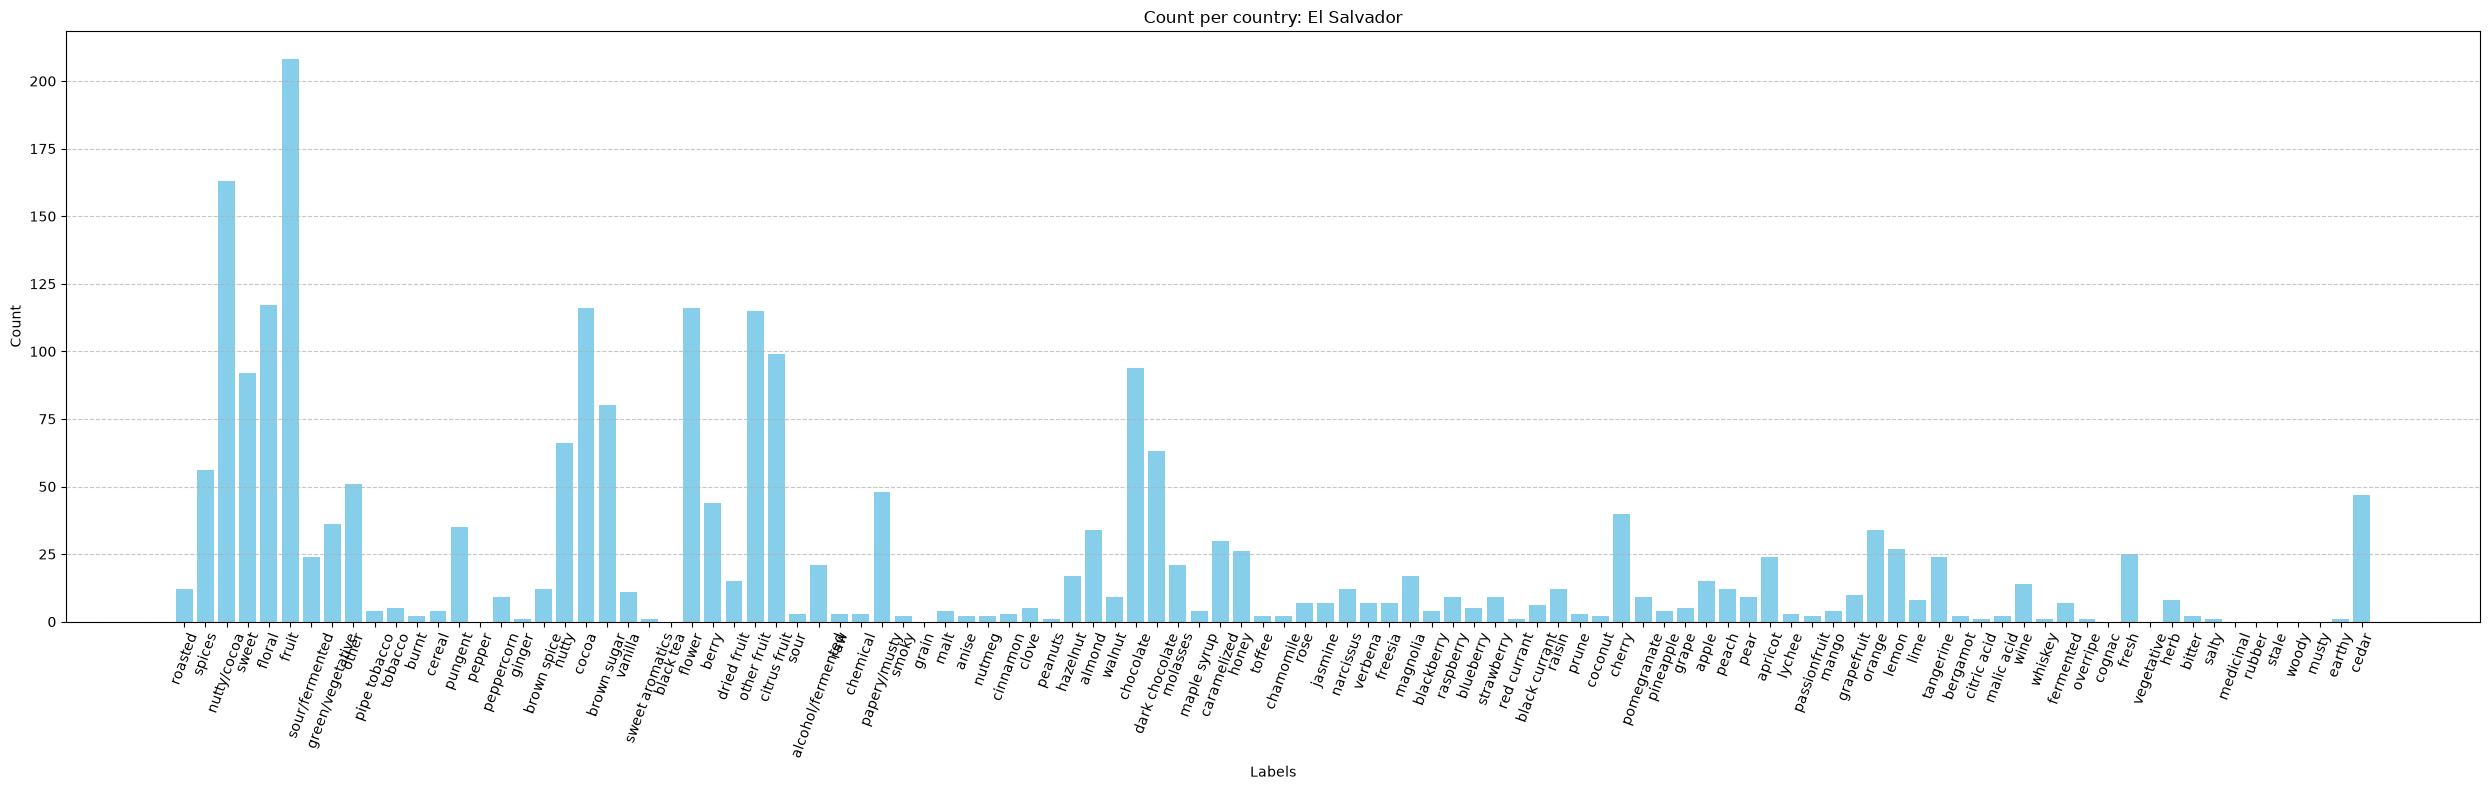

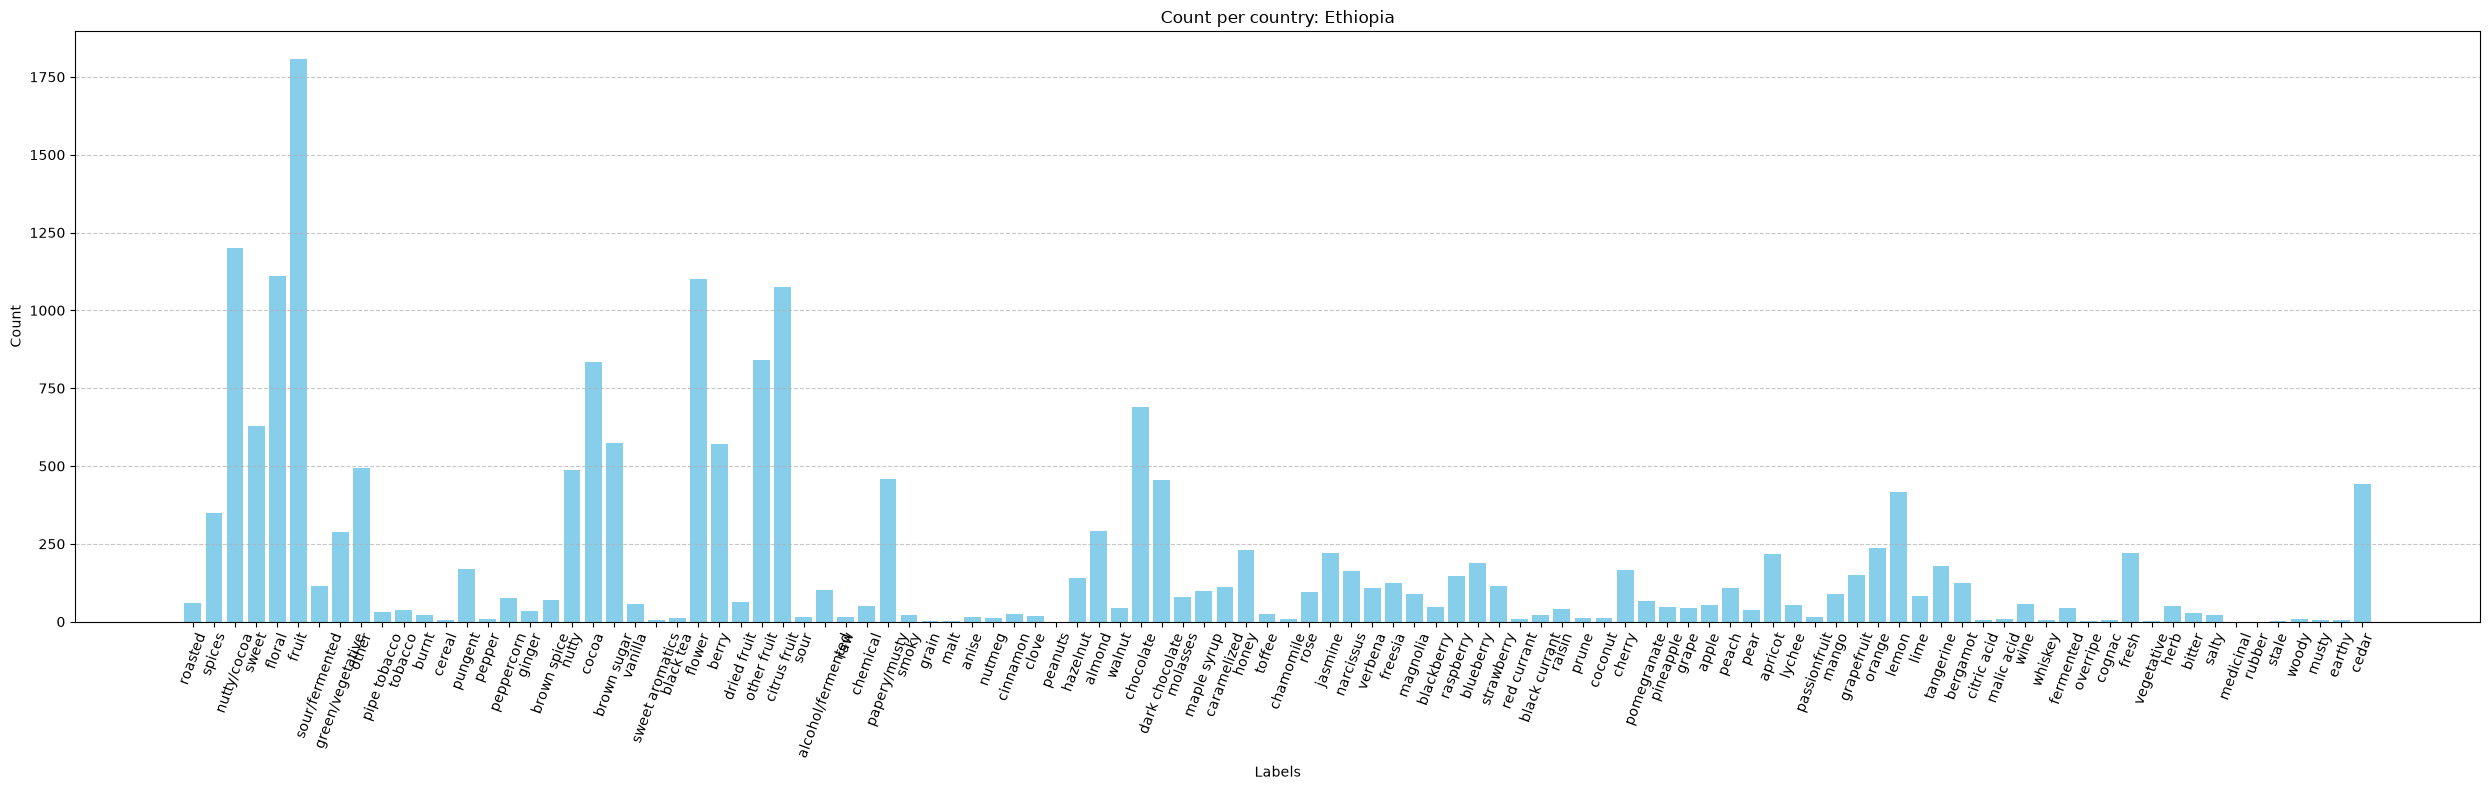

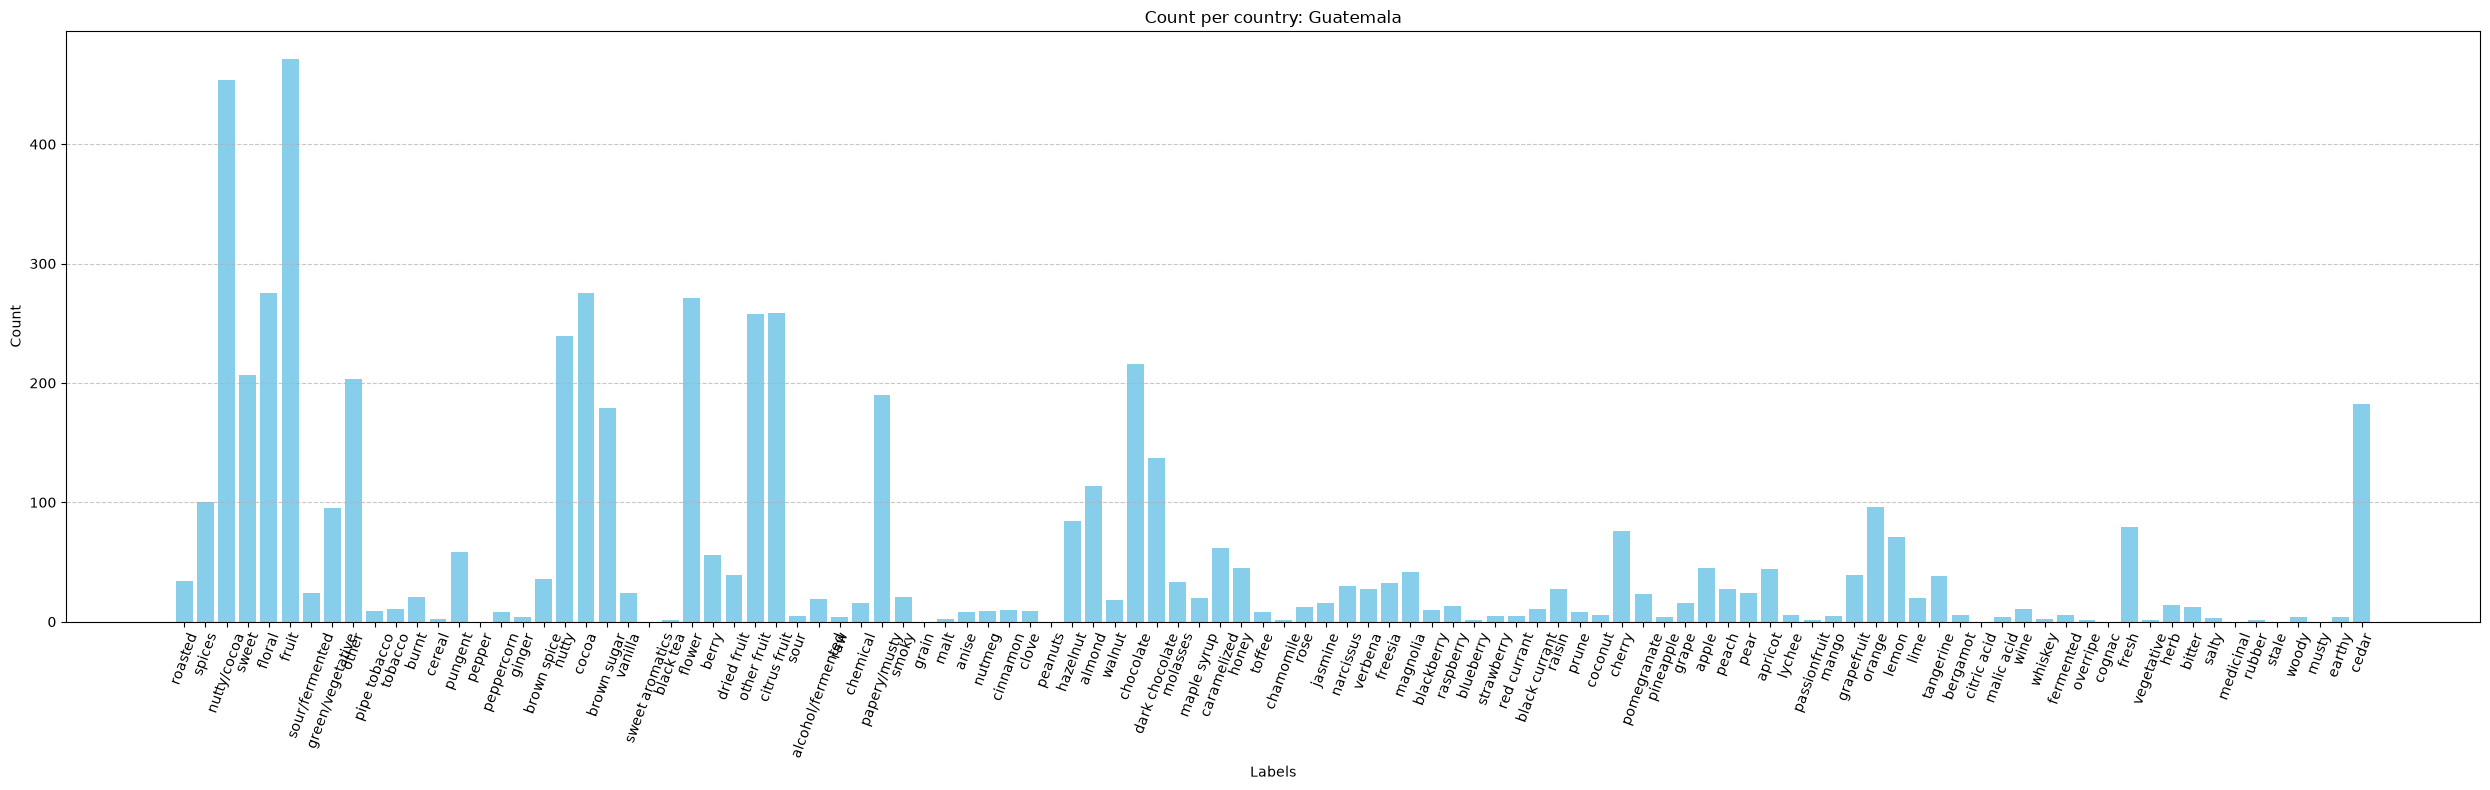

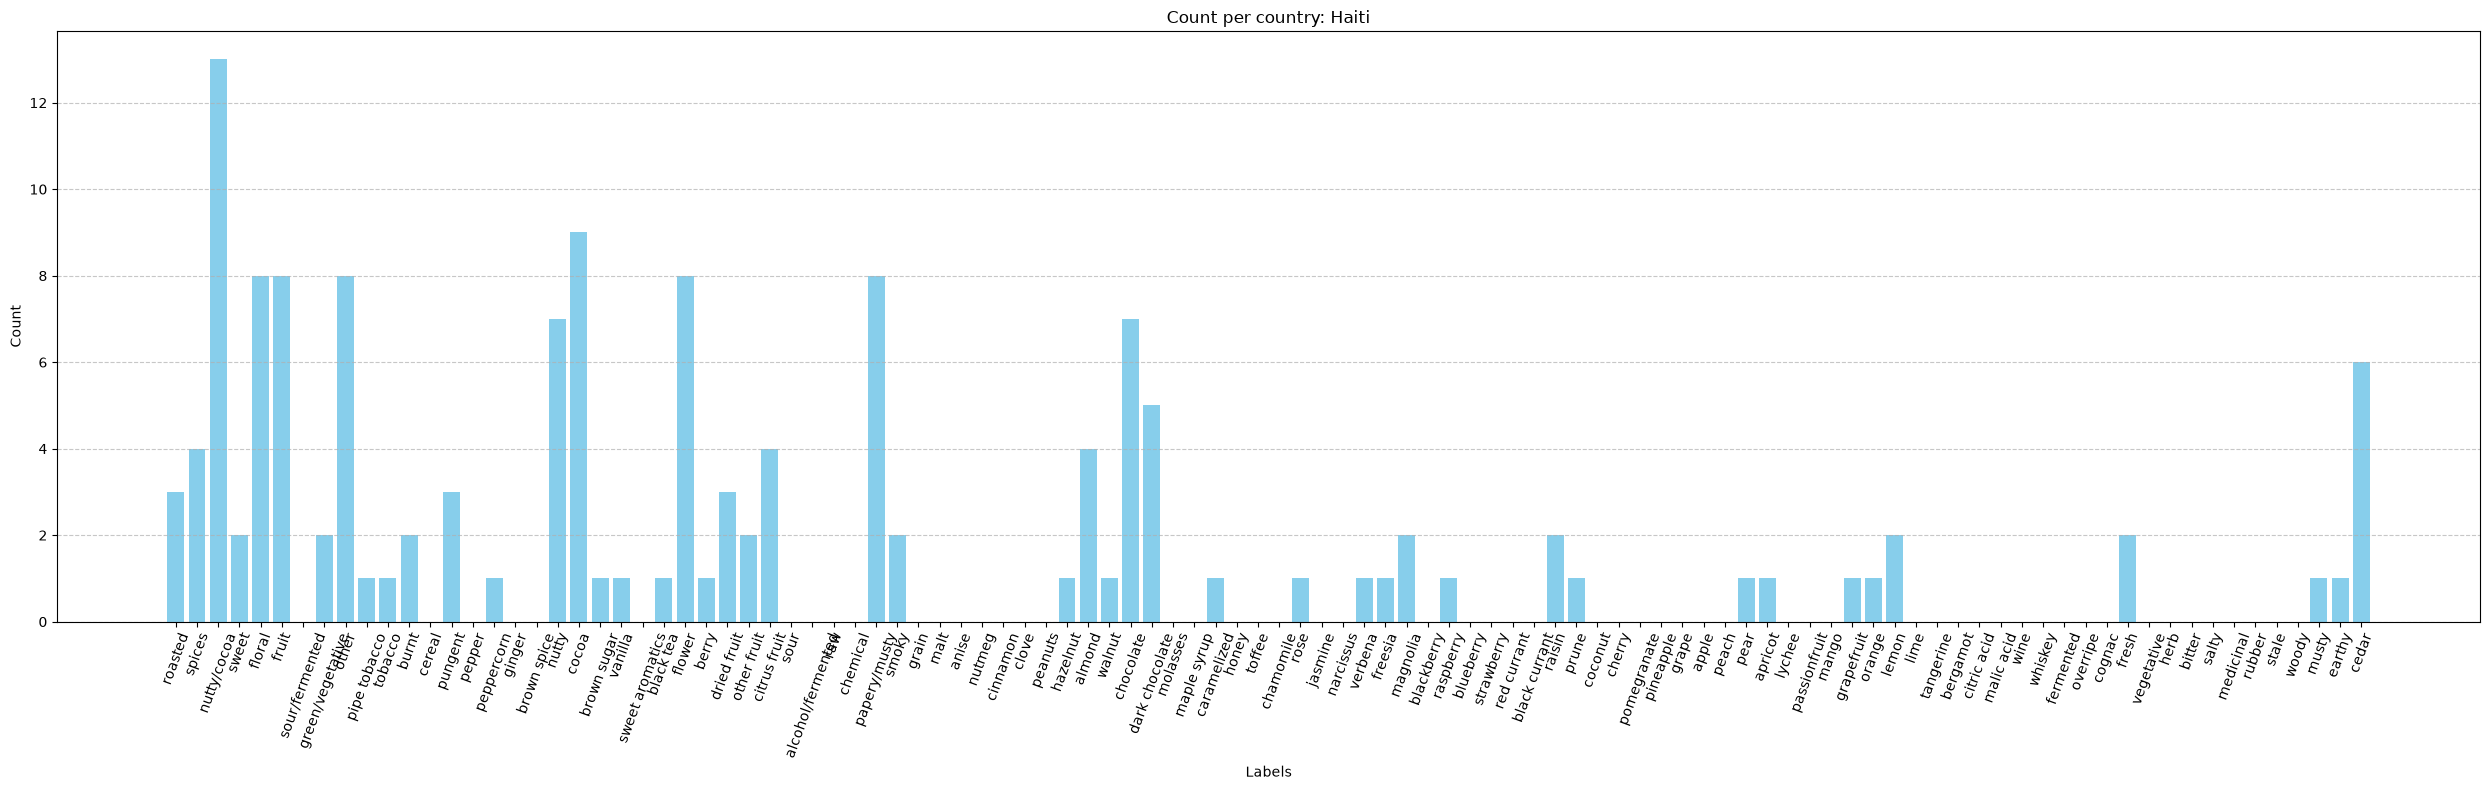

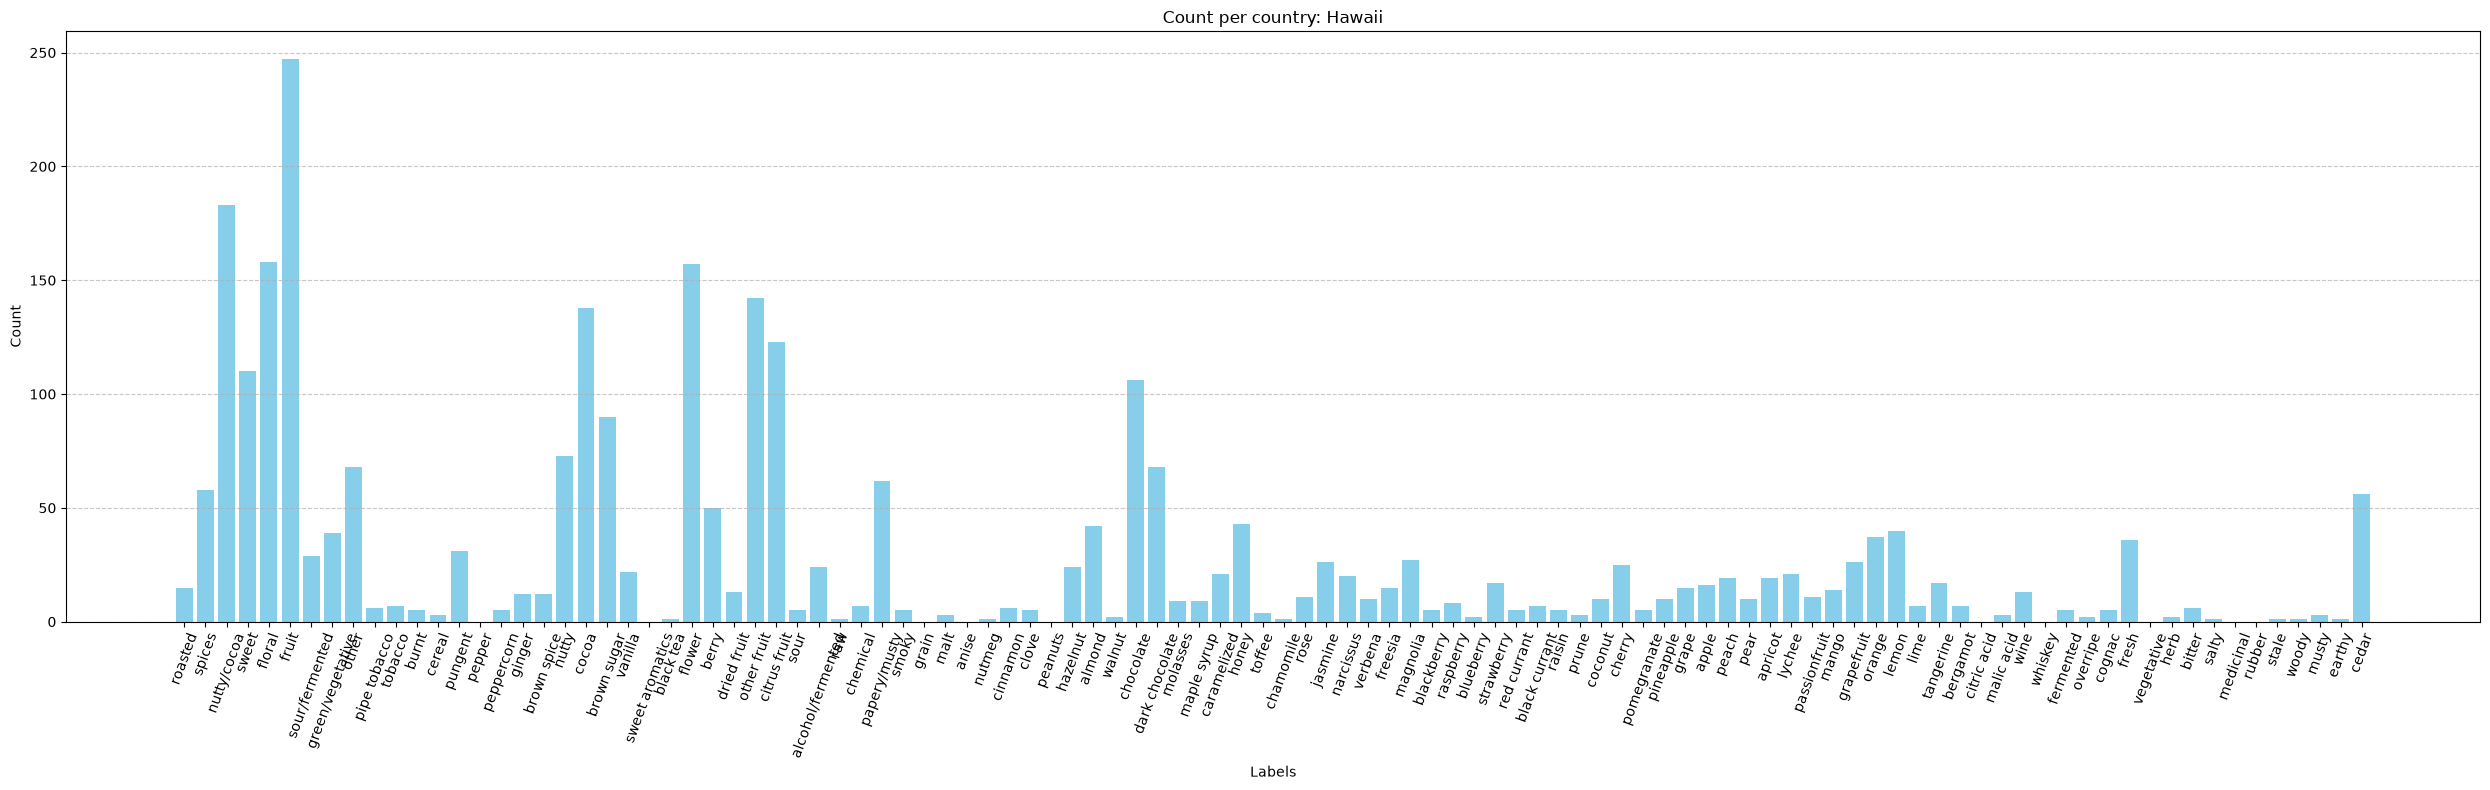

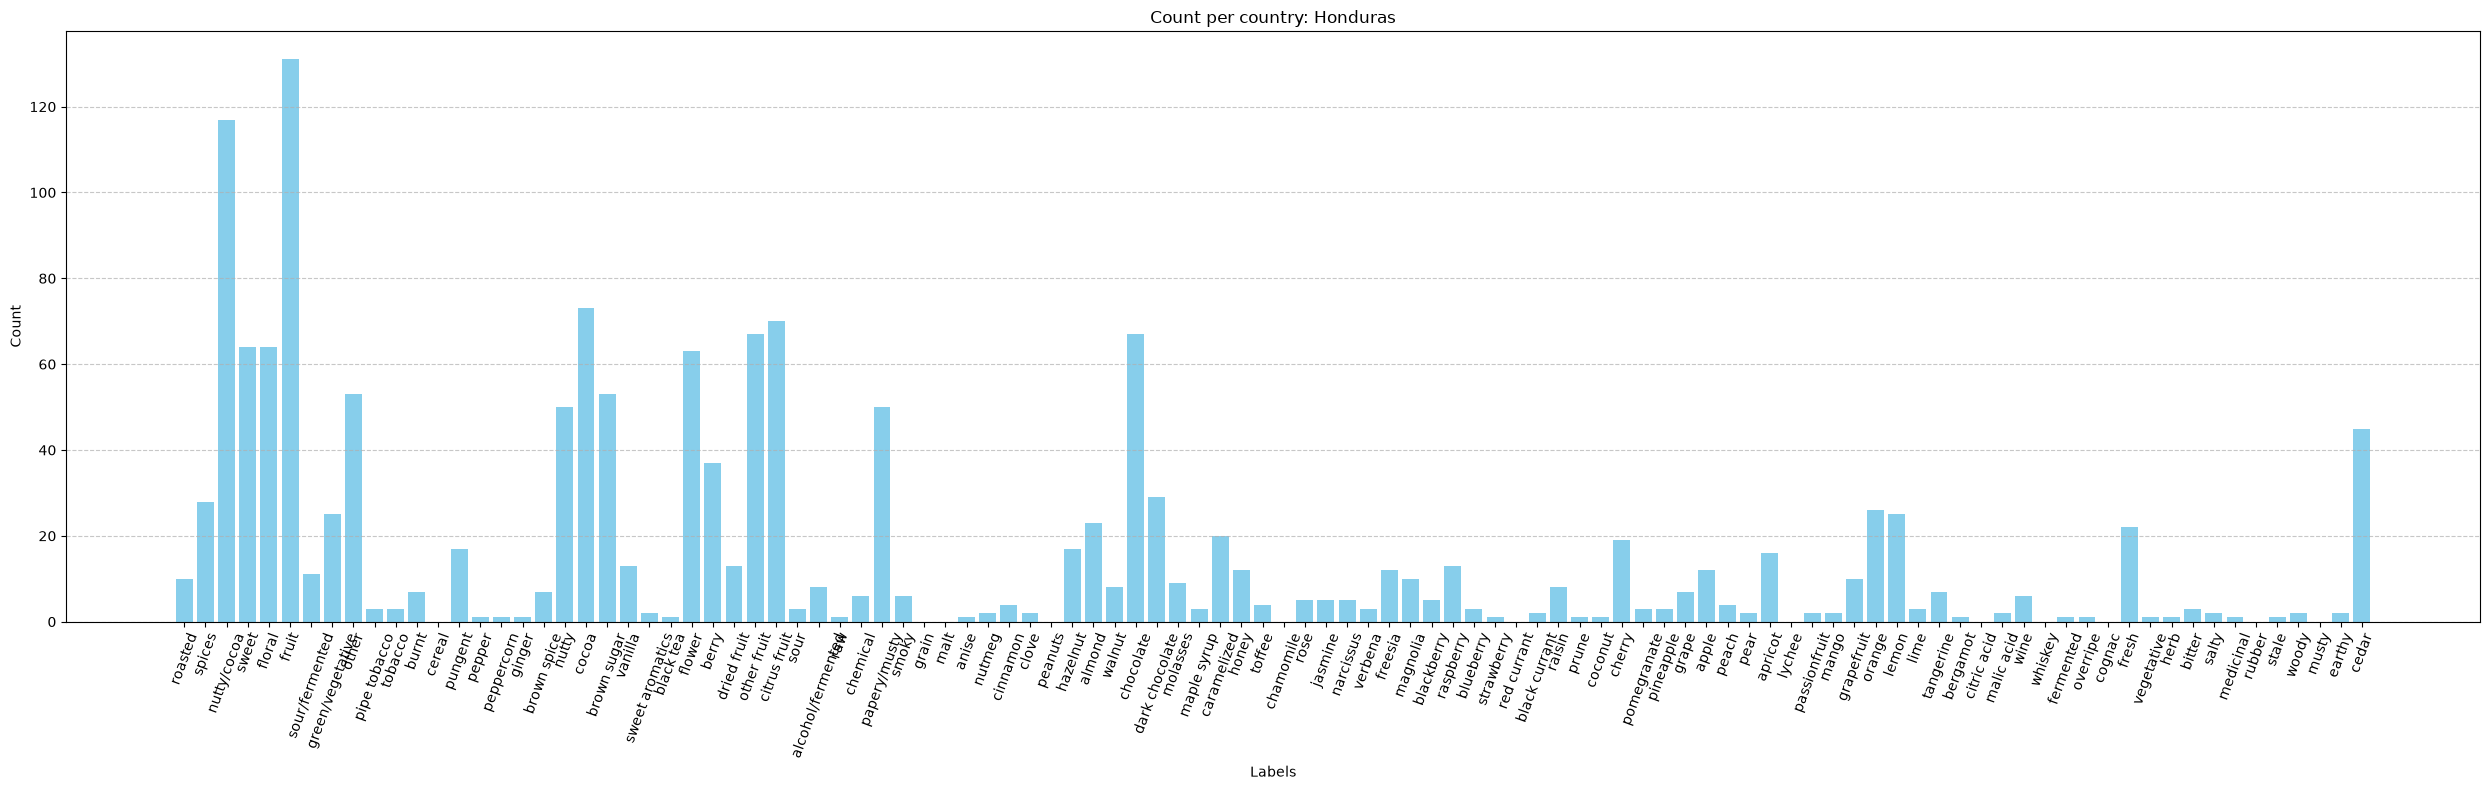

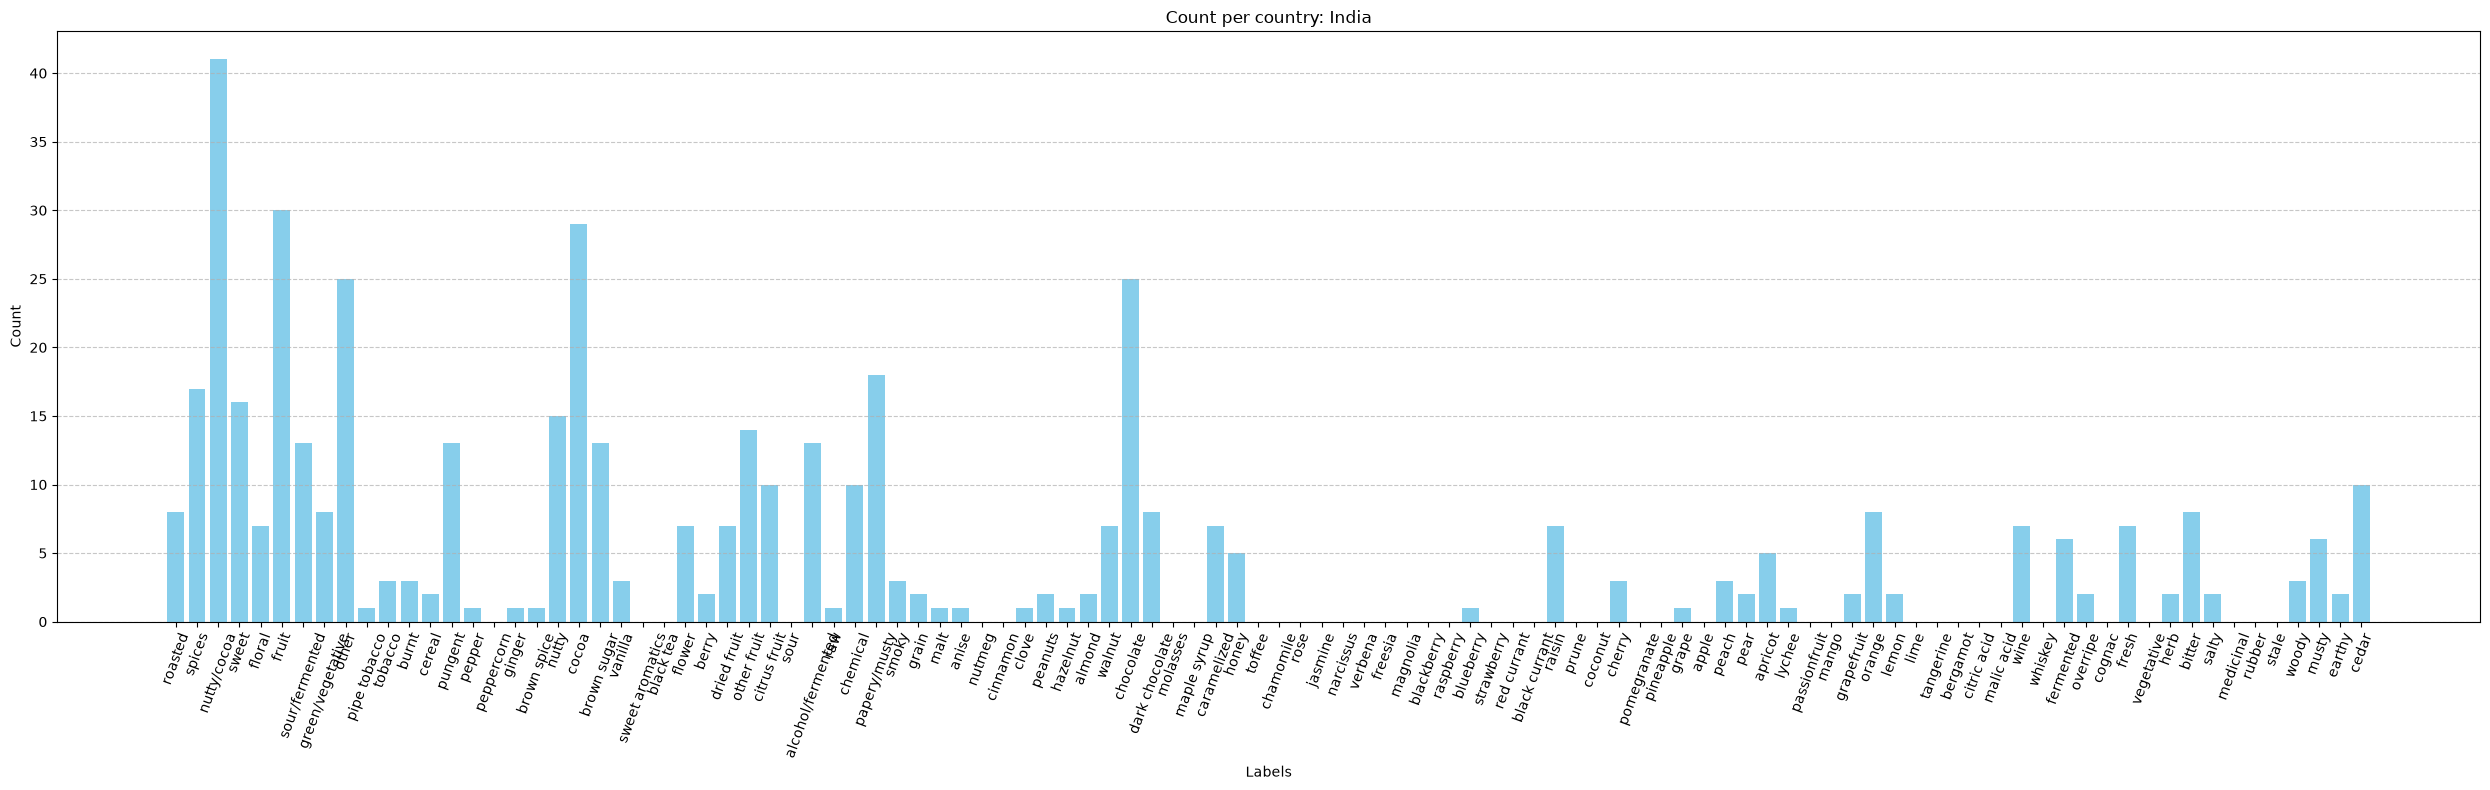

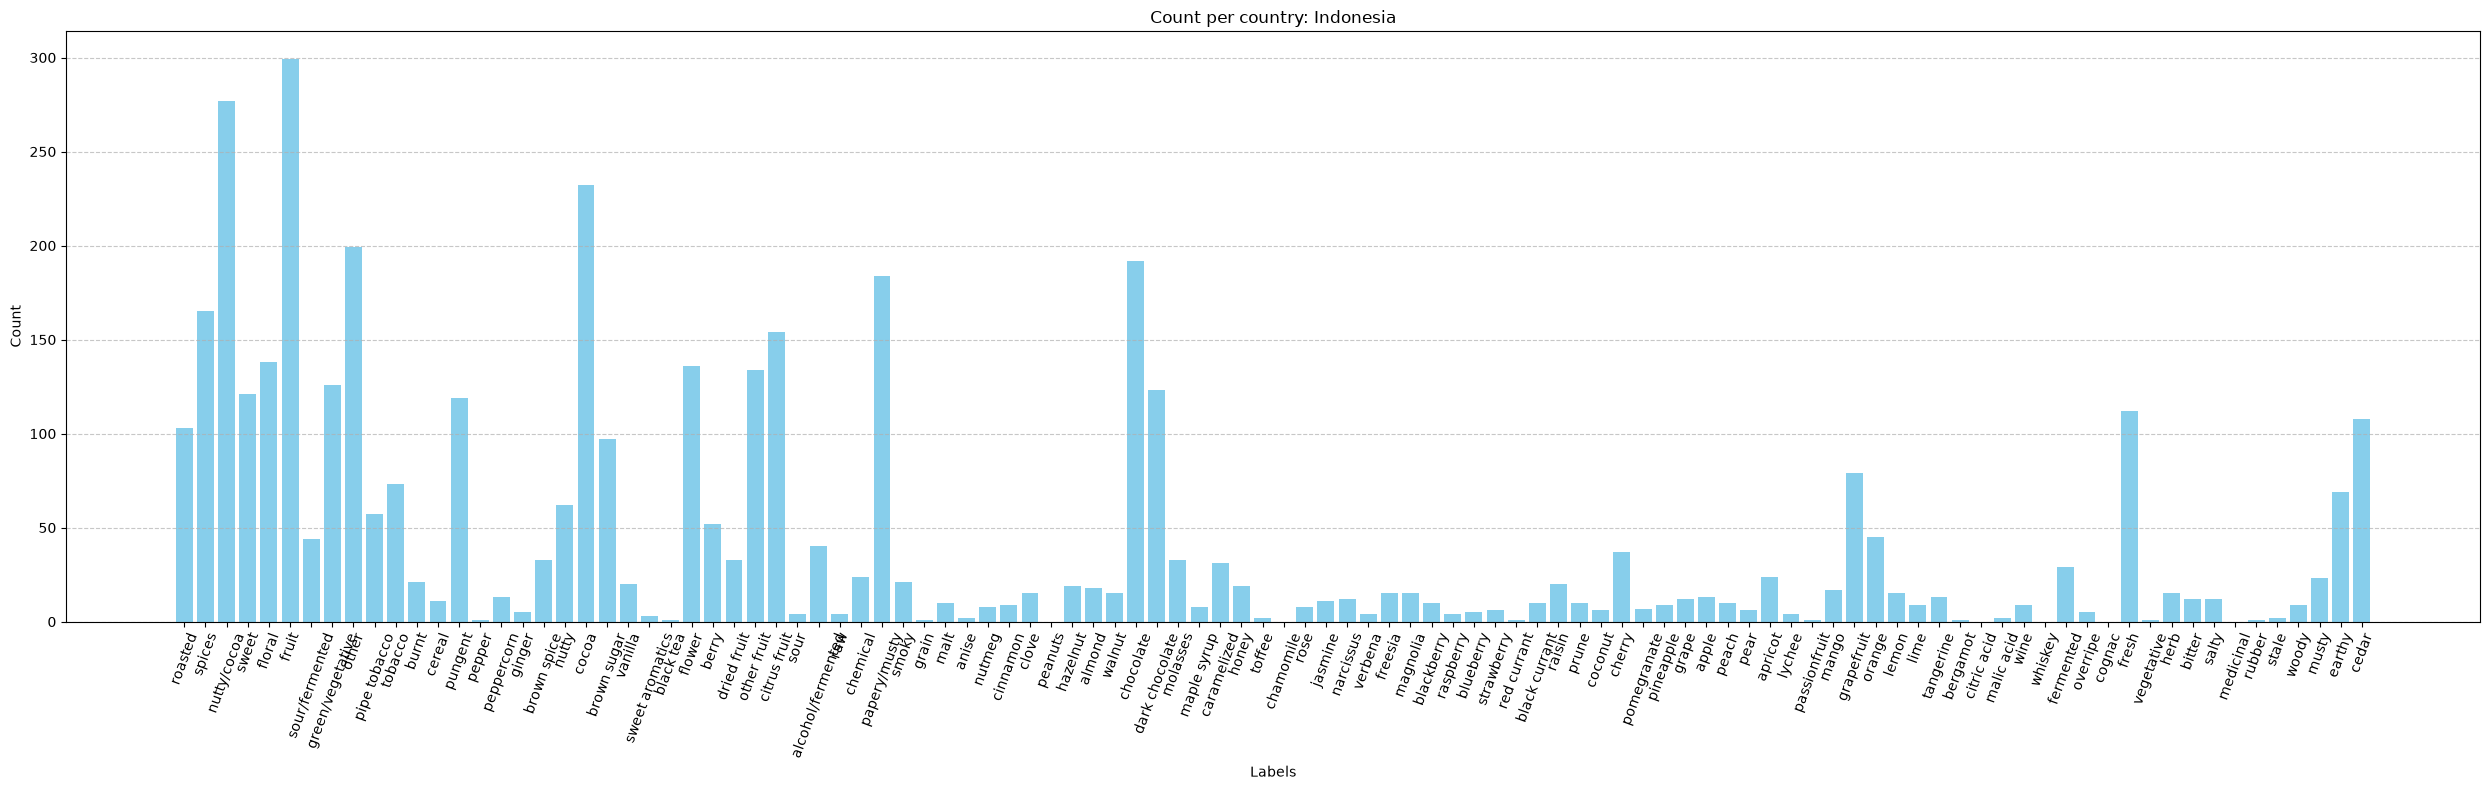

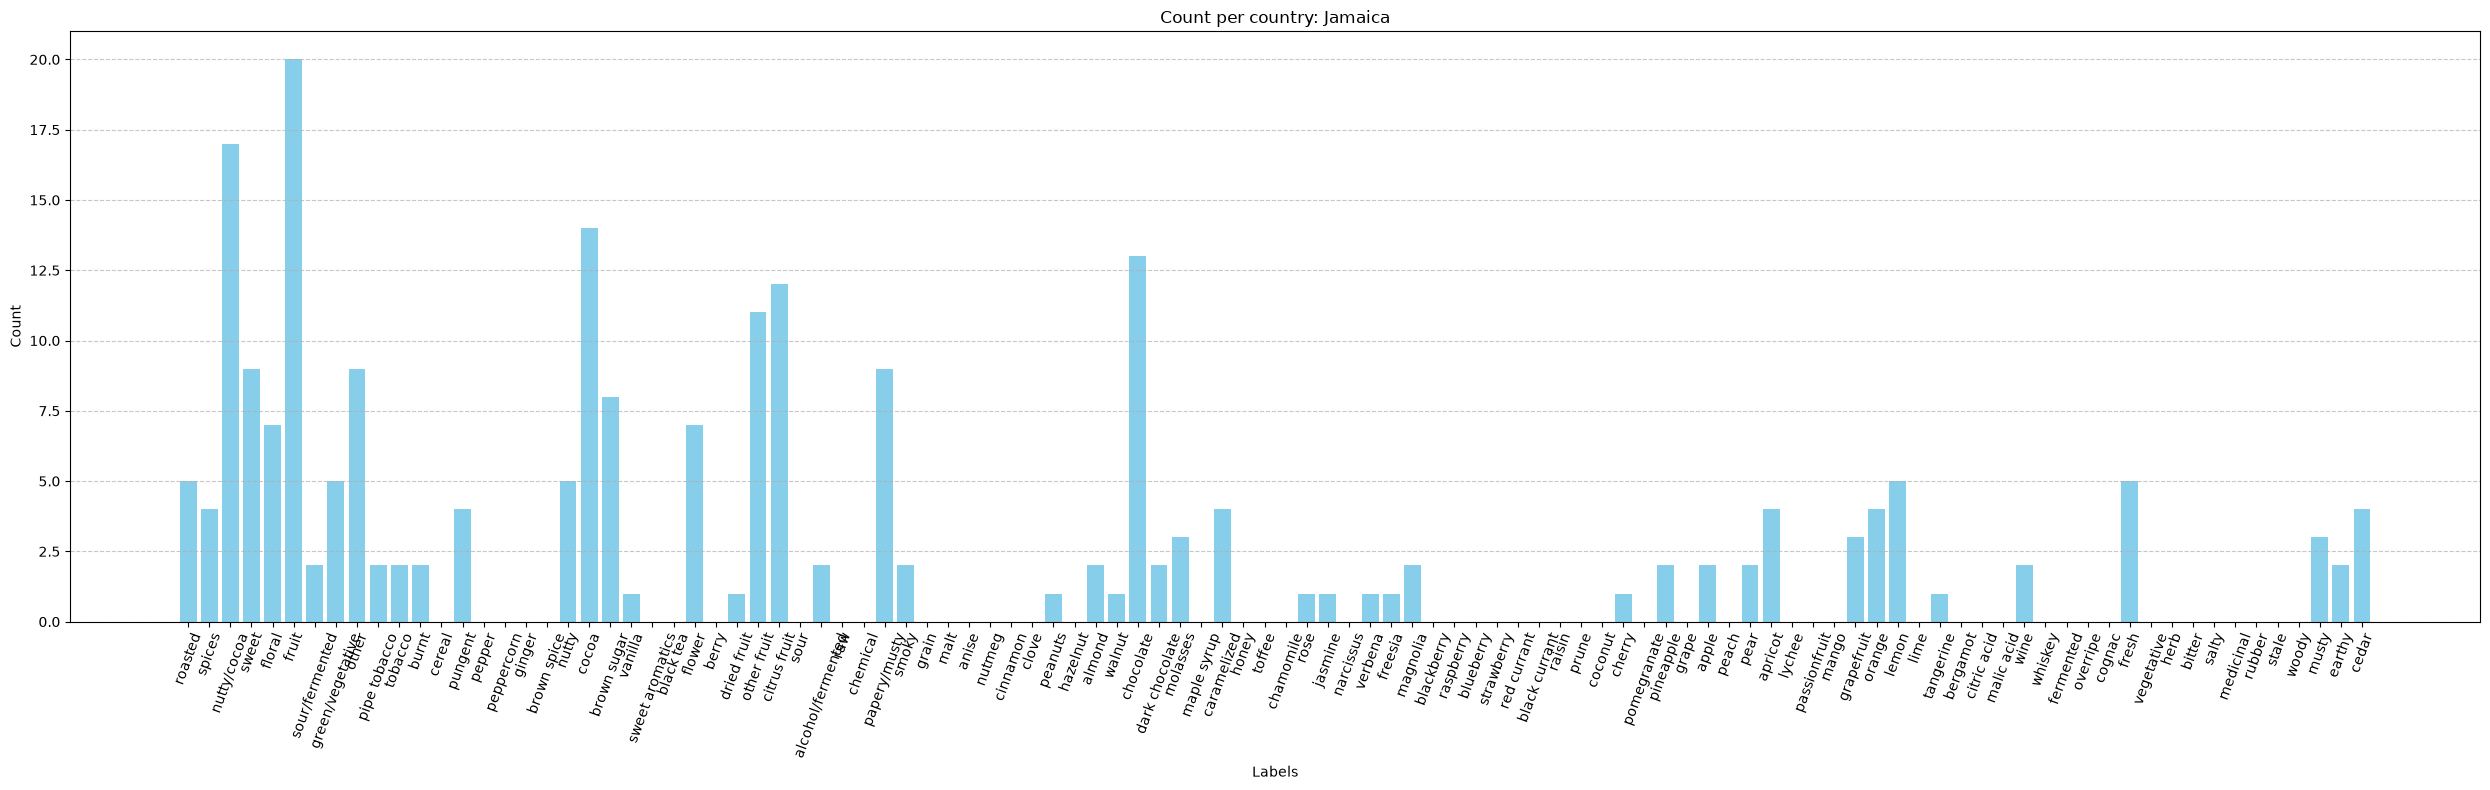

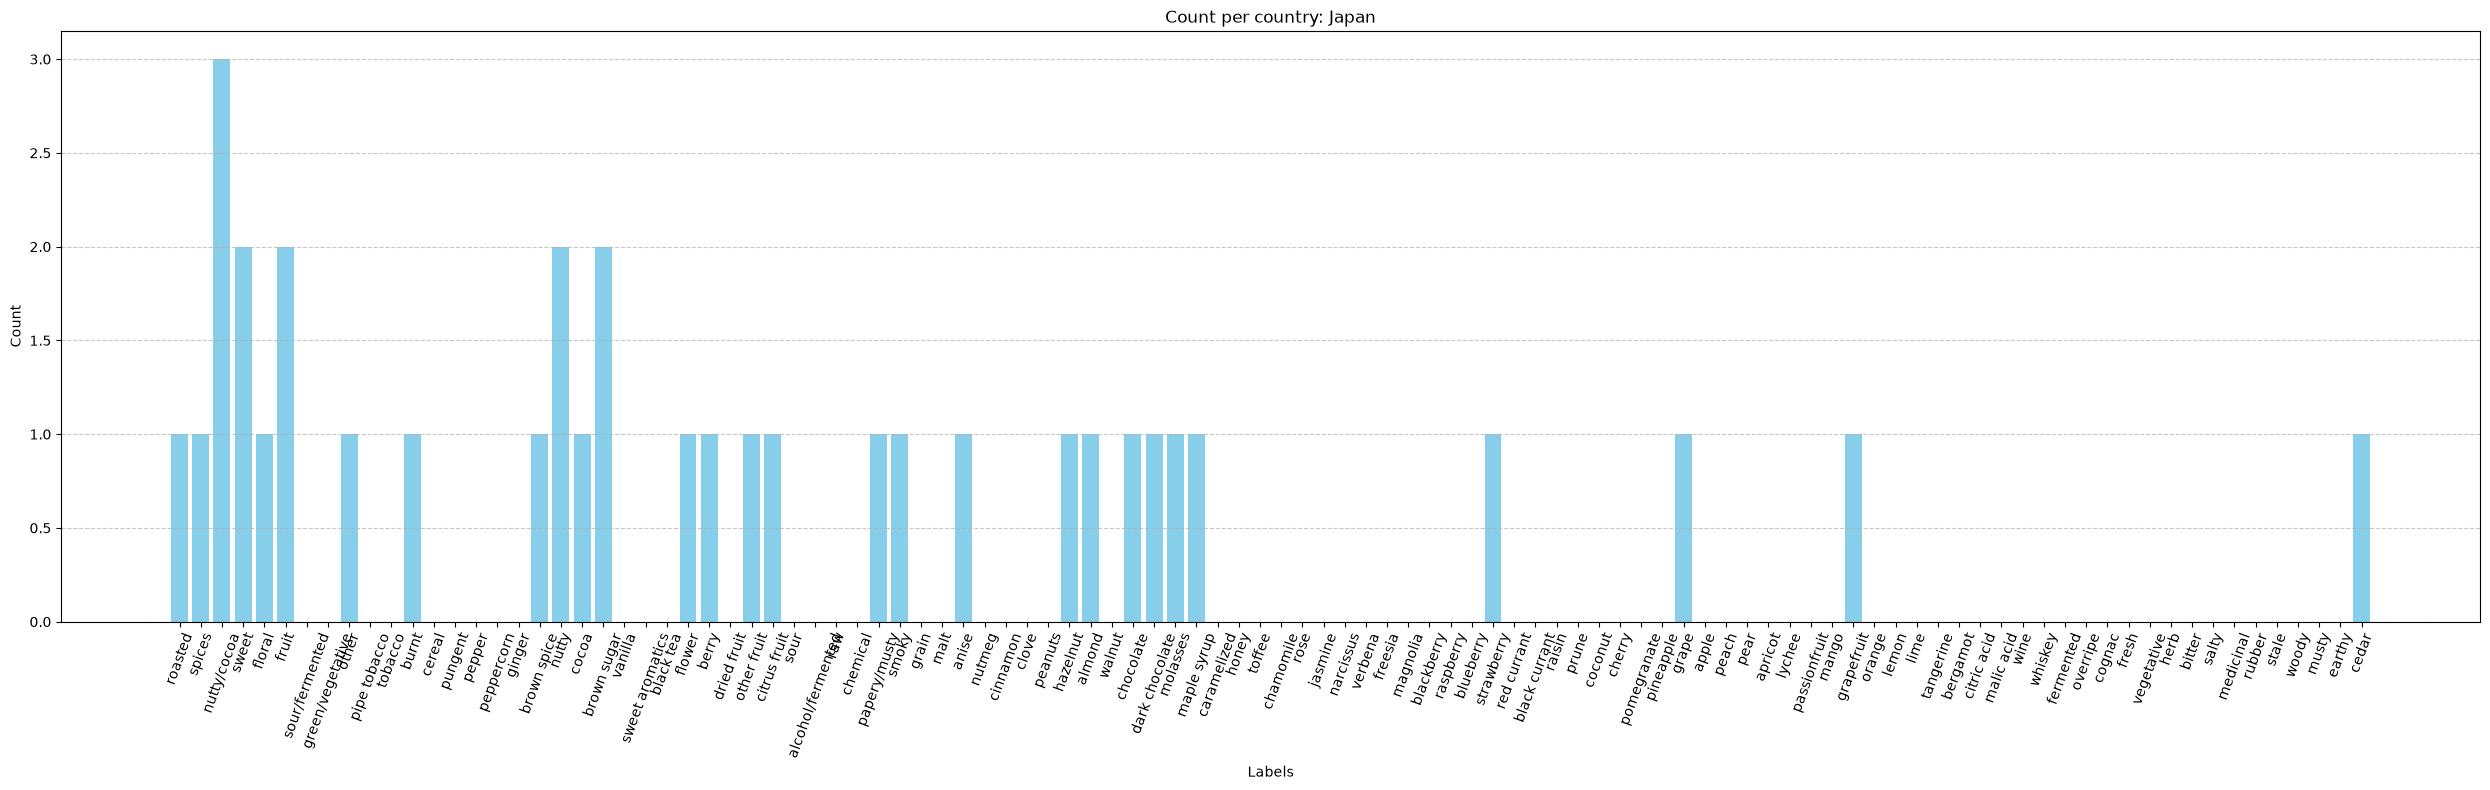

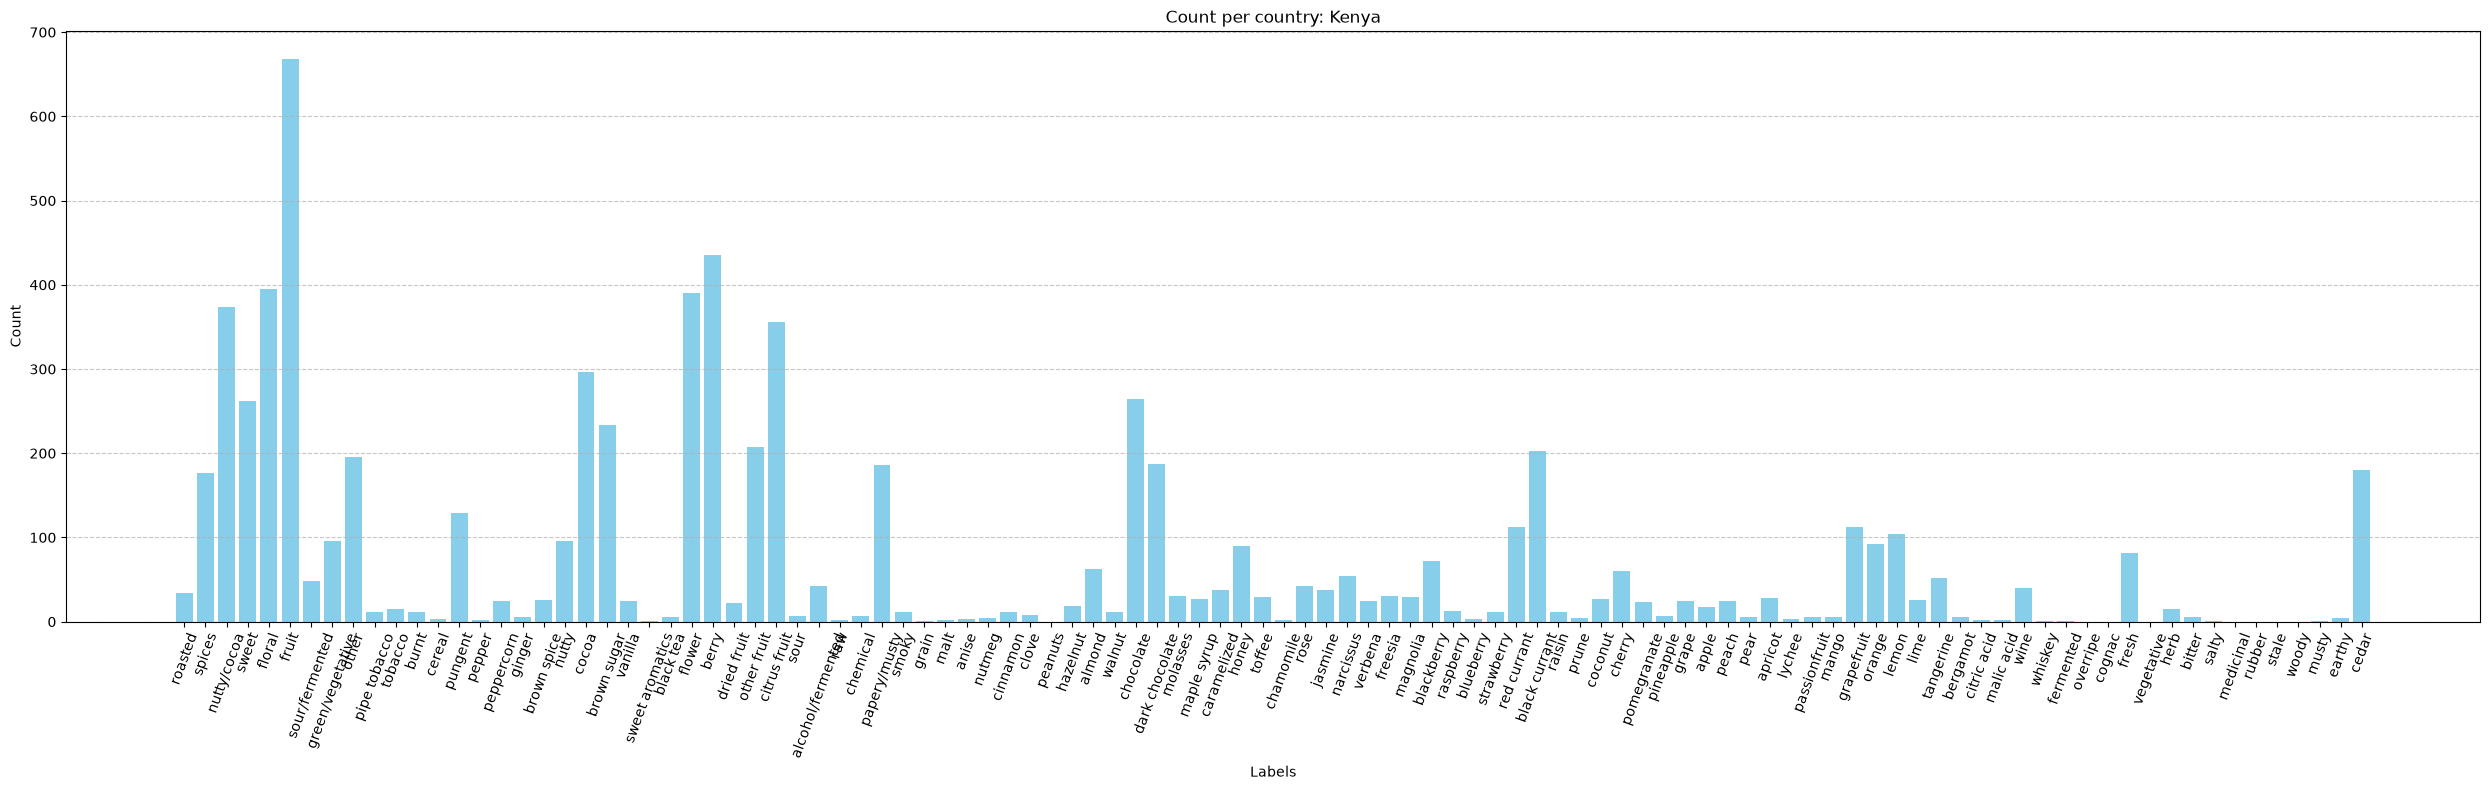

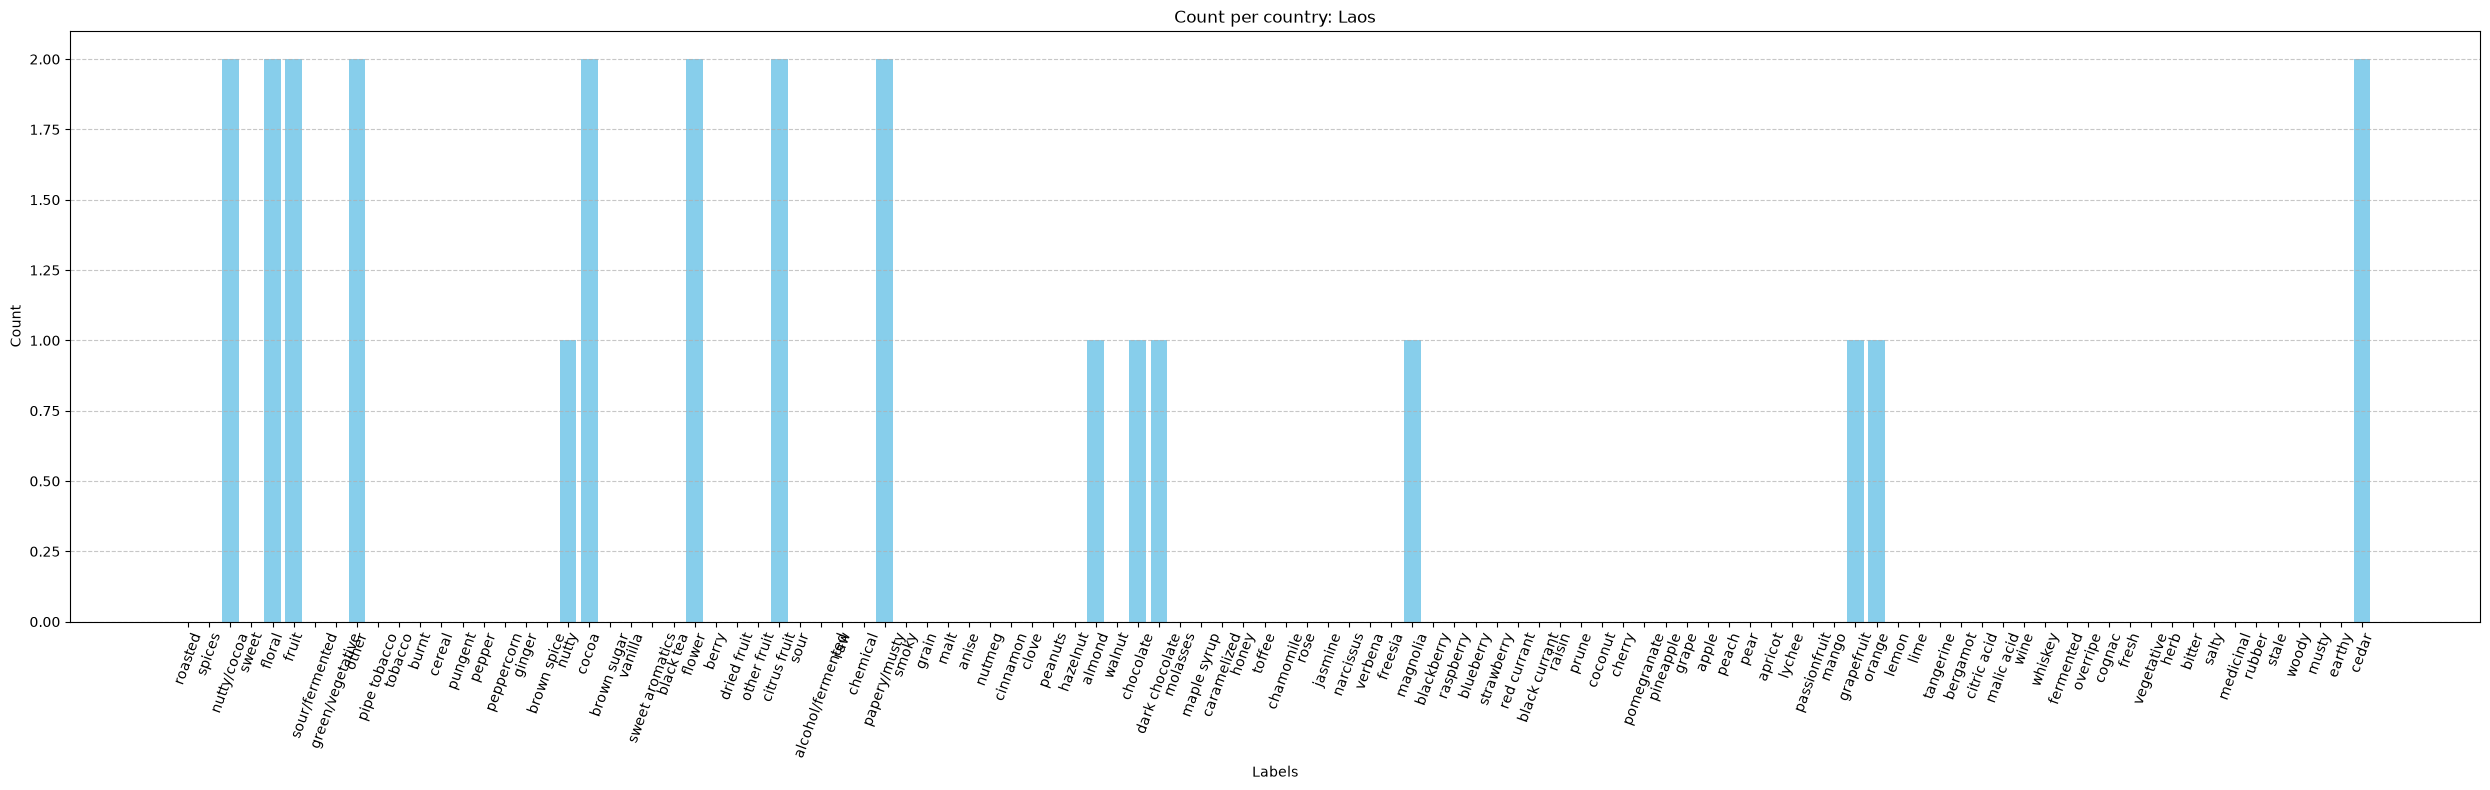

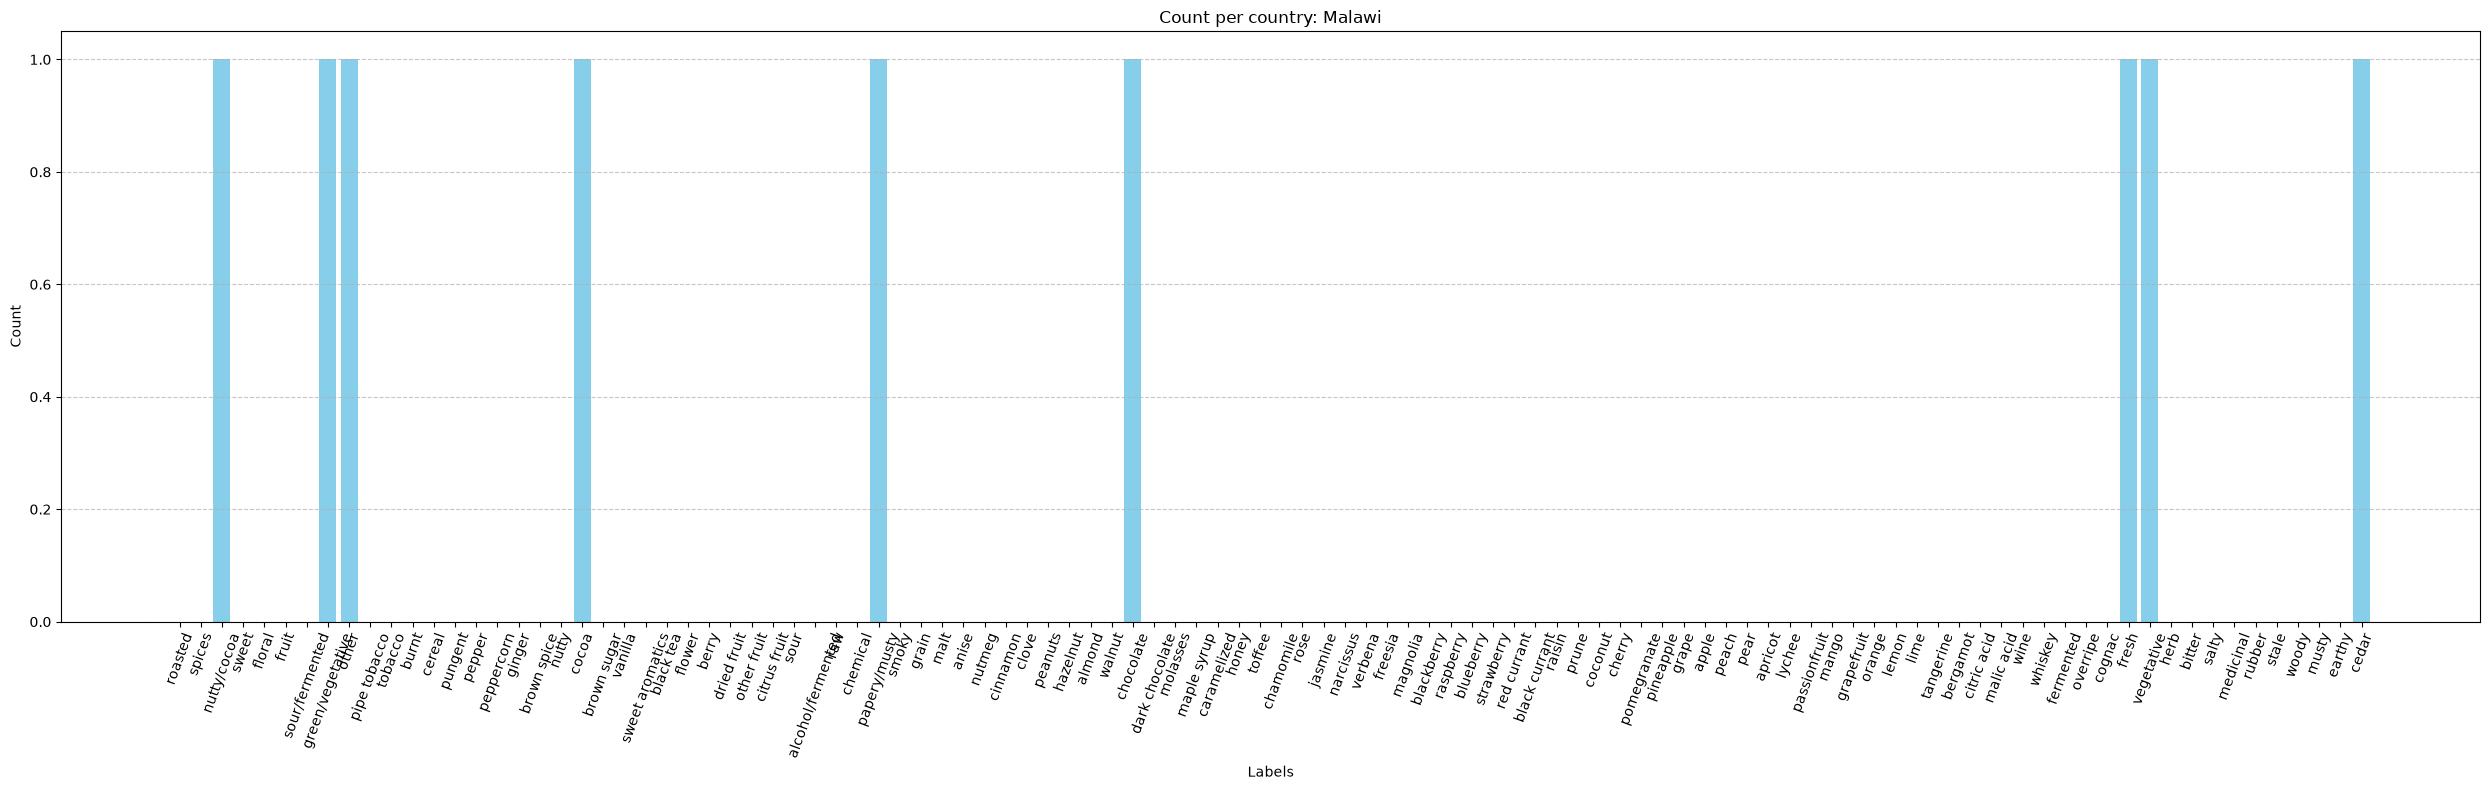

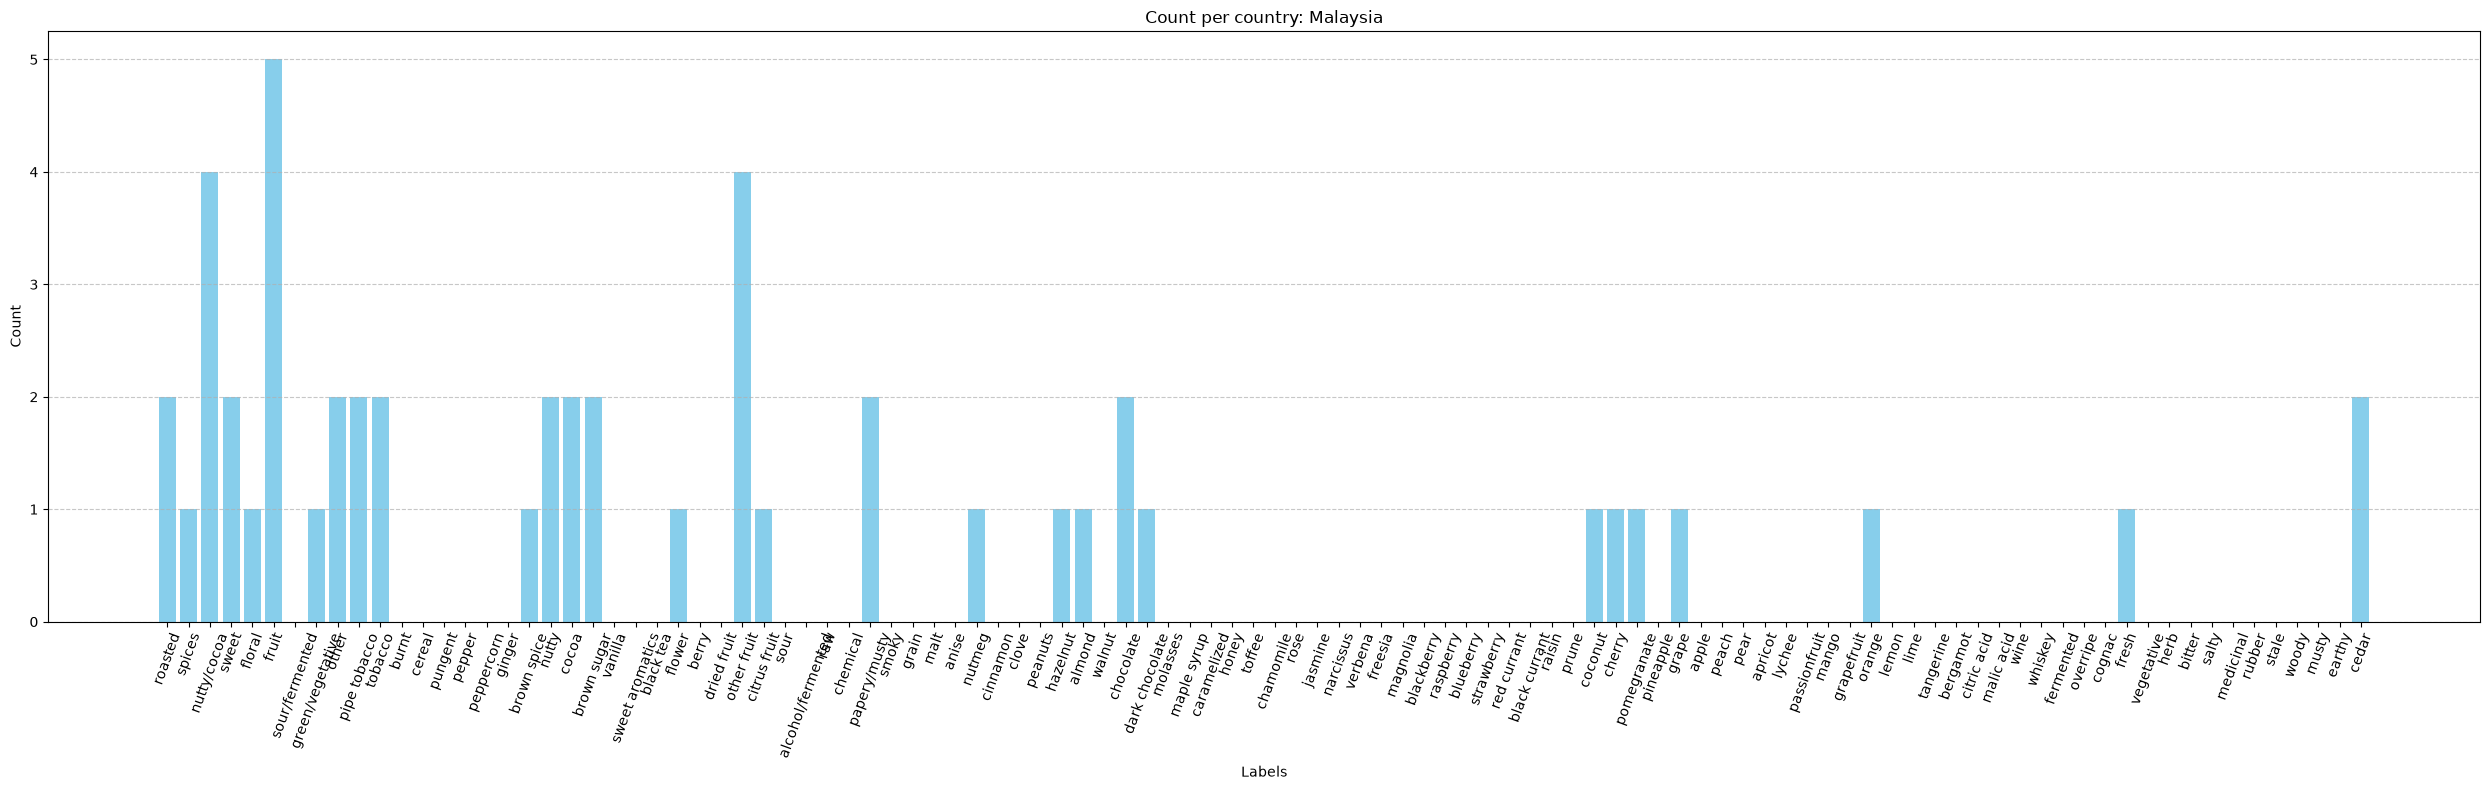

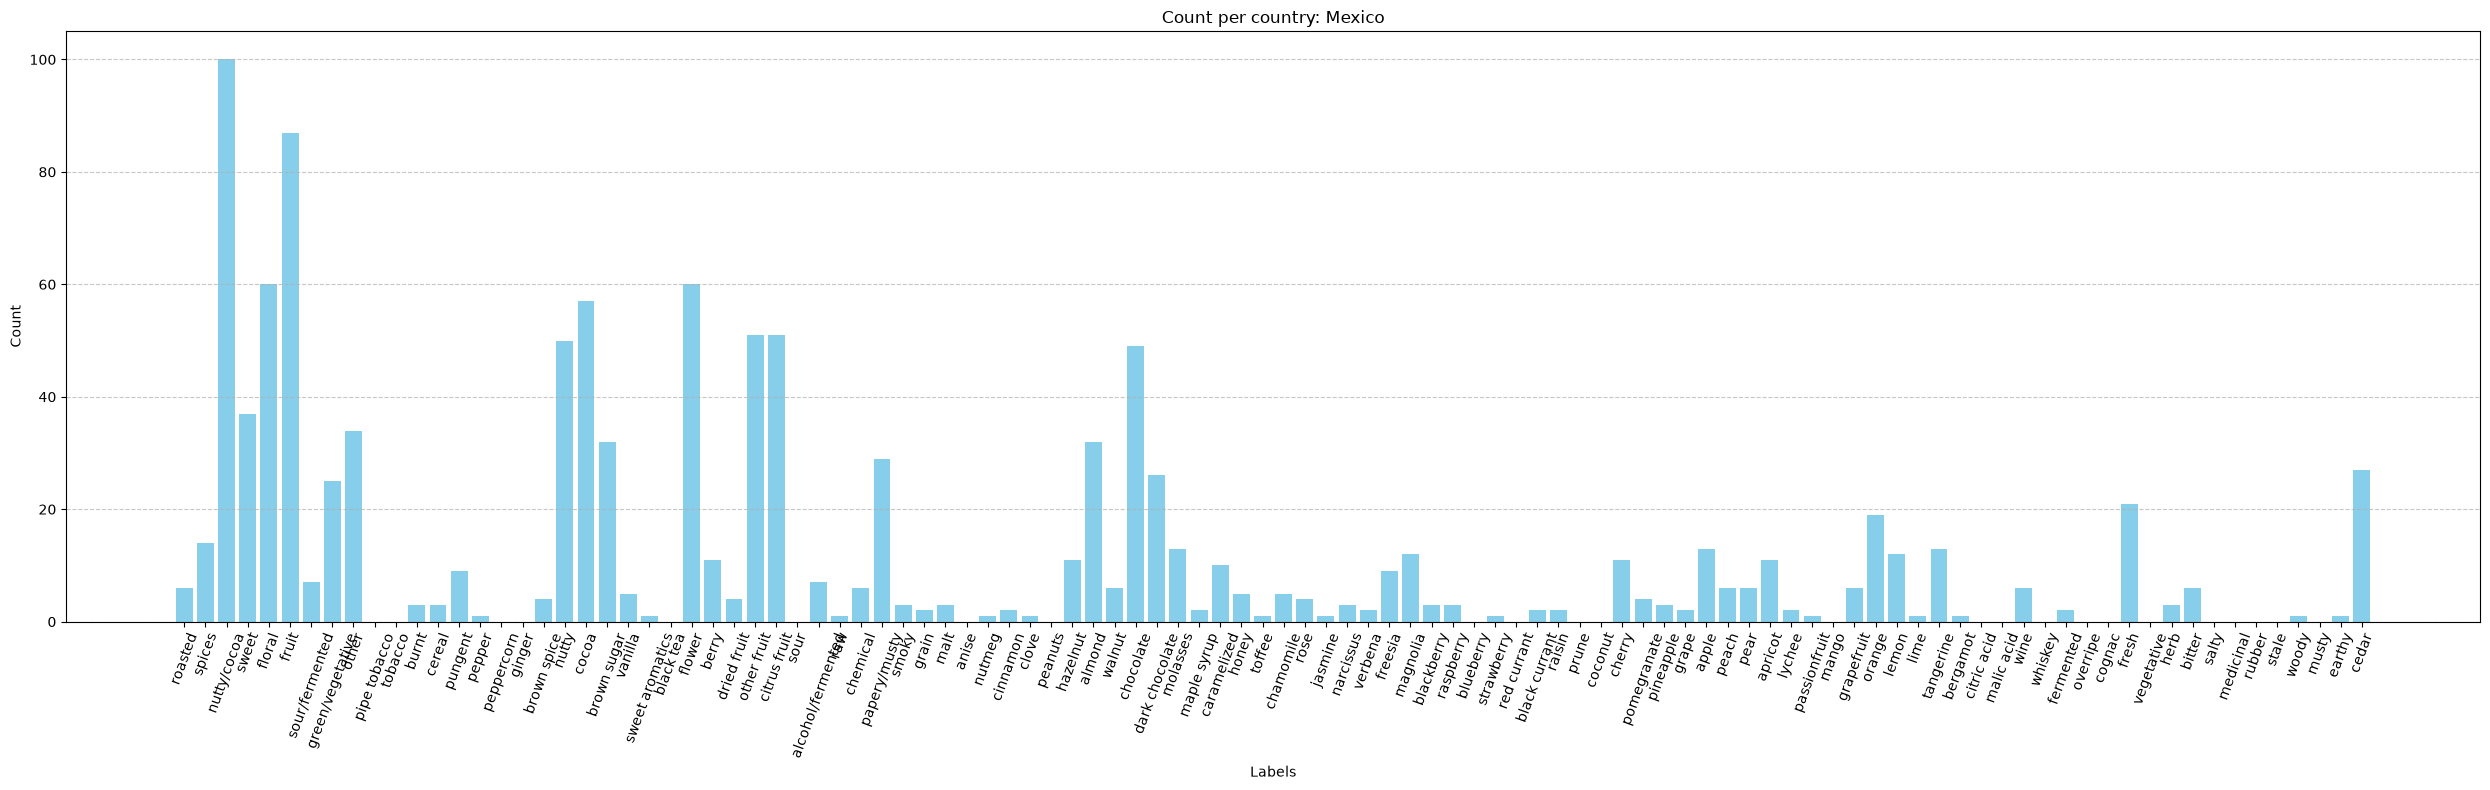

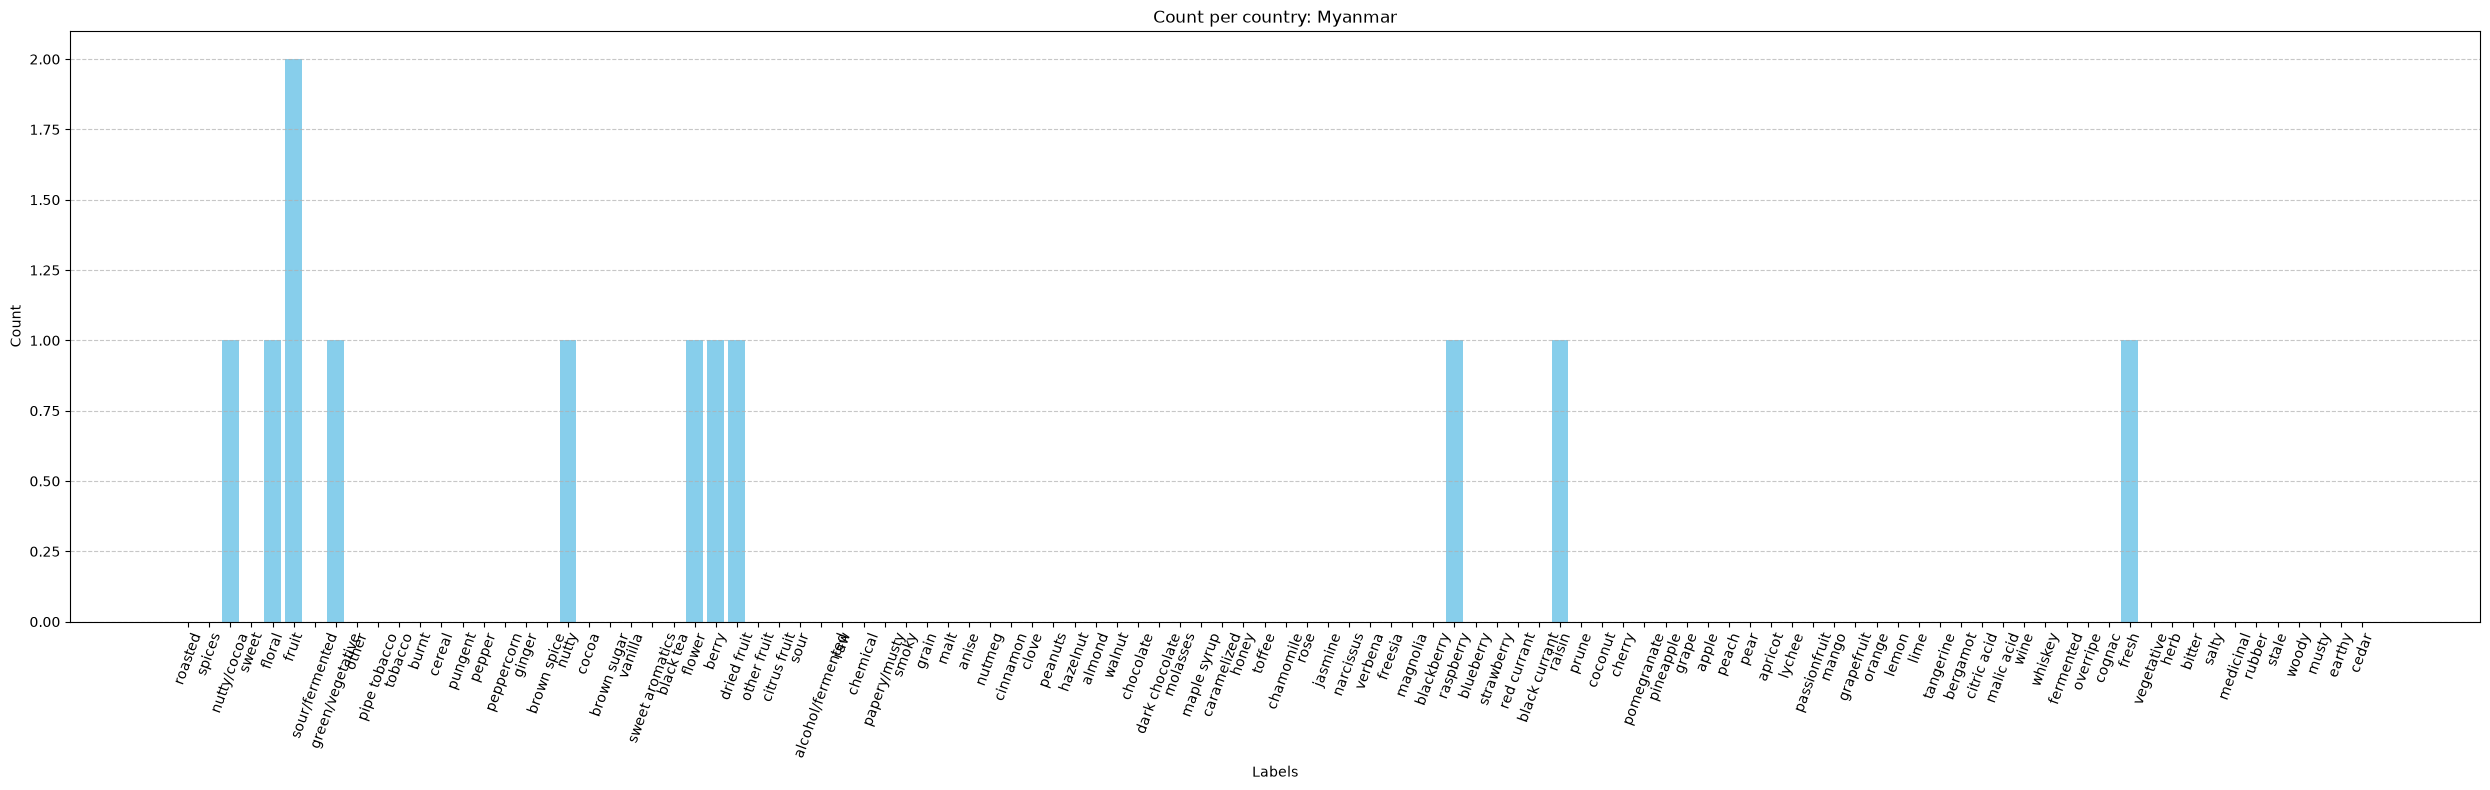

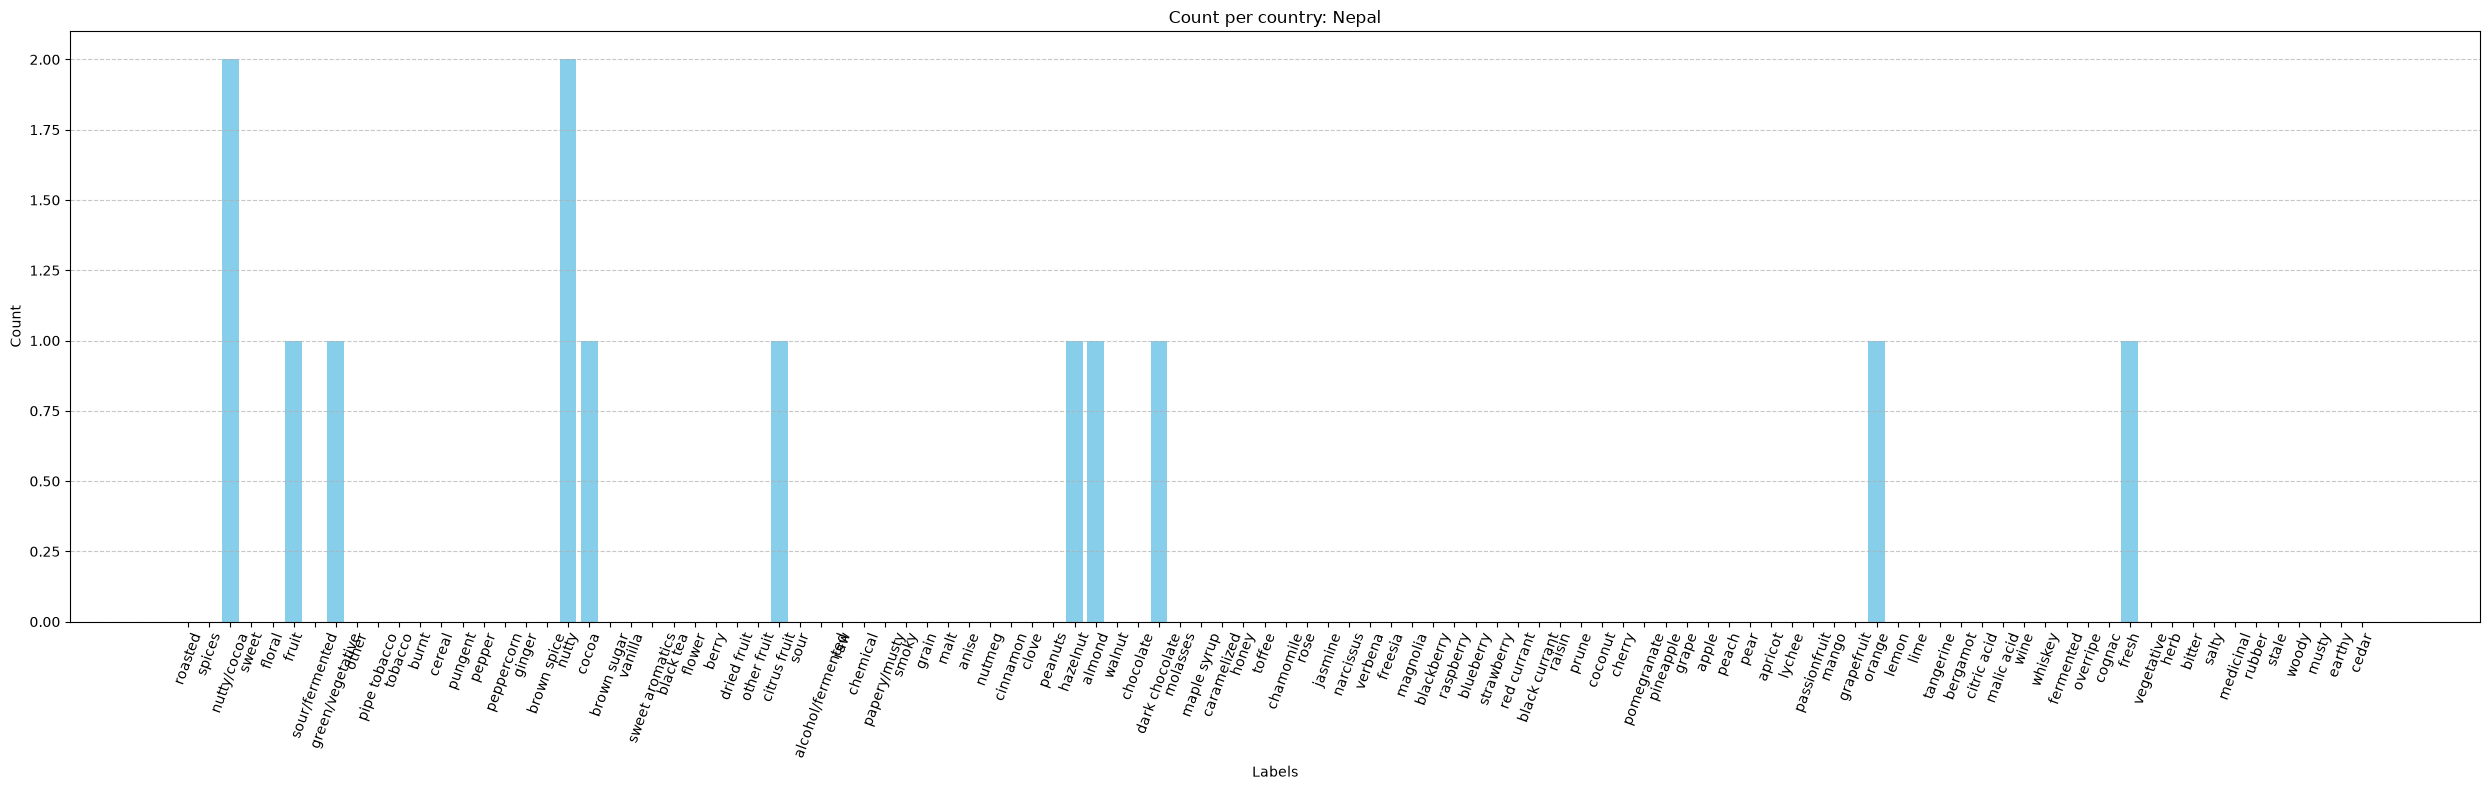

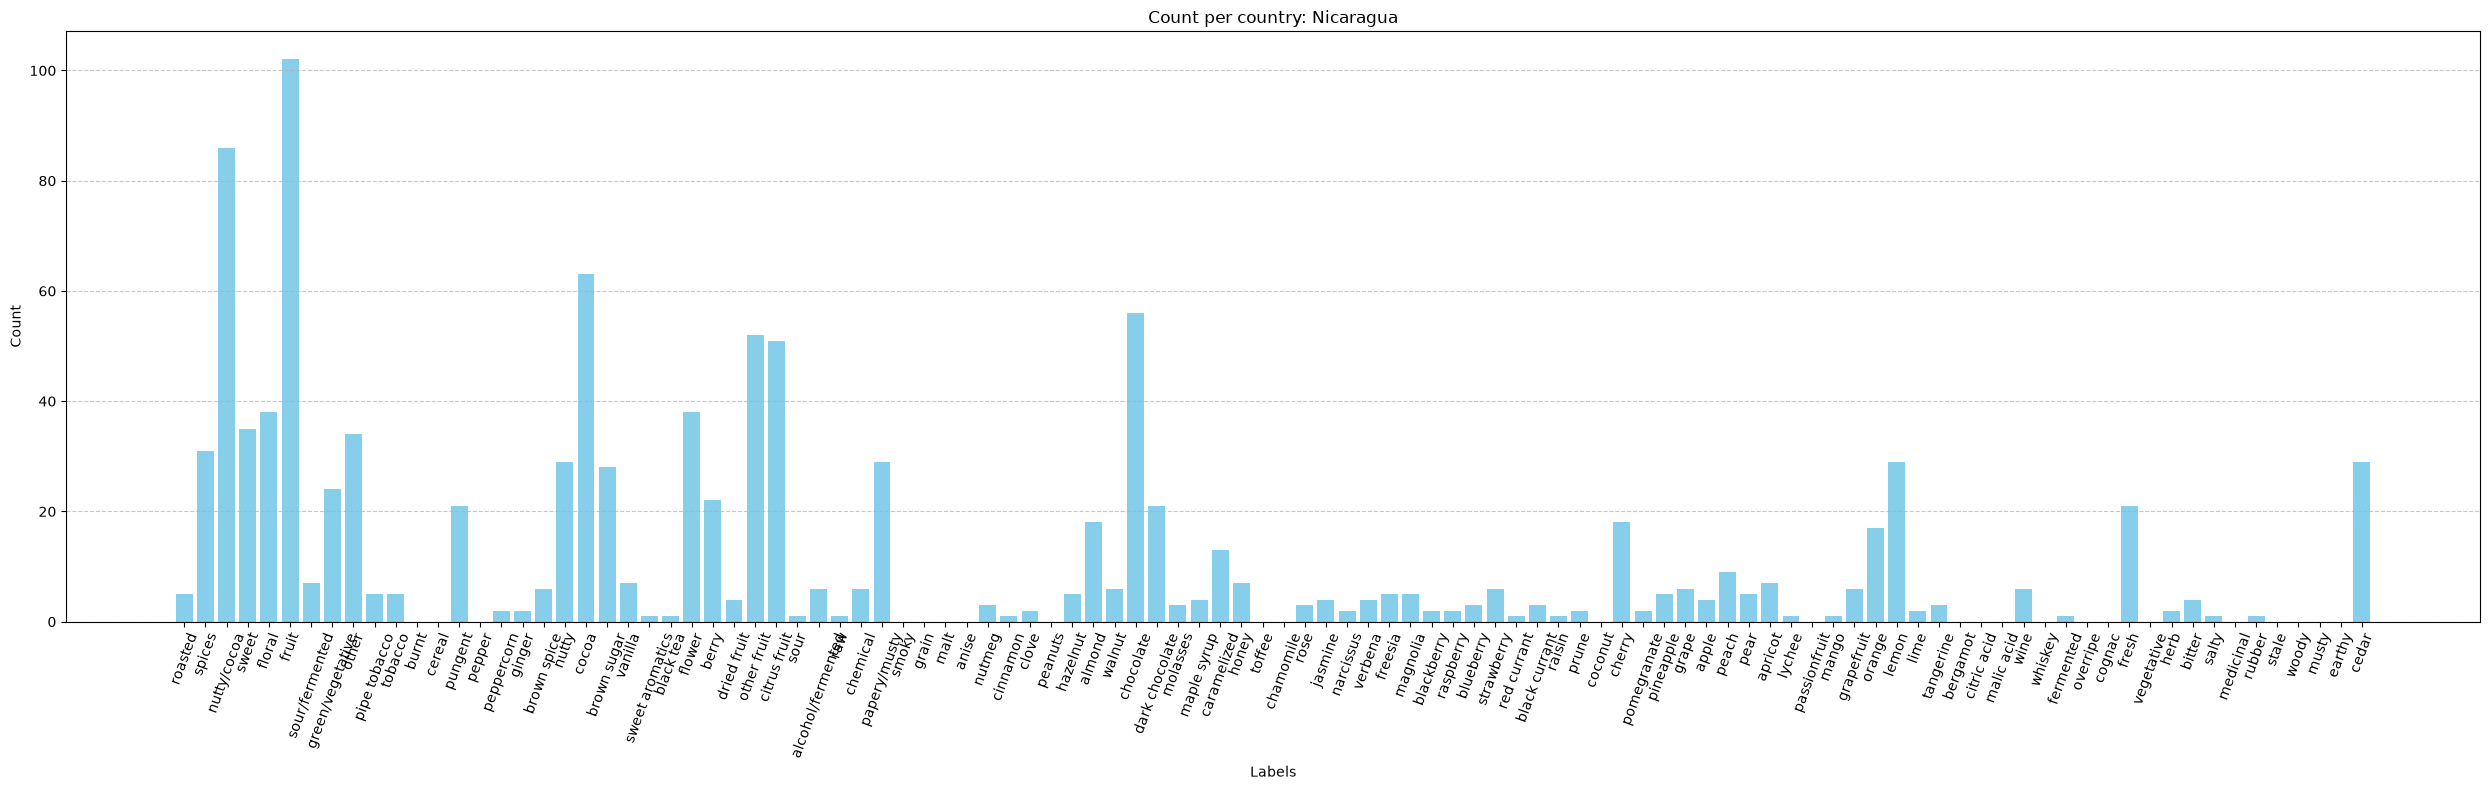

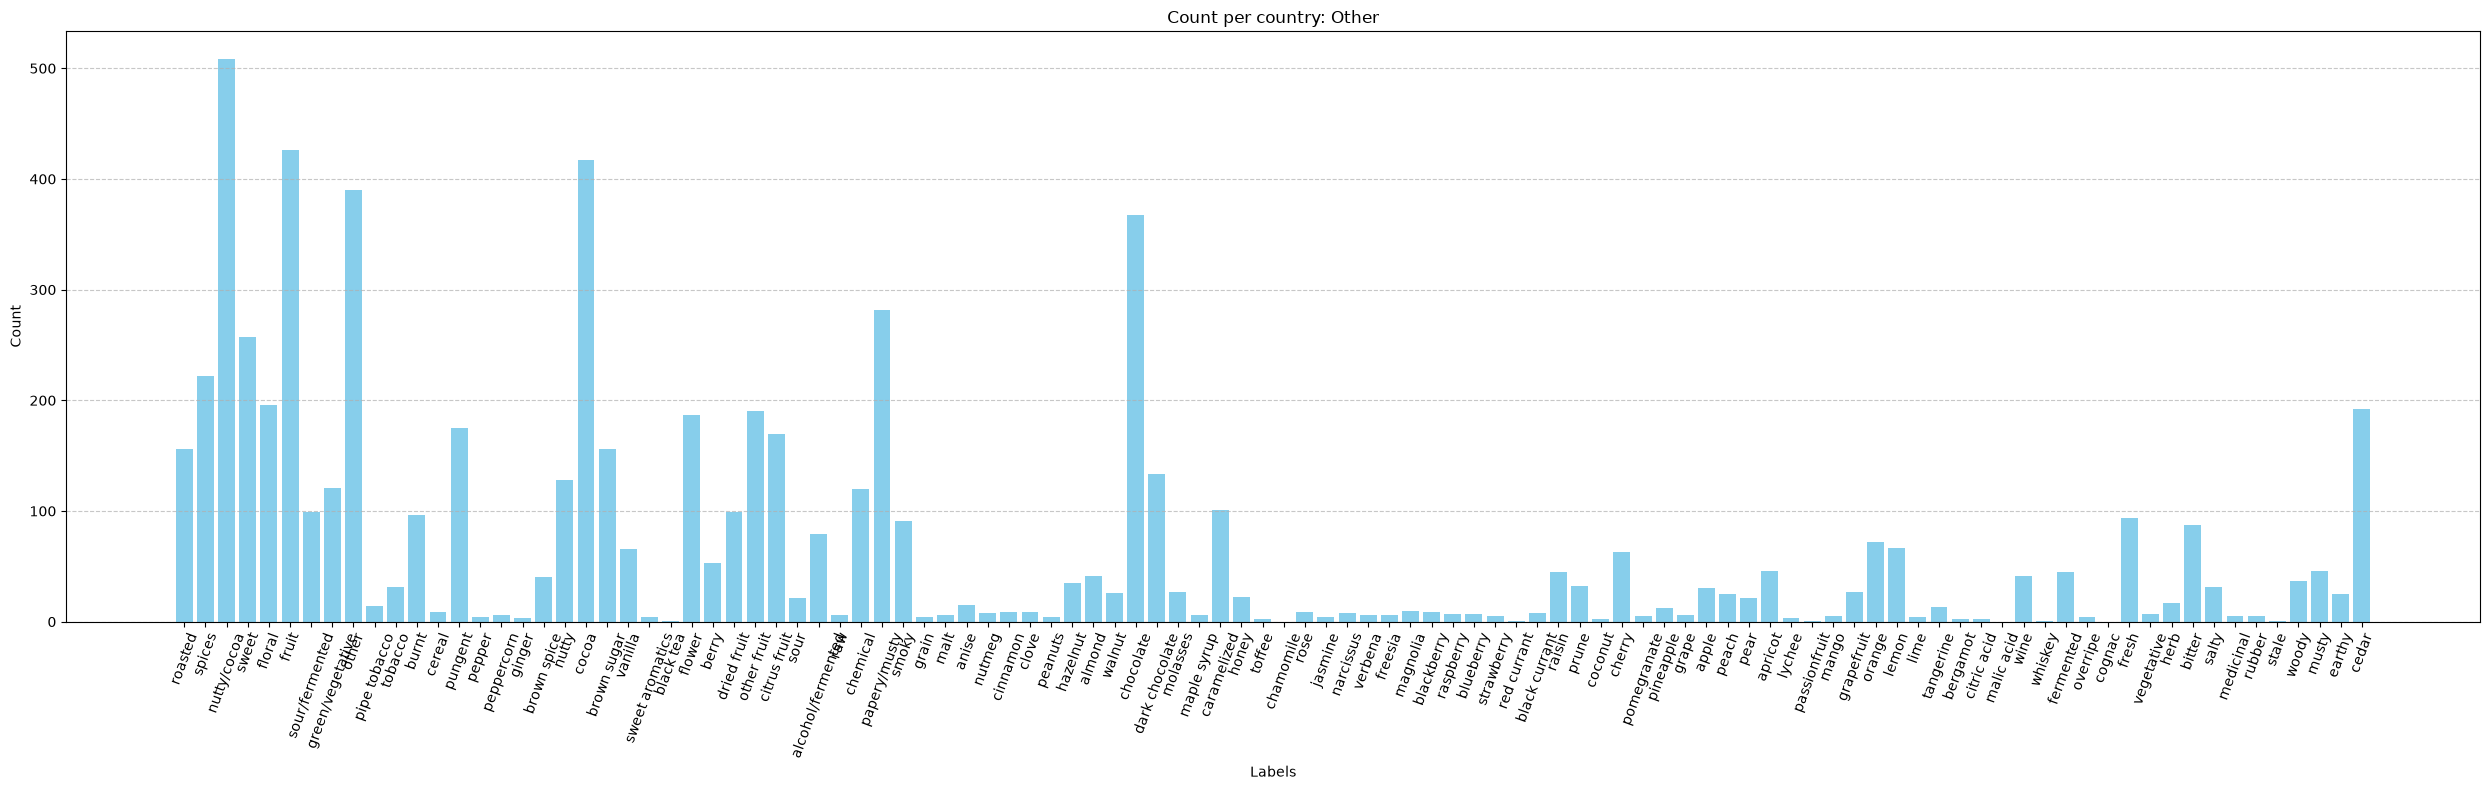

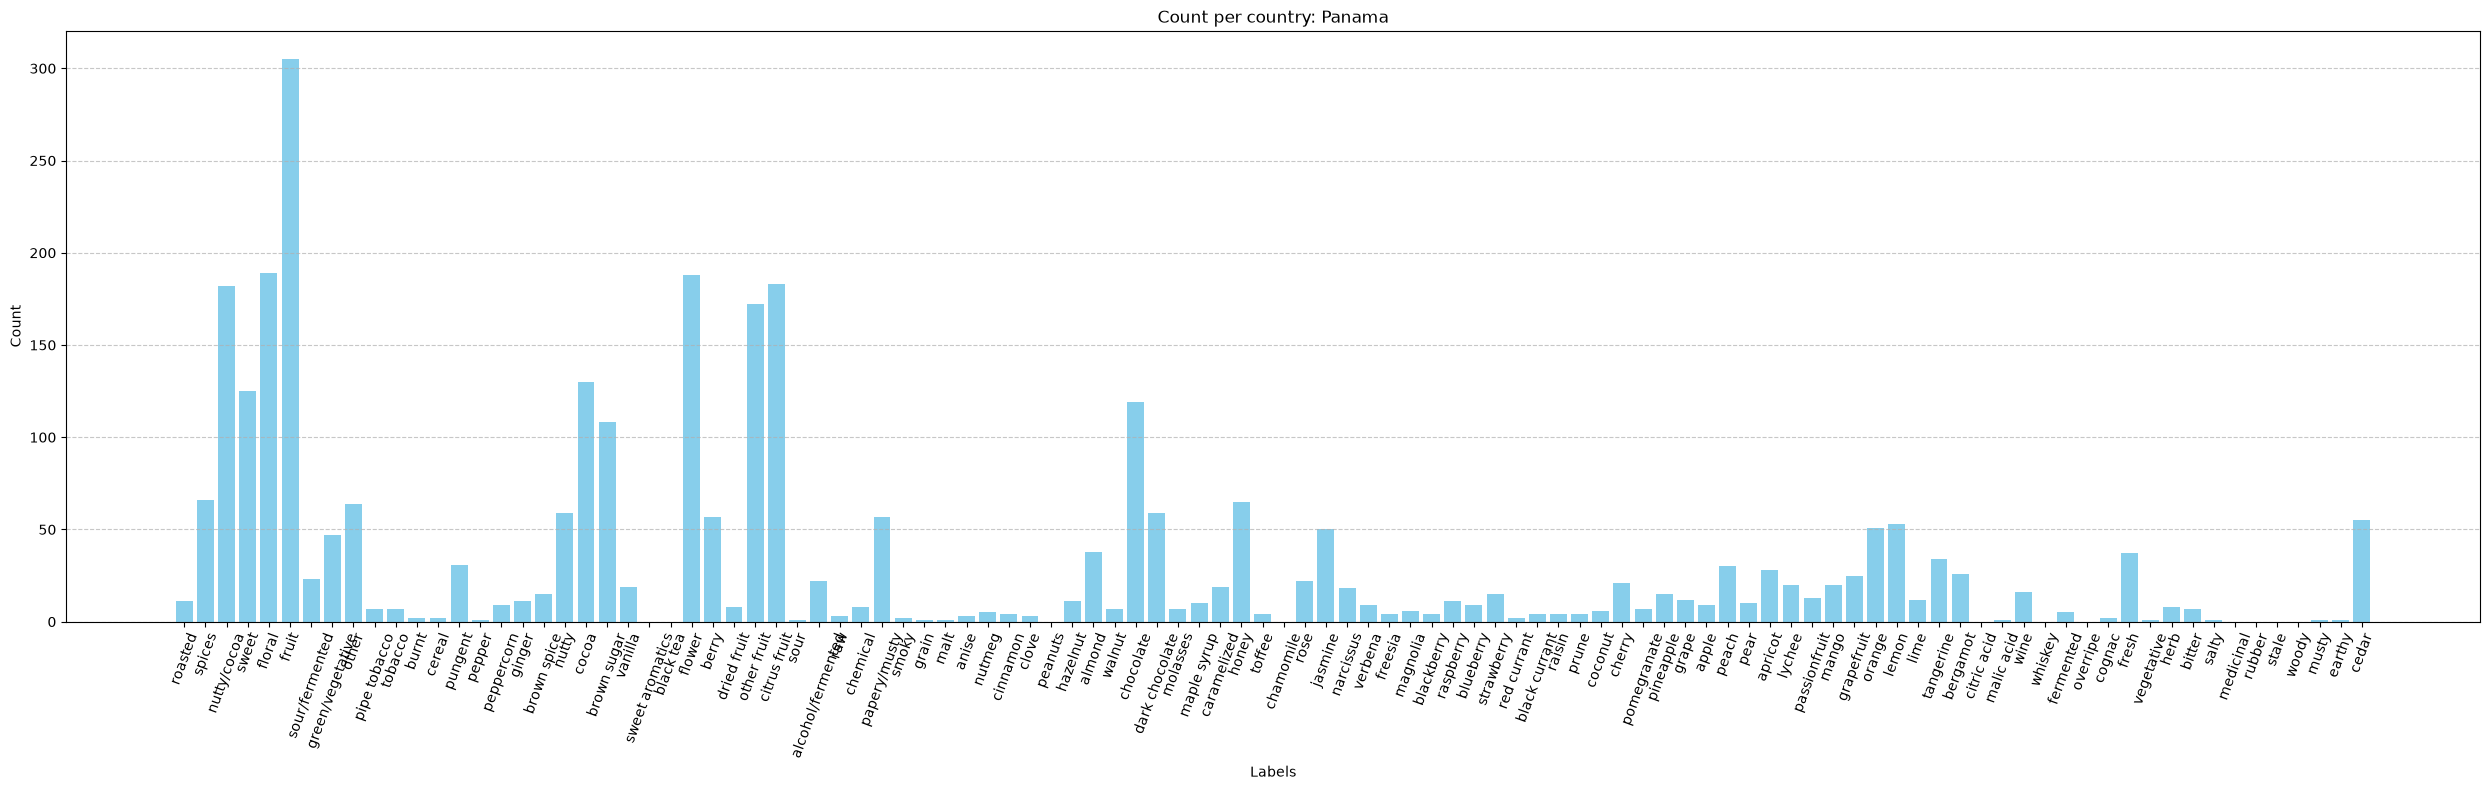

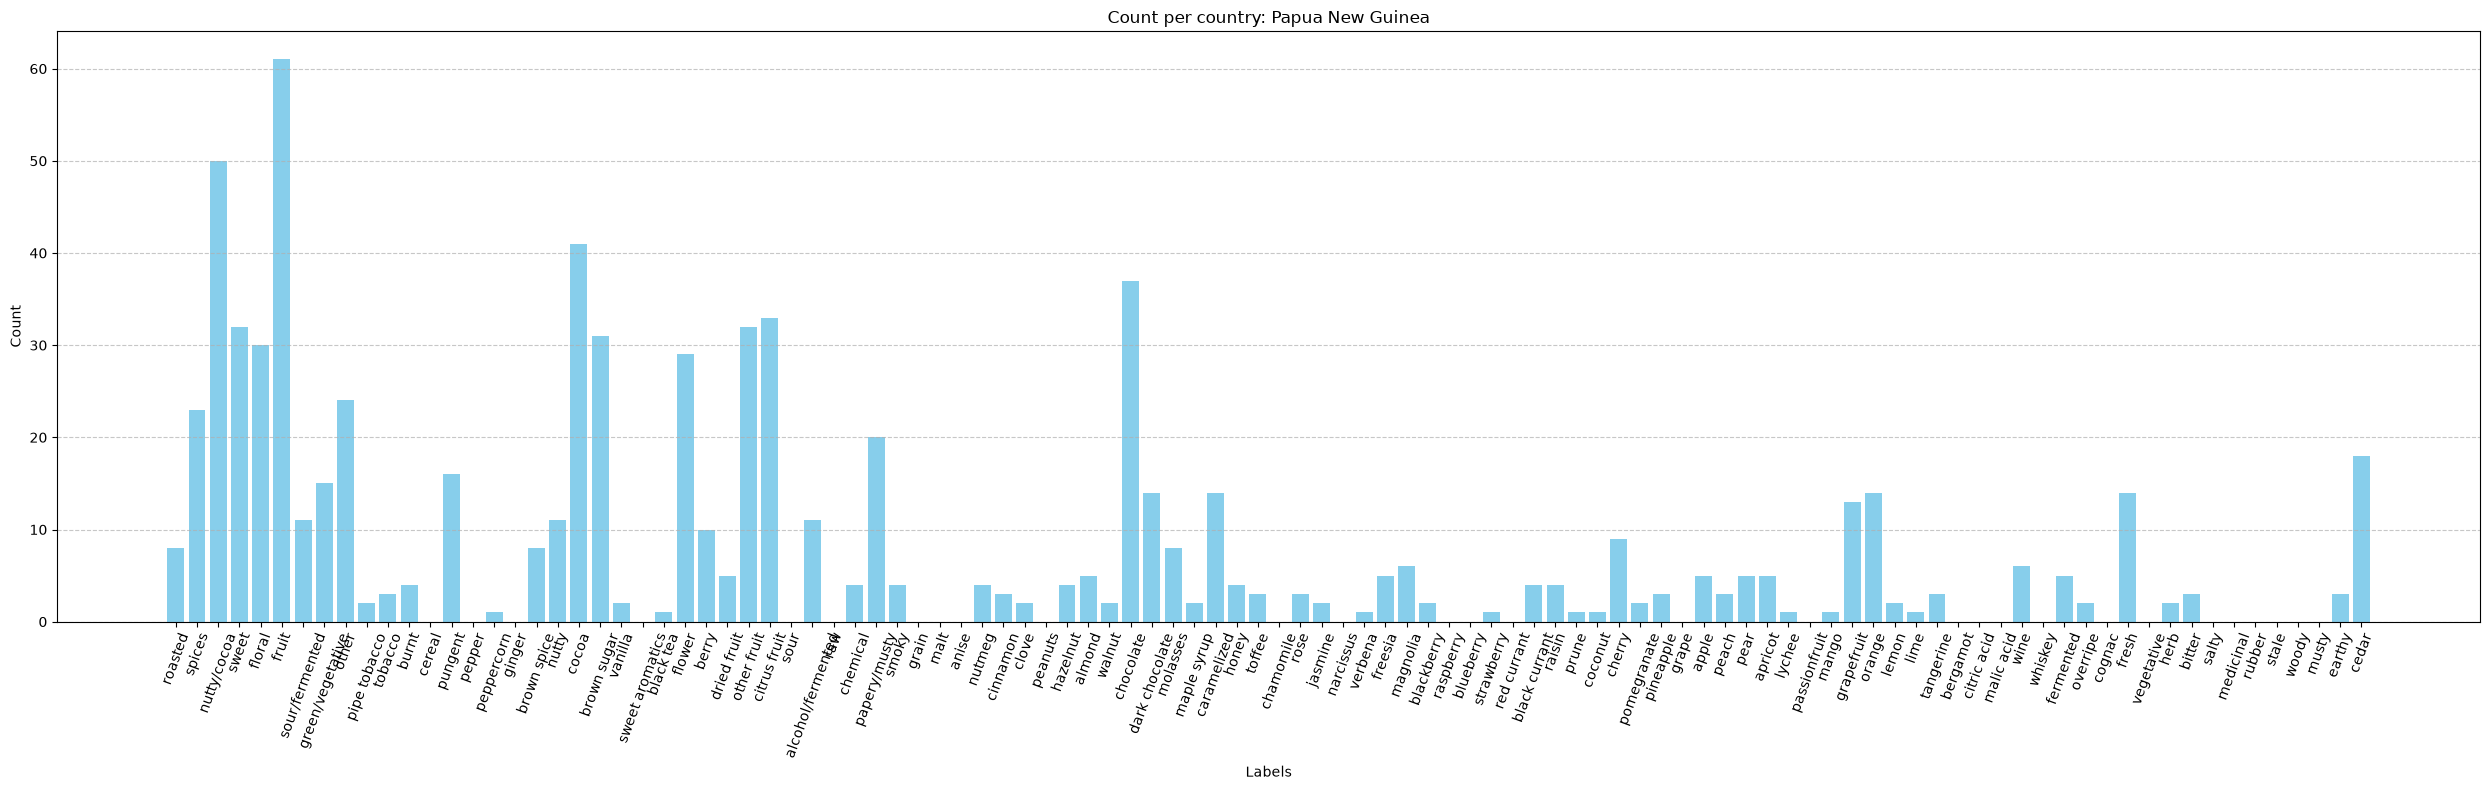

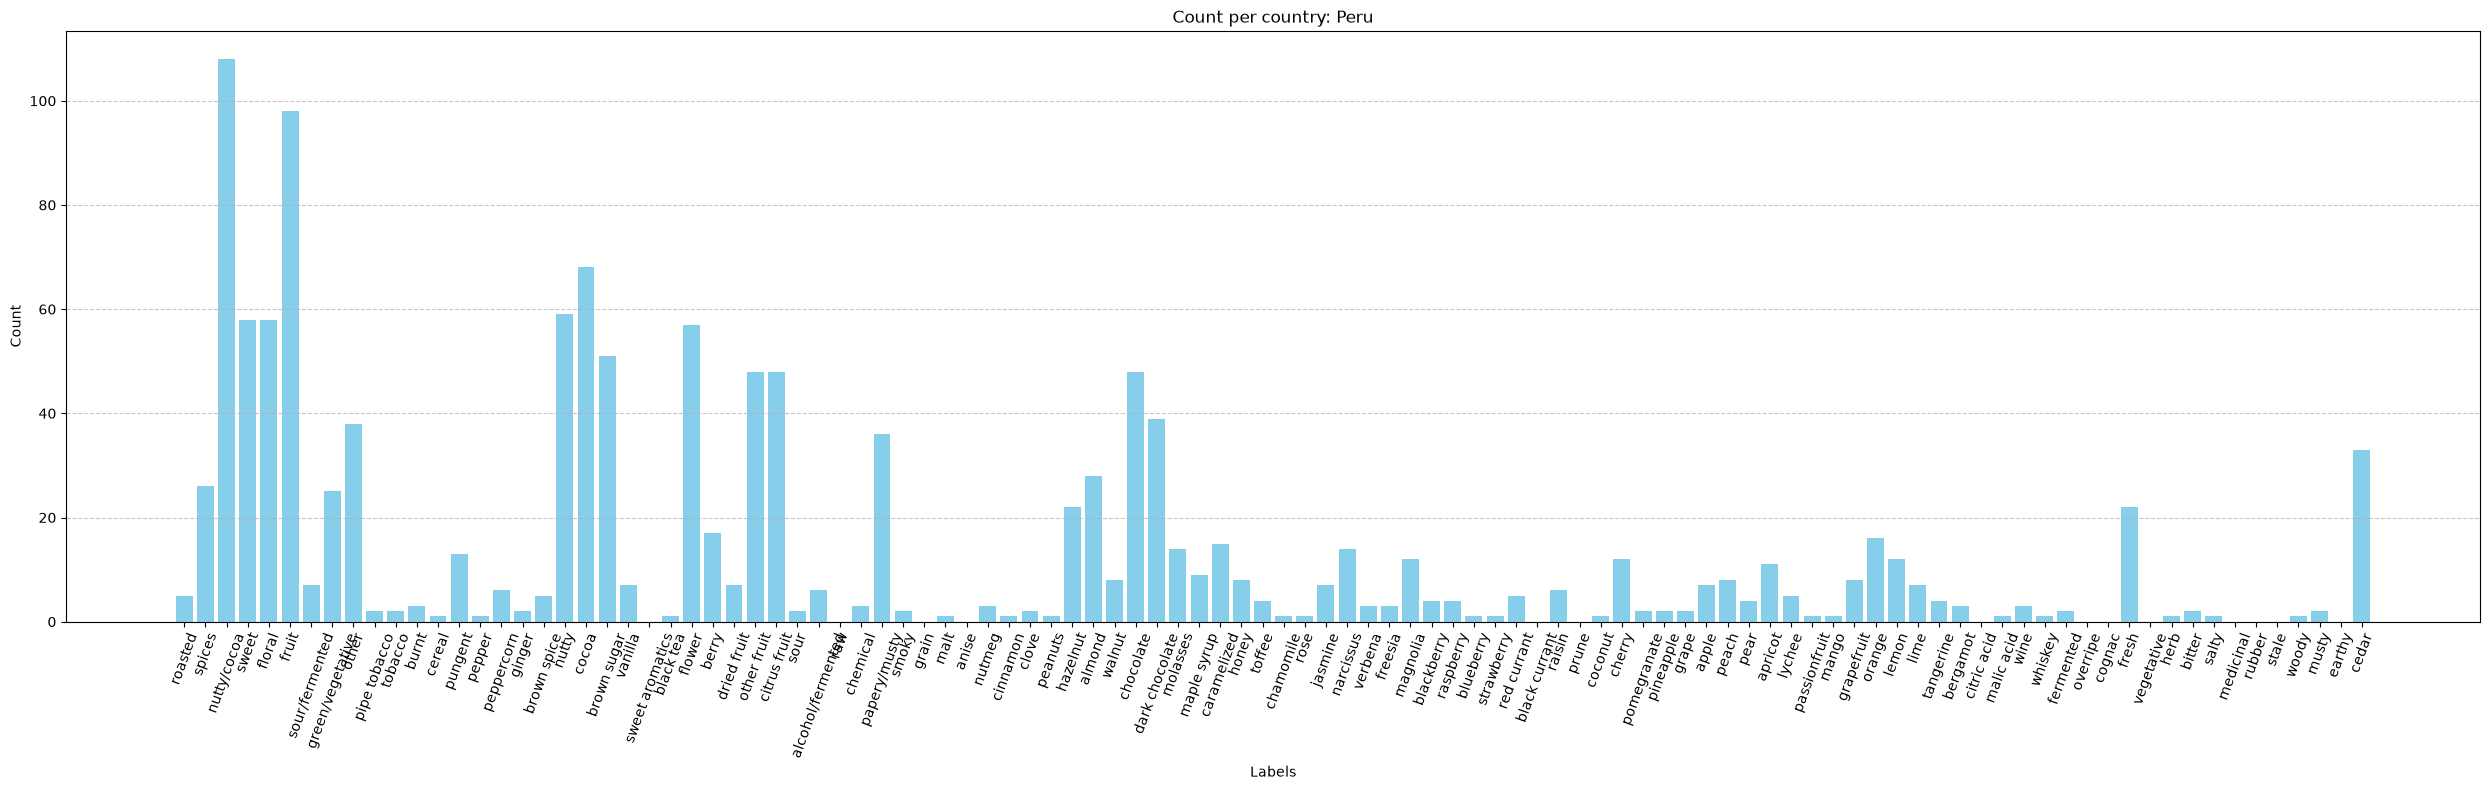

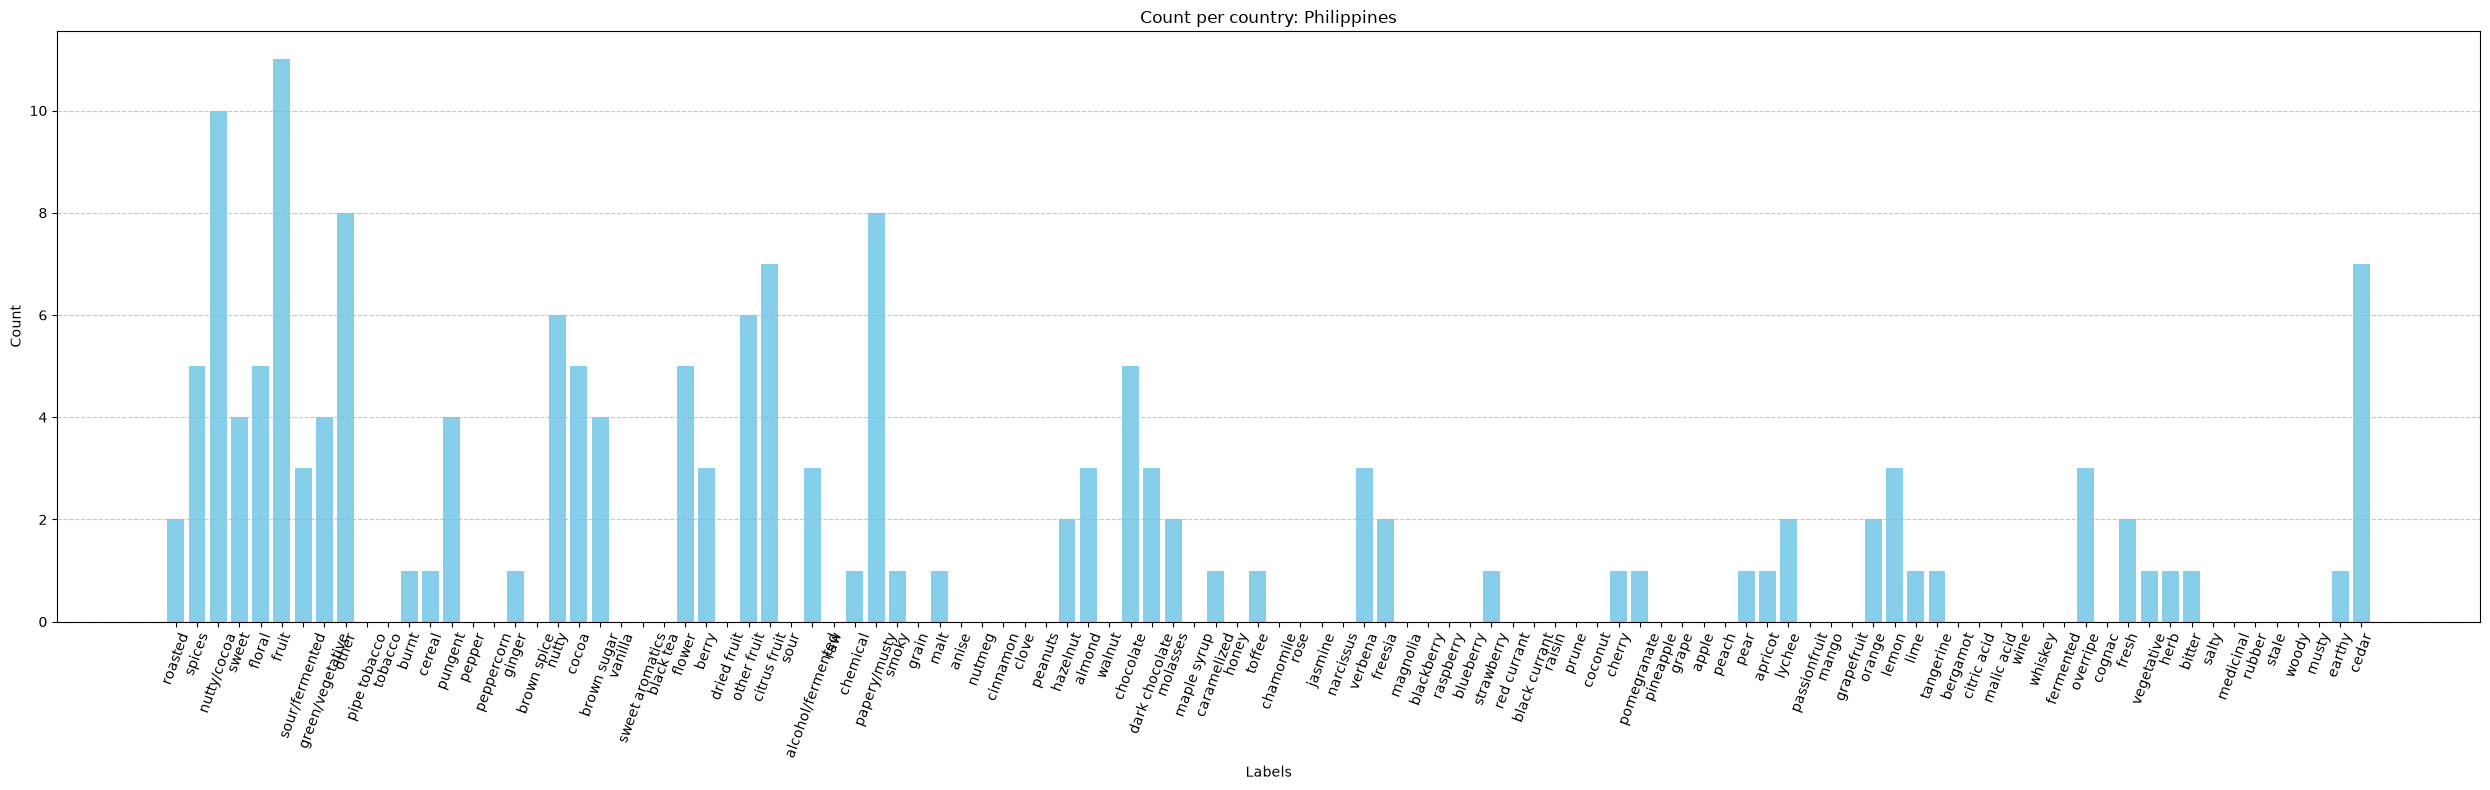

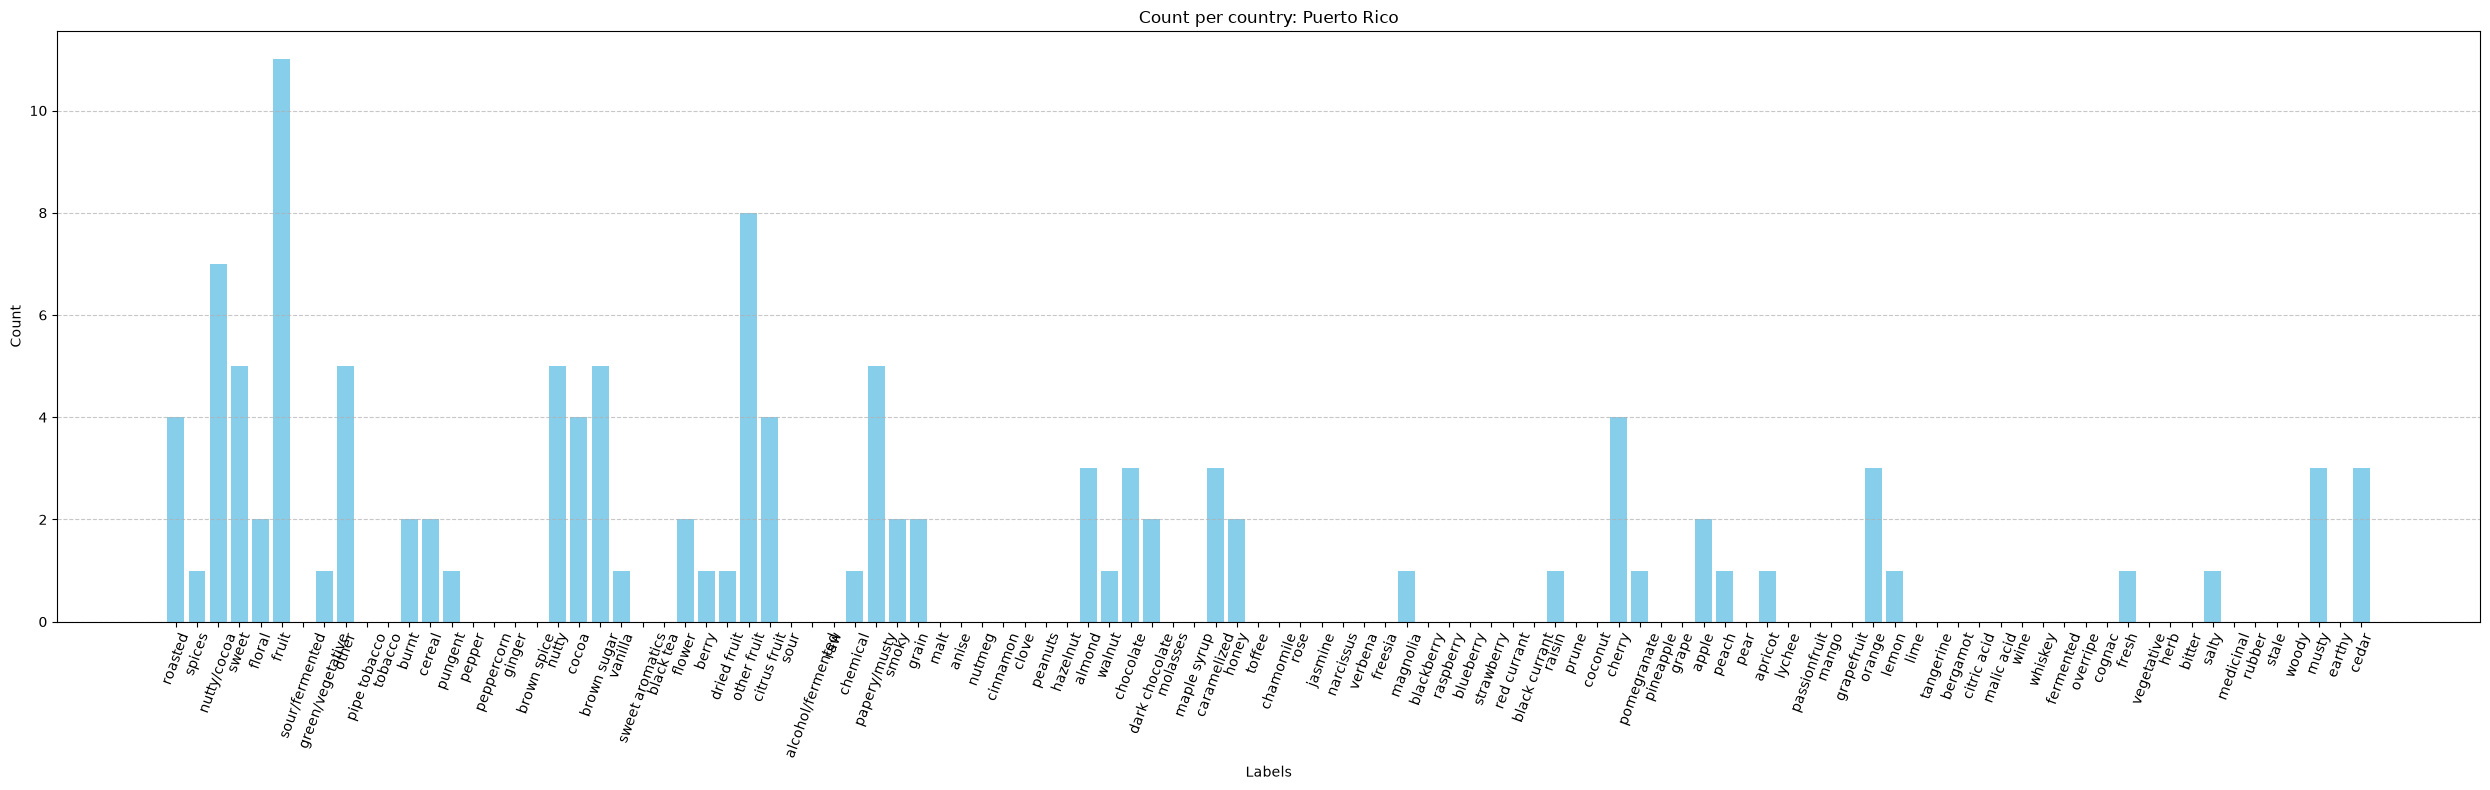

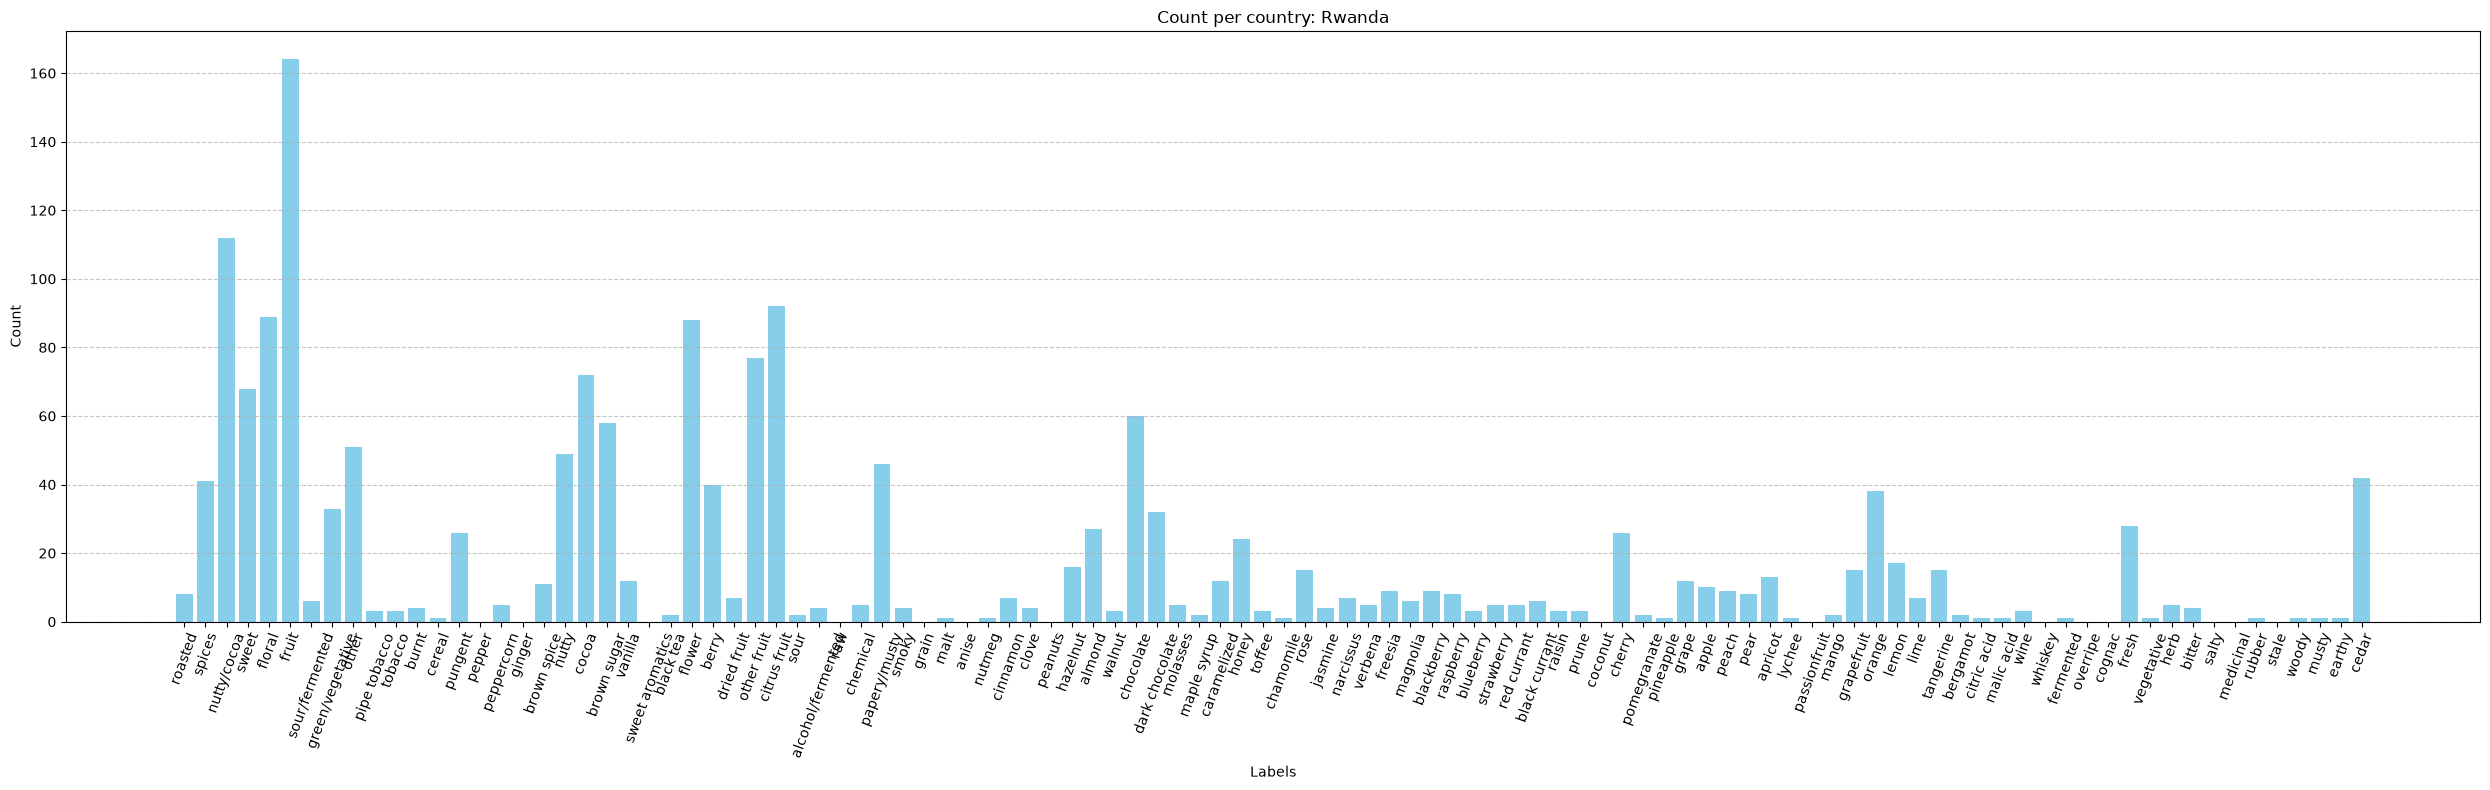

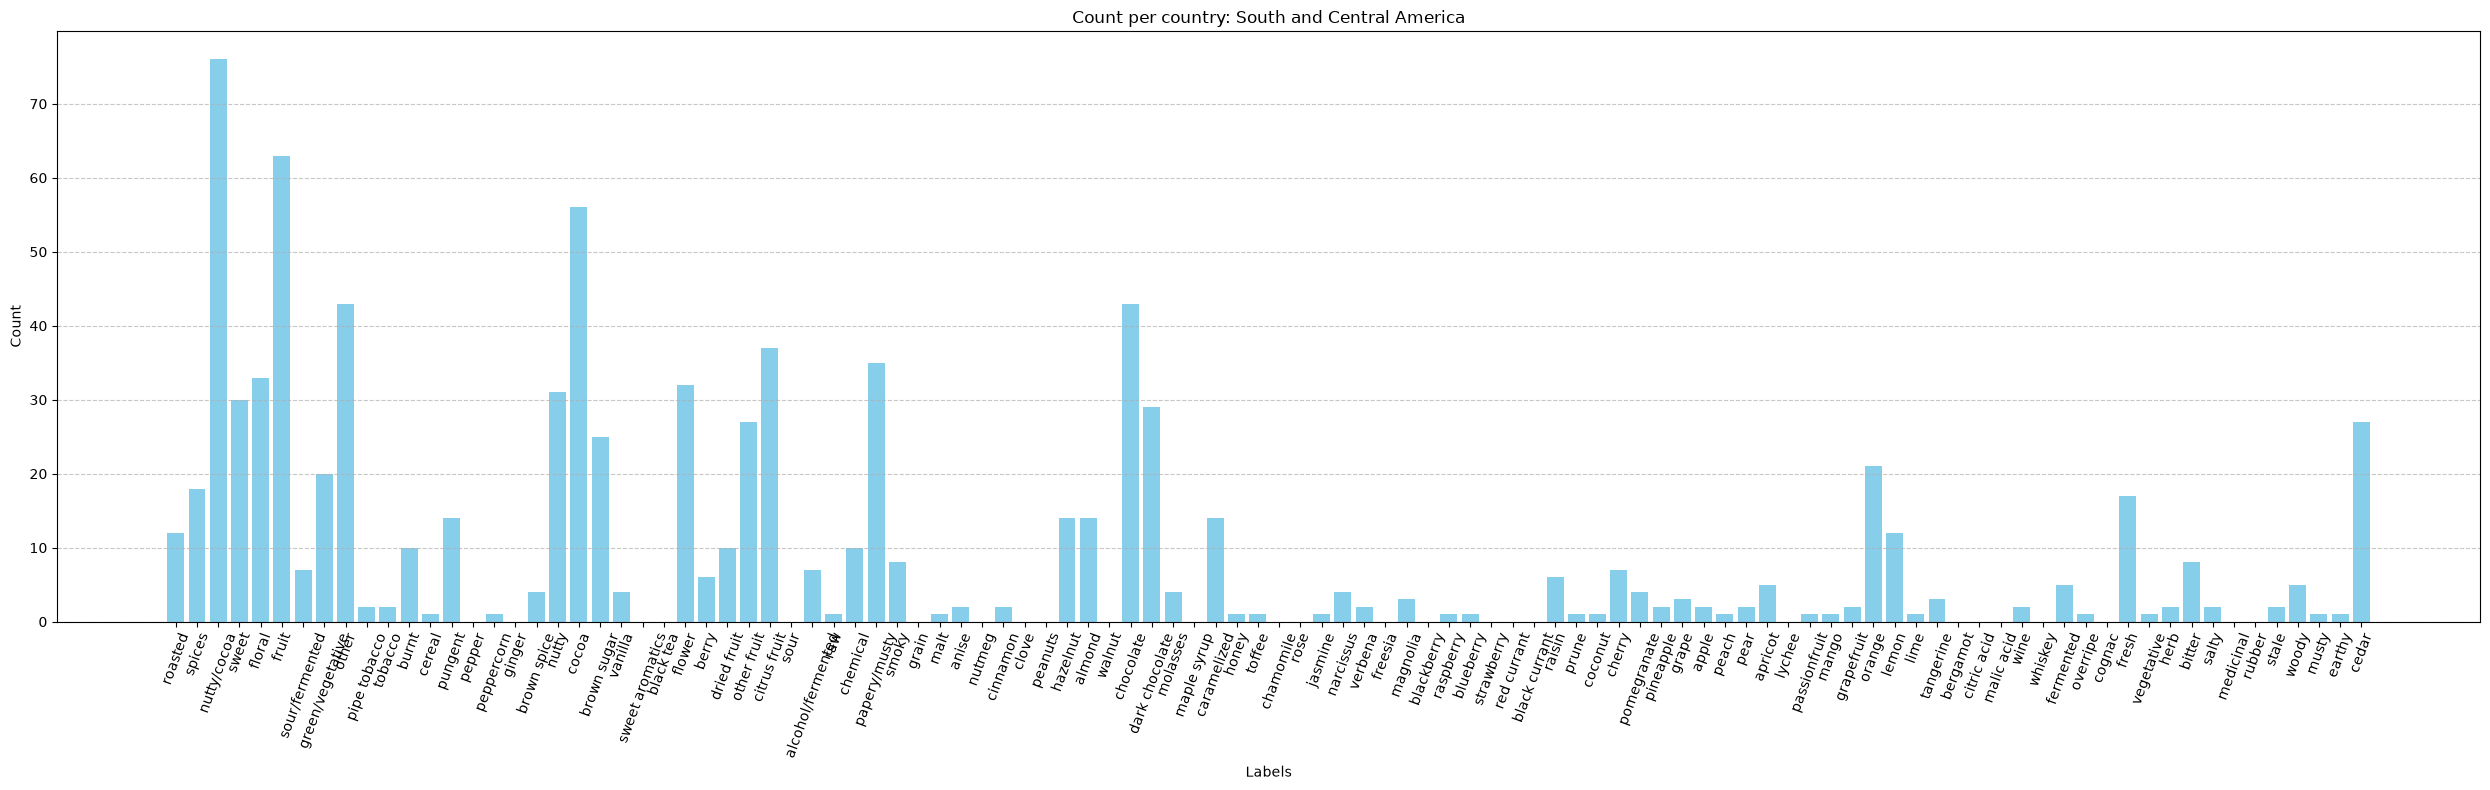

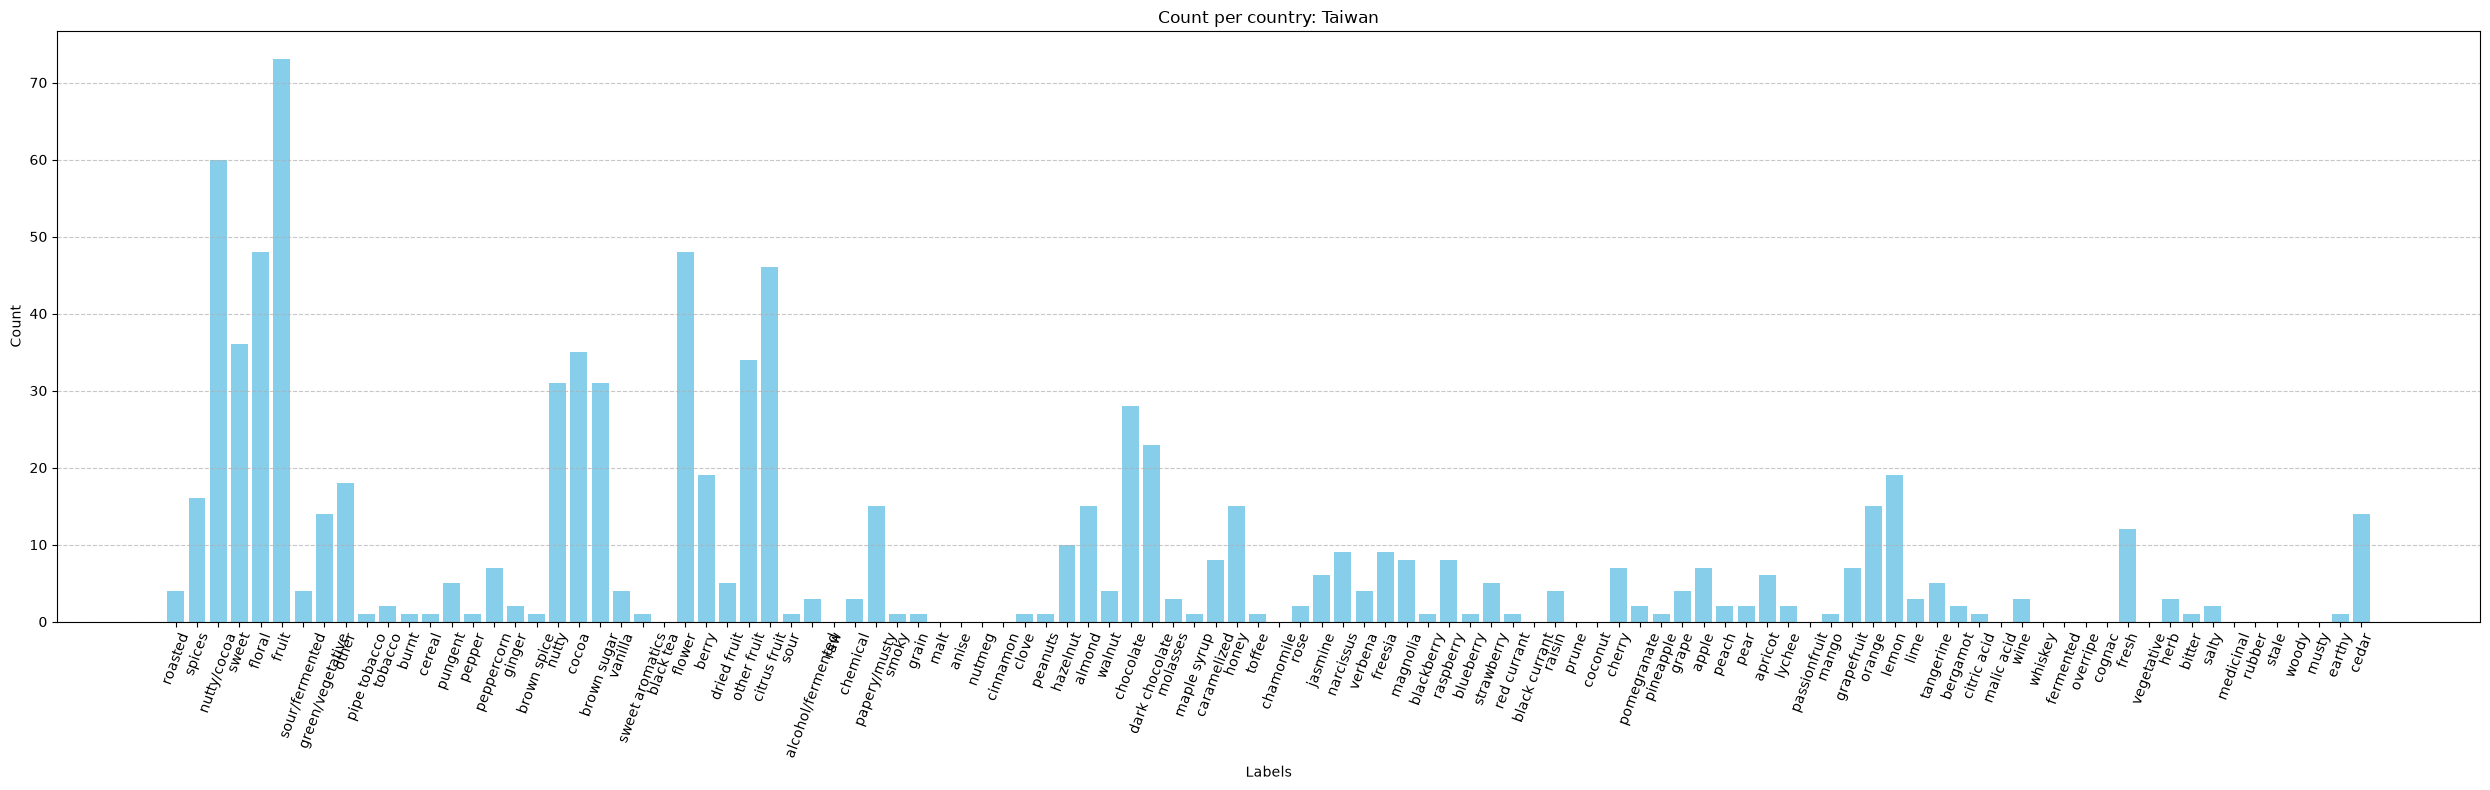

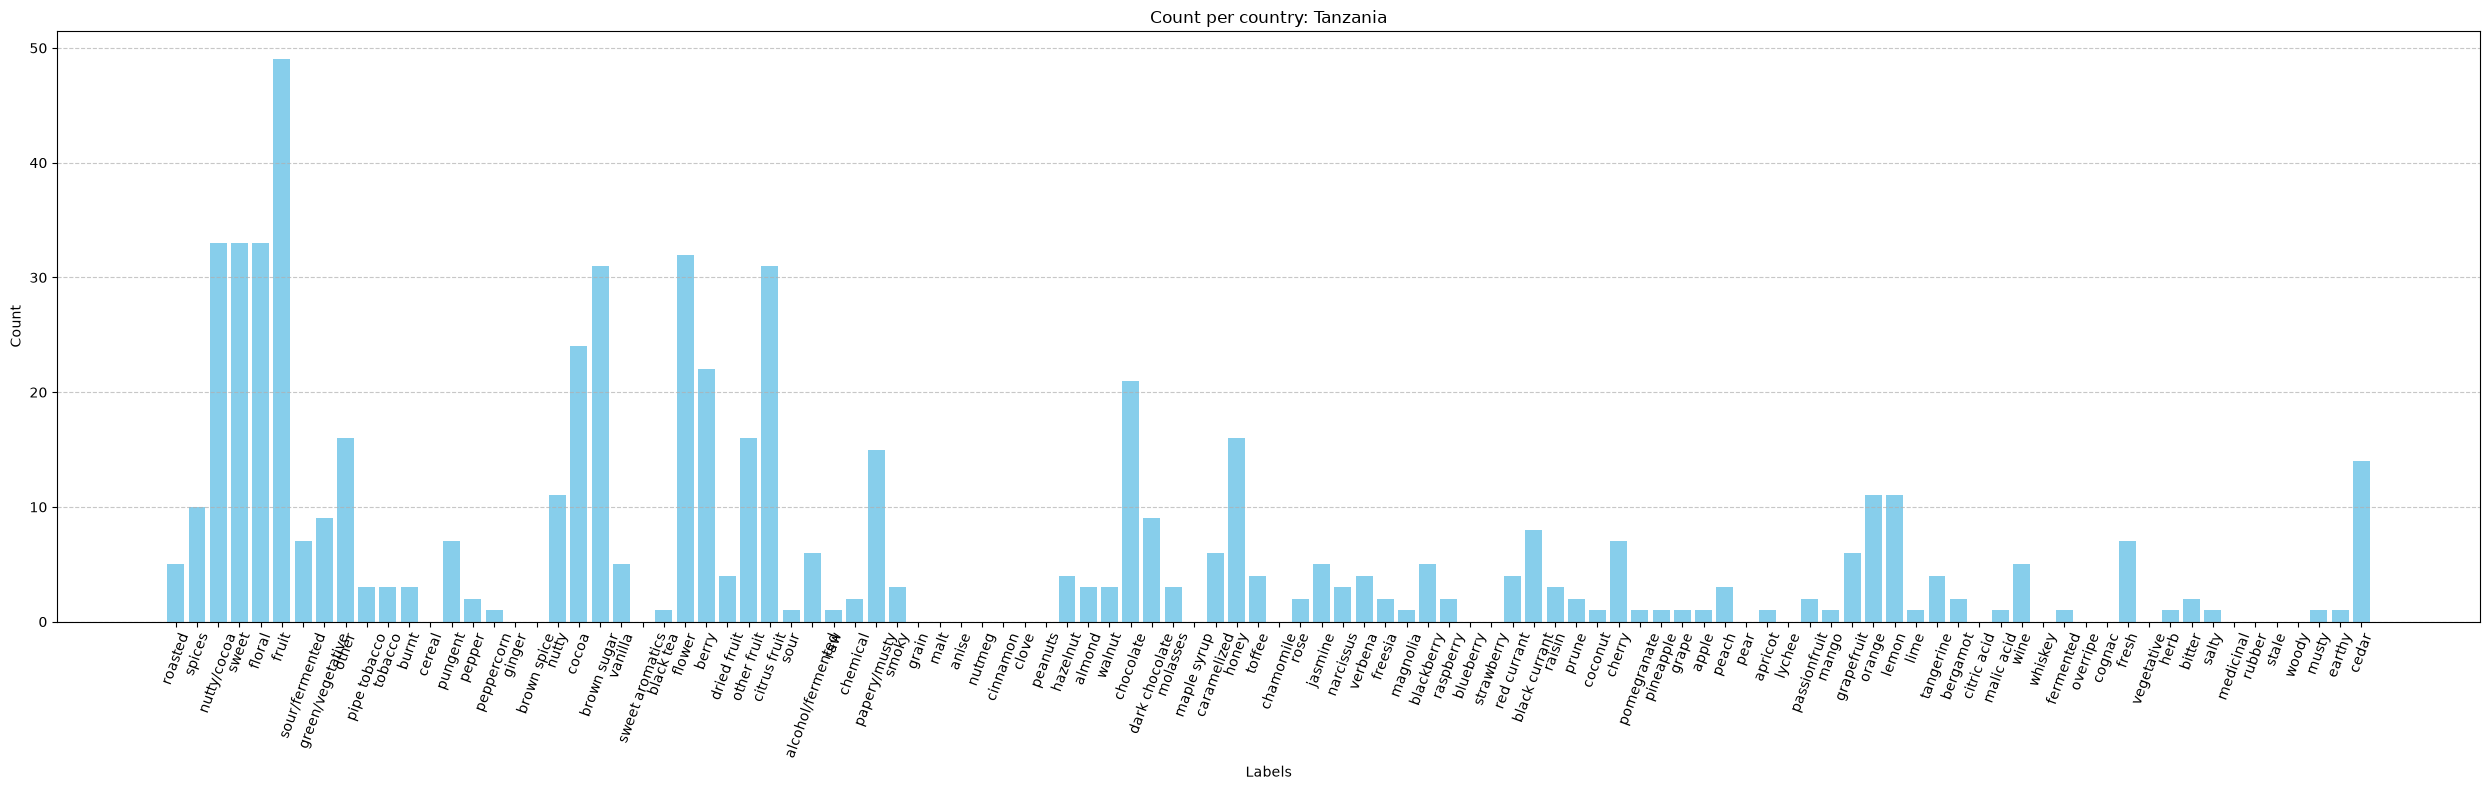

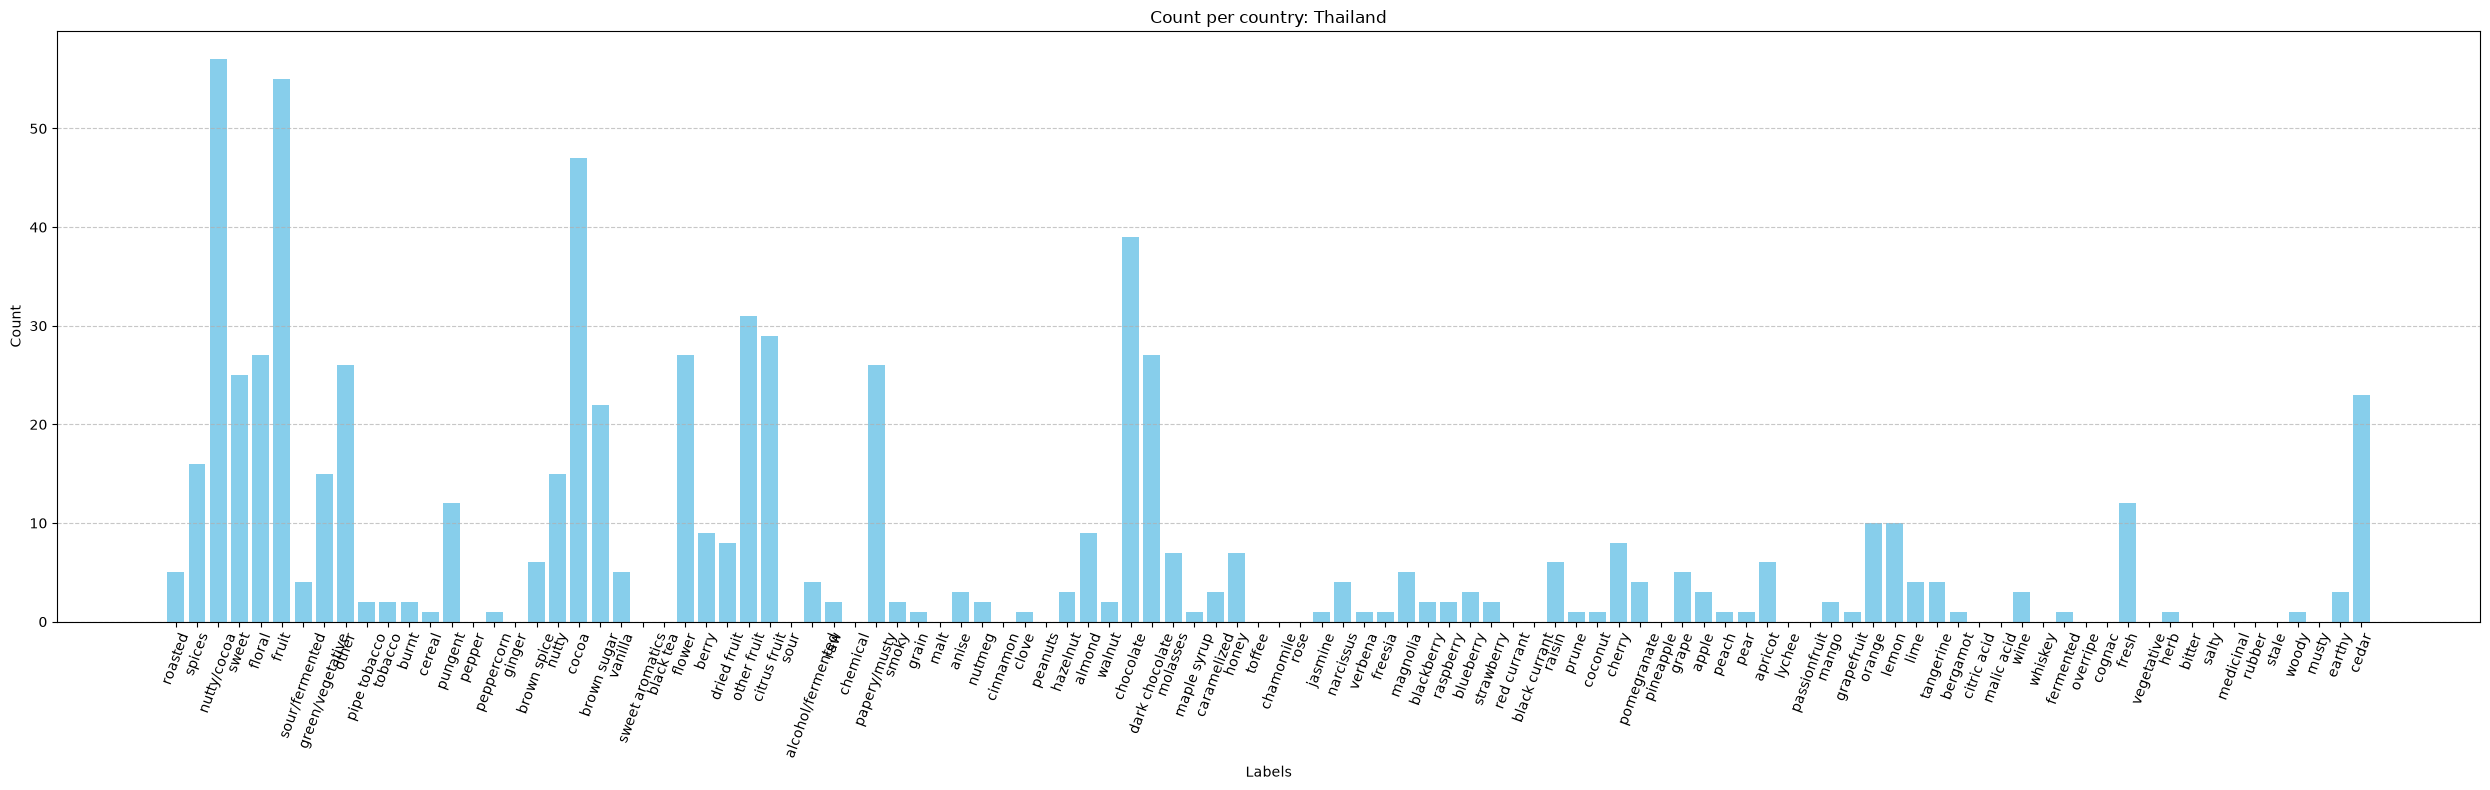

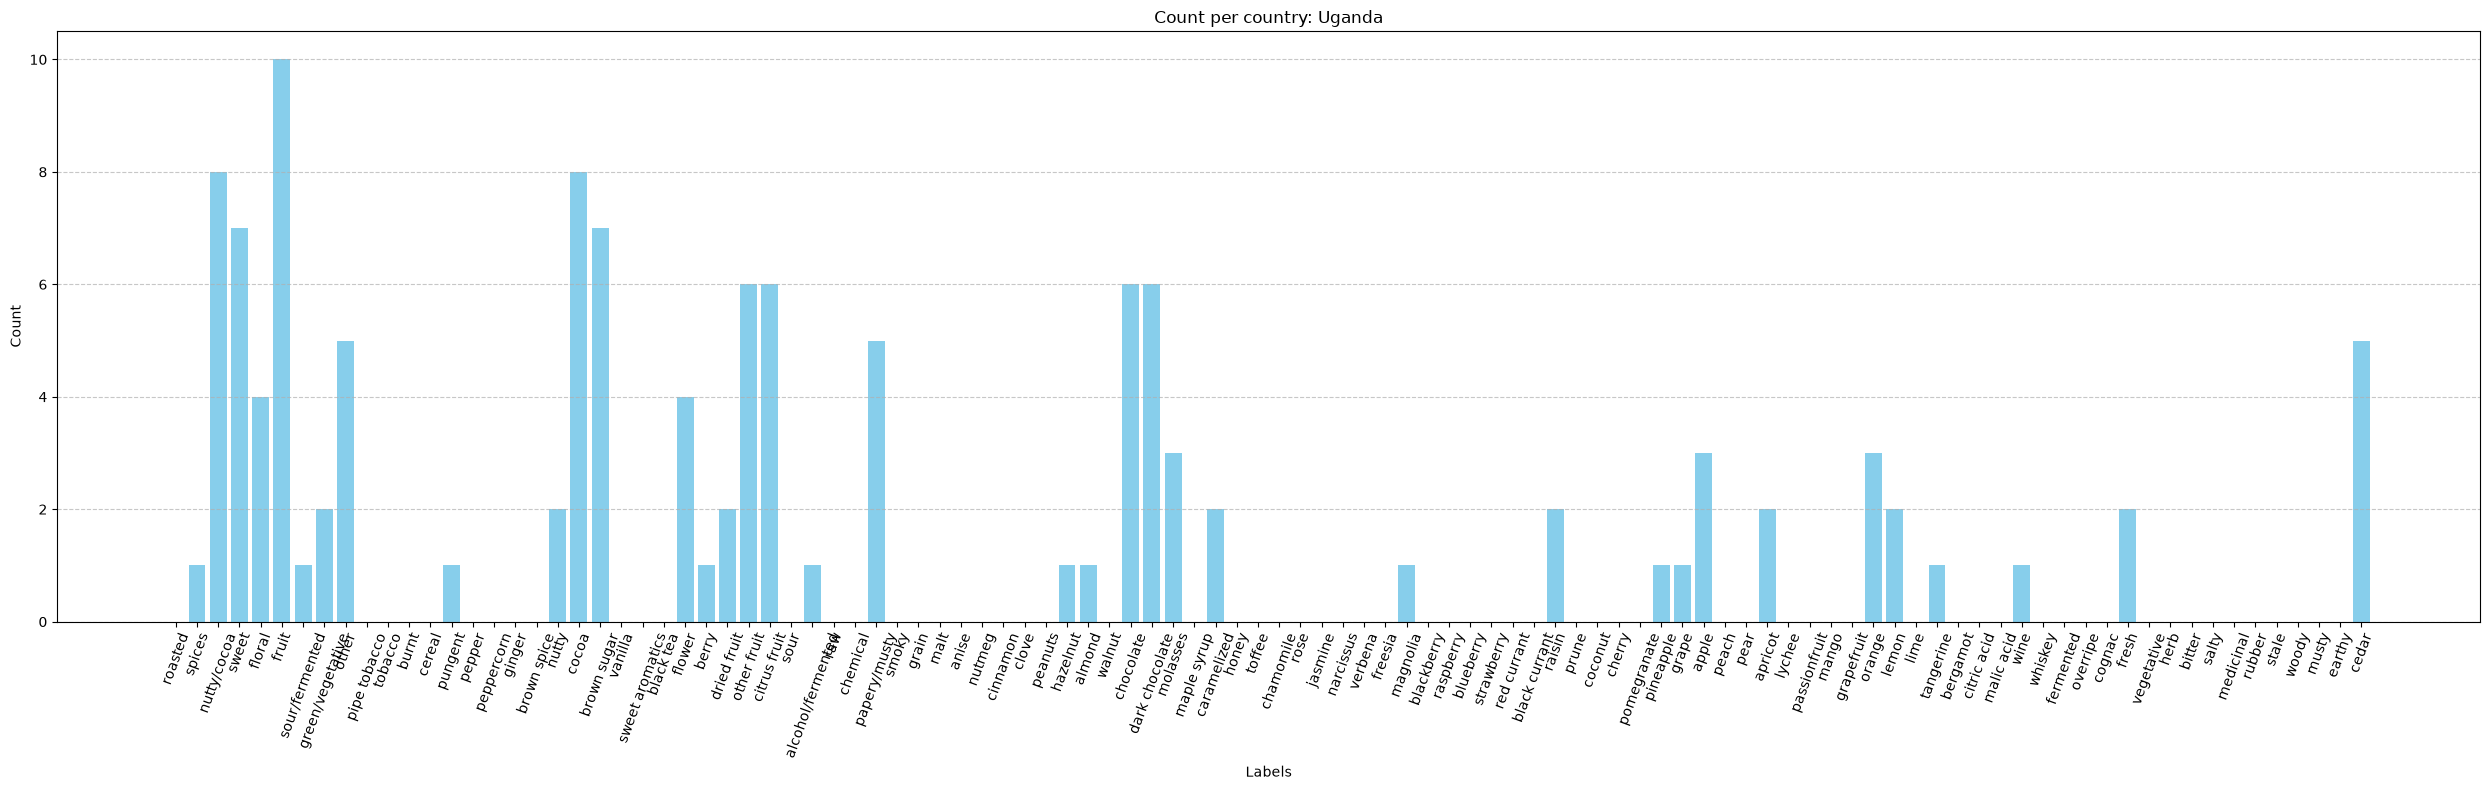

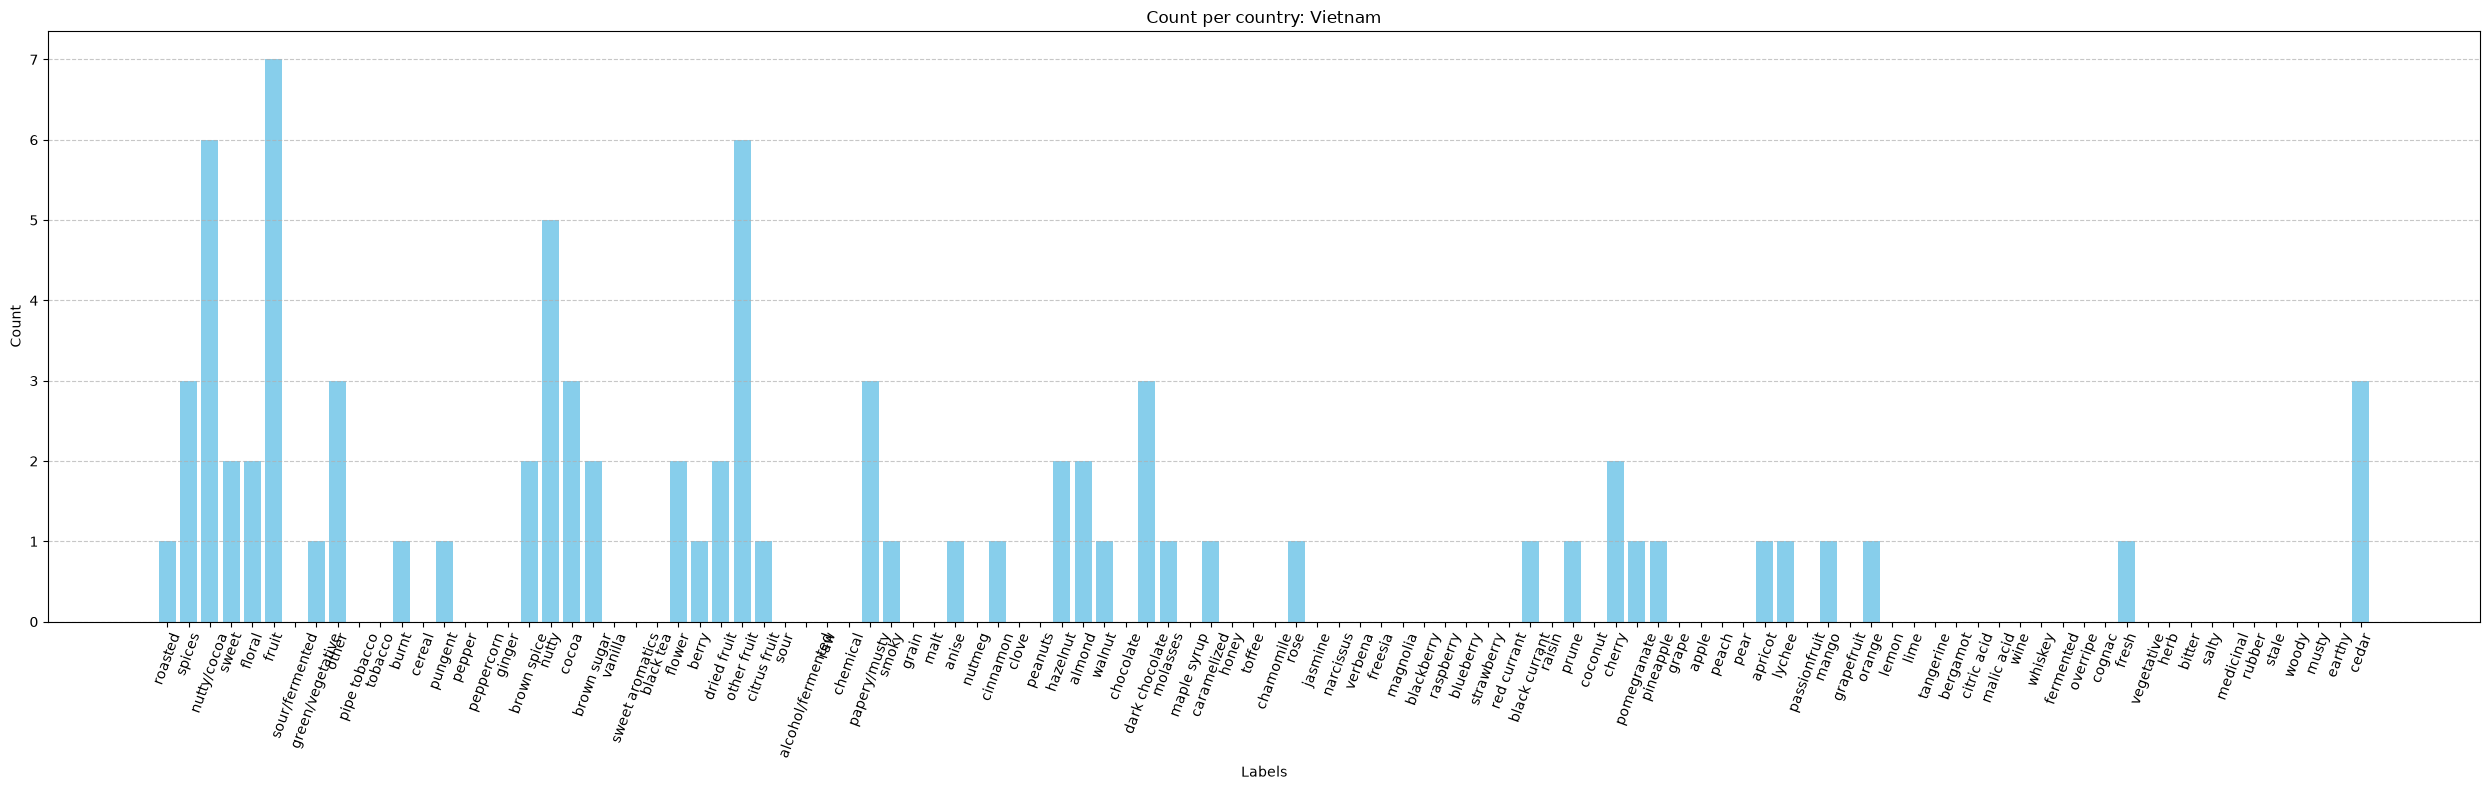

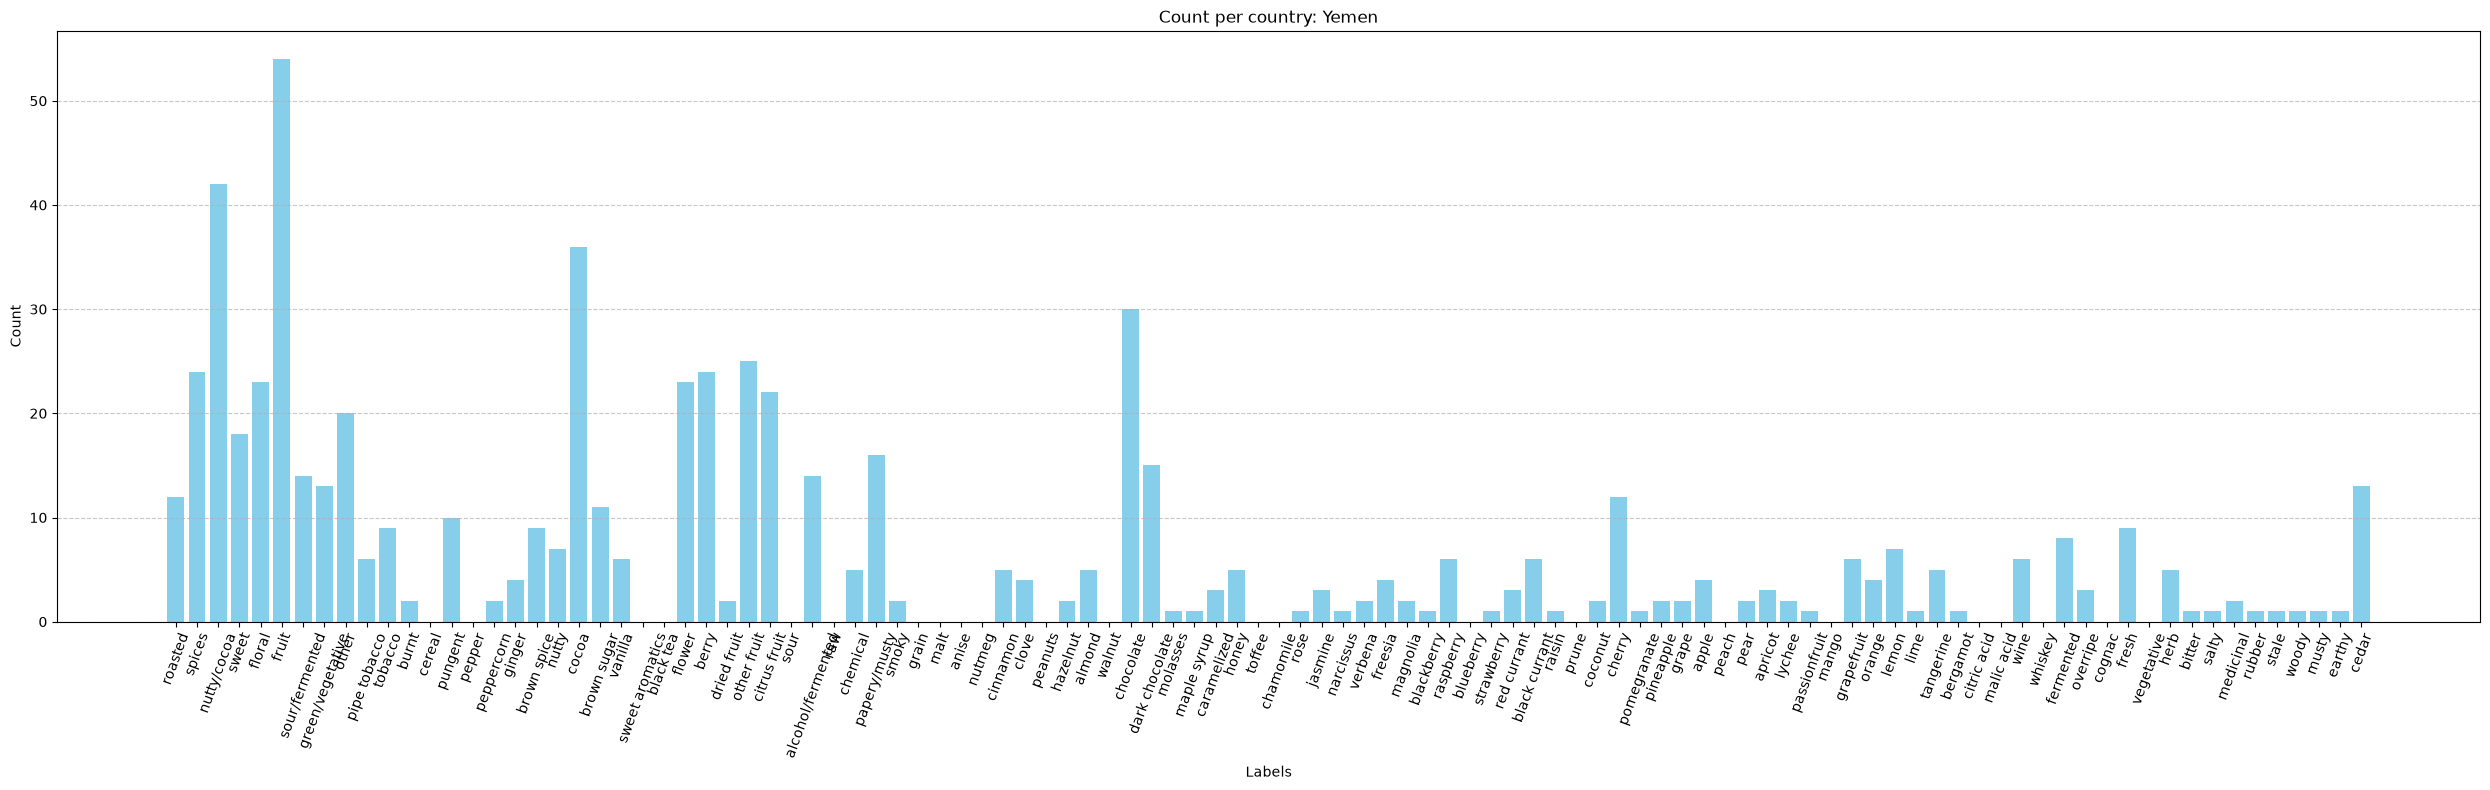

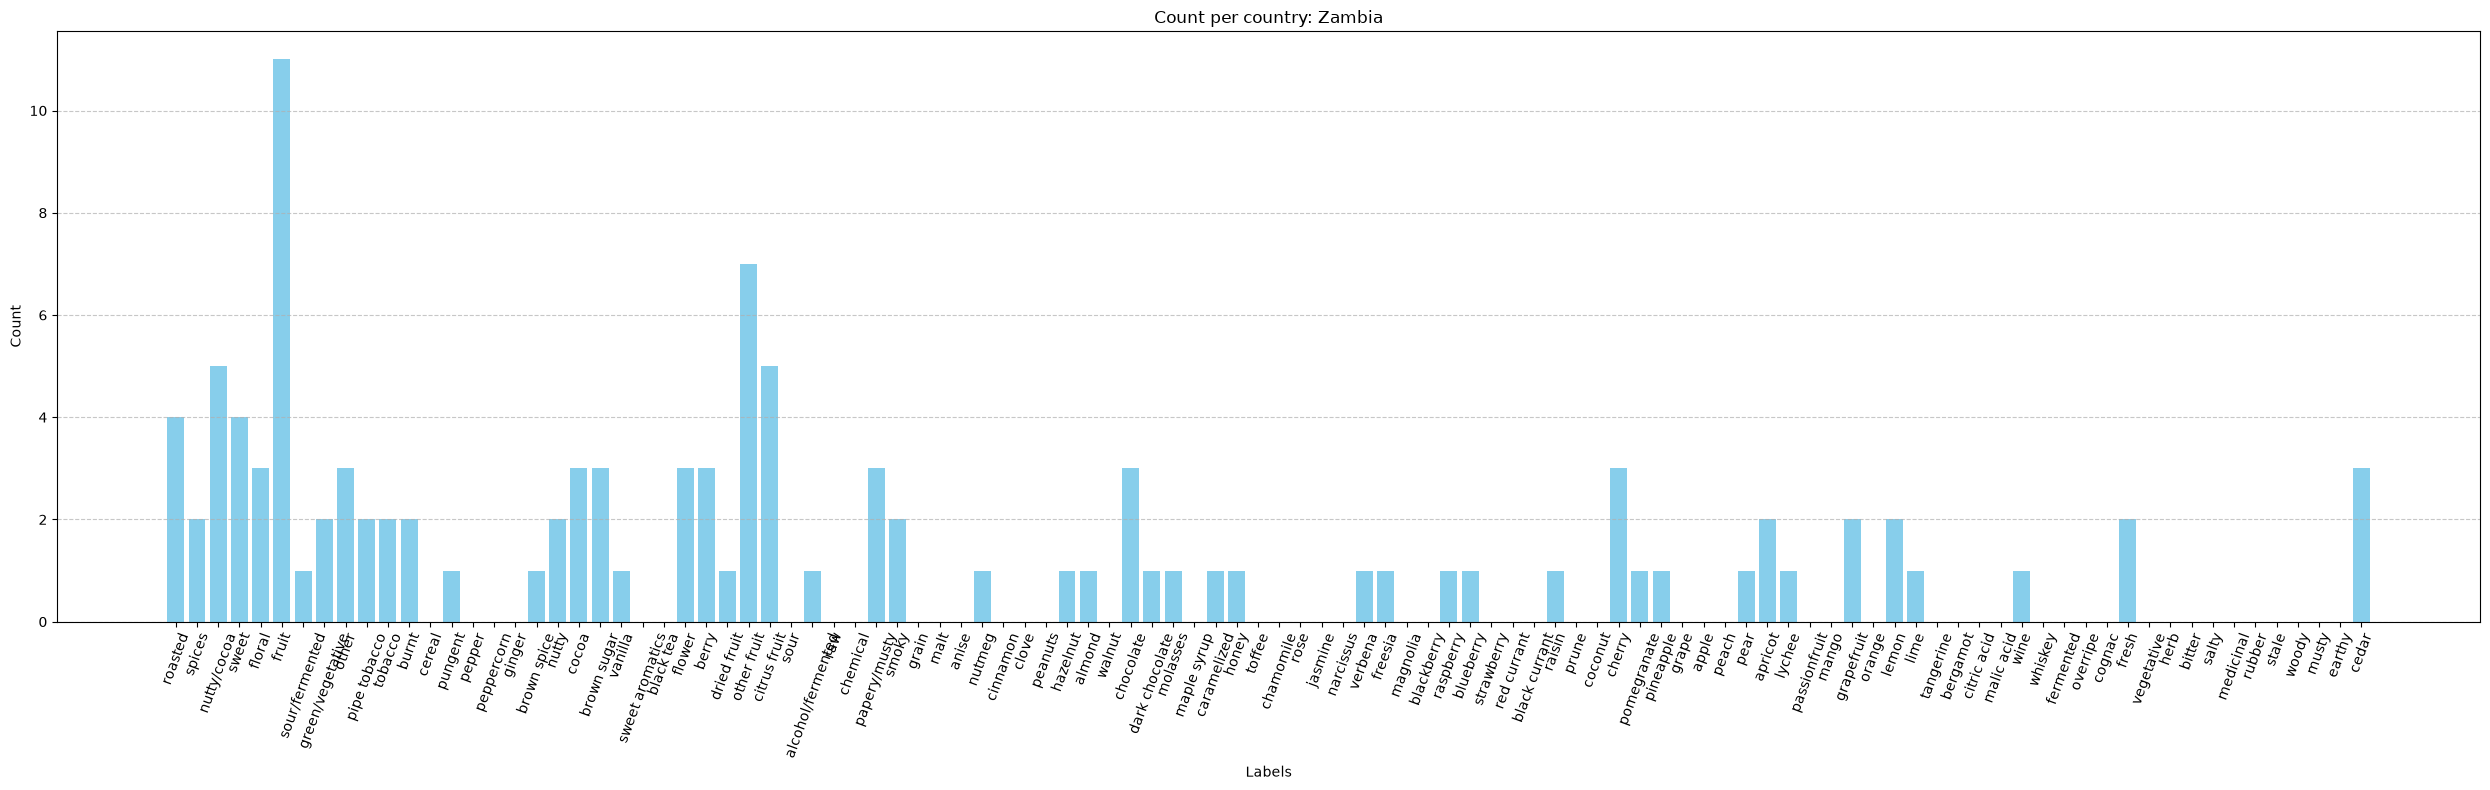

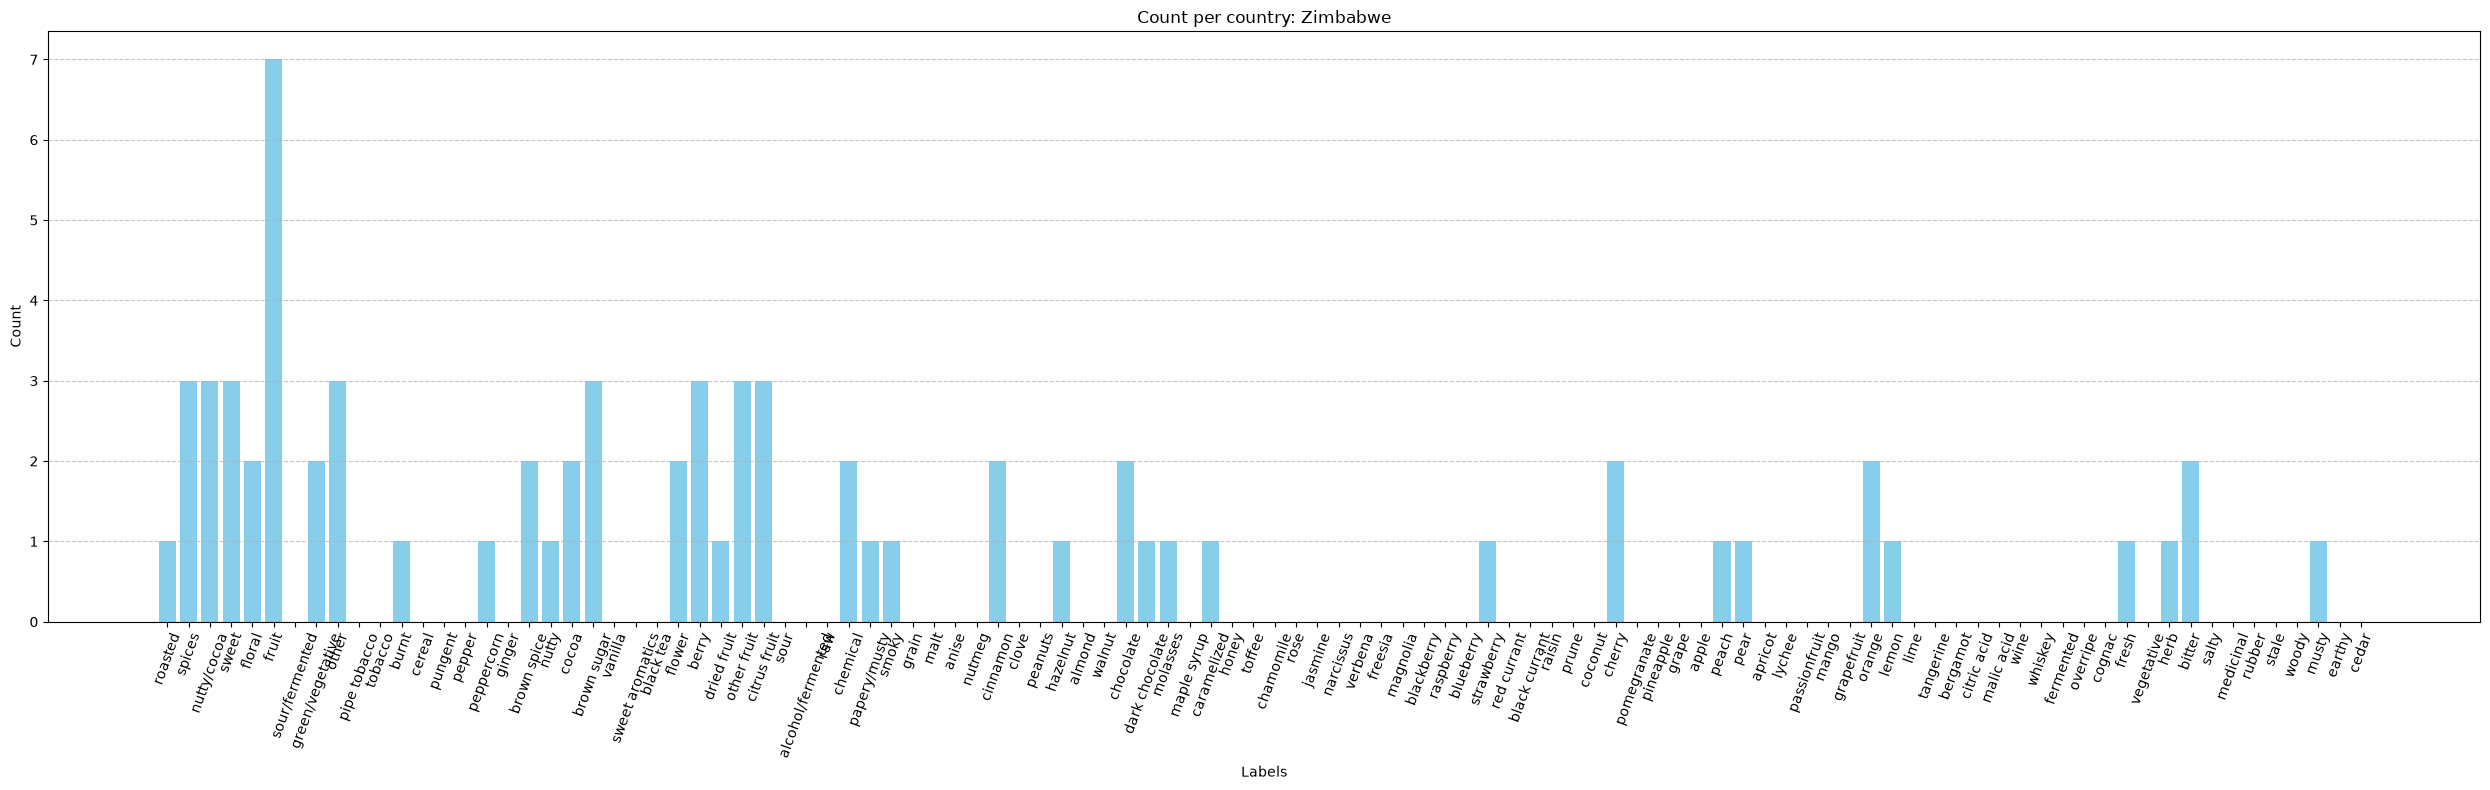

In [39]:
from matplotlib import pyplot as plt

for country, counter in country_totals.items():
    keys = list(counter.keys())
    values = list(counter.values())

    plt.figure(figsize=(25, 8))
    plt.bar(keys, values, color='skyblue')

    plt.title(f'Count per country: {country}')
    plt.xlabel('Labels')
    plt.ylabel('Count')
    plt.xticks(rotation=70)
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.show()